
# 08 — Attacker Selection and Scenario Assignment

## Overview

This notebook selects **400 unique attackers** from the eligible candidate population and assigns one approved attack scenario to each attacker.

The selection process considers scenario feasibility, behavioral familiarity, channel configuration, attack duration, switching level, stealth level, and forced off-days to achieve a diverse and behaviorally plausible attack population.

Each assignment is selected from the approved scenario catalog, ensuring consistency with the established simulation rules and the user's observed activity.

## Objectives

1. Analyze candidate flexibility, scenario availability, and configuration scarcity.
2. Evaluate behavioral familiarity and the feasibility of balanced scenario diversity.
3. Define and apply a systematic attacker selection and scenario assignment strategy.
4. Select 400 unique attackers while maintaining diversity across channel configurations, durations, switching levels, and stealth levels.
5. Validate all final assignments against the approved scenario catalog and original user activity records.
6. Export validated assignments, supporting reports, and documentation for daily attack scheduling.

## Expected Outcome

A validated, reproducible set of **400 attacker-scenario assignments**, with one approved scenario per attacker, ready for daily scheduling.



## 8.1 — Approved Inputs & Assignment Rules

### Objective

Load the validated scenario catalog and supporting outputs from Notebook 07, and establish the rules for selecting 400 unique attackers and assigning one approved scenario to each user.

### Approved Inputs

The following outputs are reused from Notebook 07:

- `feasible_scenario_catalog.parquet` — Approved user-specific scenario options.
- `scenario_types.parquet` — Supported scenario types.
- `scenario_diversity_coverage.csv` — Scenario availability and supporting-user counts.
- `scenario_catalog_qa.csv` — Previously validated catalog QA results.
- `scenario_catalog_dictionary.csv` — Catalog field definitions.
- `notebook_summary.md` — Approved methodology and handoff documentation.

### Assignment Rules

- **Attacker Population:** Exactly 400 unique users.
- **Scenario Assignment:** One approved scenario per attacker.
- **Attack Duration:** 5, 10, 20, 30, 40, or 50 eligible workdays.
- **Channel Configuration:** E+U, E+H, U+H, or E+U+H.
- **Switching Level:** Low, Medium, or High.
- **Stealth Level:** Low, Medium, or High.
- **Stealth Method:** Formula A with Balanced multipliers.
- **Behavioral Familiarity:** Consider compatibility with the user's historical channel recurrence.
- **Diversity:** Maintain meaningful representation across all four scenario dimensions.
- **Forced Off-Days:** Follow approved constraints and prefer fewer forced Off-Days.
- **Baseline:** Remains immutable.
- **Attack Period:** Approved Future period only.
- **Reproducibility:** Apply documented, deterministic selection rules.

### Procedure

1. Locate the project directory and approved Notebook 07 outputs.
2. Load the scenario catalog and supporting files.
3. Verify the required input schemas and previously approved QA status.
4. Define the assignment configuration.
5. Display the input summary and confirm readiness.

### Scope

This section performs input preparation only.

No attacker selection, scenario assignment, daily scheduling, injection, or file export is performed.

### Expected Outcome

Validated inputs and fixed assignment rules, ready for candidate flexibility and scenario scarcity analysis in Section 8.2.


In [26]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.1
# APPROVED INPUTS & ASSIGNMENT RULES
#
# Read-only | No selection | No assignment | No export
# ============================================================

from pathlib import Path

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Locate project root
# ------------------------------------------------------------

cwd_08 = Path.cwd().resolve()

root_candidates_08 = [
    cwd_08,
    *cwd_08.parents,
    cwd_08 / "New_Attack_Simulation",
    cwd_08.parent / "New_Attack_Simulation",
]

ROOT_08 = next(
    (
        path for path in root_candidates_08
        if (
            path / "reports"
            / "07_Scenario_Design_and_Feasible_Catalog"
            / "feasible_scenario_catalog.parquet"
        ).is_file()
    ),
    None,
)

if ROOT_08 is None:
    raise FileNotFoundError(
        "Project root or Notebook 07 catalog not found. "
        f"Current directory: {cwd_08}"
    )

REPORT_07_08 = (
    ROOT_08
    / "reports"
    / "07_Scenario_Design_and_Feasible_Catalog"
)

REPORT_08 = (
    ROOT_08
    / "reports"
    / "08_Attacker_Selection_and_Scenario_Assignment"
)

print("STEP 1 — Project root located: PASS")
print("ROOT:", ROOT_08)


# ------------------------------------------------------------
# STEP 2 — Locate approved inputs
# ------------------------------------------------------------

INPUT_PATHS_08 = {
    "Scenario Catalog":
        REPORT_07_08 / "feasible_scenario_catalog.parquet",

    "Scenario Types":
        REPORT_07_08 / "scenario_types.parquet",

    "Diversity Coverage":
        REPORT_07_08 / "scenario_diversity_coverage.csv",

    "Catalog QA":
        REPORT_07_08 / "scenario_catalog_qa.csv",

    "Data Dictionary":
        REPORT_07_08 / "scenario_catalog_dictionary.csv",

    "Notebook Summary":
        REPORT_07_08 / "notebook_summary.md",
}

missing_files_08 = [
    str(path)
    for path in INPUT_PATHS_08.values()
    if not path.is_file()
]

if missing_files_08:
    raise FileNotFoundError(
        "Missing approved input files:\n"
        + "\n".join(missing_files_08)
    )

print("\nSTEP 2 — Approved input files located: PASS")


# ------------------------------------------------------------
# STEP 3 — Load approved outputs
# ------------------------------------------------------------

scenario_catalog_08 = pd.read_parquet(
    INPUT_PATHS_08["Scenario Catalog"]
)

scenario_types_08 = pd.read_parquet(
    INPUT_PATHS_08["Scenario Types"]
)

scenario_coverage_08 = pd.read_csv(
    INPUT_PATHS_08["Diversity Coverage"]
)

catalog_qa_08 = pd.read_csv(
    INPUT_PATHS_08["Catalog QA"]
)

scenario_dictionary_08 = pd.read_csv(
    INPUT_PATHS_08["Data Dictionary"],
    keep_default_na=False,
)

notebook_07_summary_08 = (
    INPUT_PATHS_08["Notebook Summary"]
    .read_text(encoding="utf-8")
)

print("\nSTEP 3 — Approved outputs loaded: PASS")


# ------------------------------------------------------------
# STEP 4 — Validate input readiness
# ------------------------------------------------------------

required_catalog_cols_08 = {
    "scenario_option_id",
    "scenario_type_id",
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "channel_configuration",
    "channel_count",
    "switching_level",
    "stealth_level",
    "stealth_multiplier",
    "formula_id",
    "multiplier_configuration",
    "forced_offdays",
    "proposed_active_days",
    "set_switch_bitmask",
    "proof_source",
    "catalog_status",
}

required_type_cols_08 = {
    "scenario_type_id",
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
}

required_coverage_cols_08 = (
    required_type_cols_08
    | {"supporting_users", "available_options"}
)

for name, dataframe, required in [
    (
        "Scenario Catalog",
        scenario_catalog_08,
        required_catalog_cols_08,
    ),
    (
        "Scenario Types",
        scenario_types_08,
        required_type_cols_08,
    ),
    (
        "Diversity Coverage",
        scenario_coverage_08,
        required_coverage_cols_08,
    ),
]:
    missing = required - set(dataframe.columns)

    if missing:
        raise ValueError(
            f"{name} missing columns: {sorted(missing)}"
        )

# Confirm previously approved handoff totals.
assert len(scenario_catalog_08) == 2_360_793
assert scenario_catalog_08["user"].nunique() == 936

assert len(scenario_types_08) == 213
assert len(scenario_coverage_08) == 213

# Reuse Notebook 07 QA instead of repeating its checks.
assert len(catalog_qa_08) == 33
assert catalog_qa_08["Status"].eq("PASS").all()

print("\nSTEP 4 — Input readiness: PASS")
print("Notebook 07 QA: 33/33 PASS")


# ------------------------------------------------------------
# STEP 5 — Define approved assignment rules
# ------------------------------------------------------------

ASSIGNMENT_RULES_08 = {
    "target_attackers": 400,

    "one_scenario_per_user": True,

    "durations": [5, 10, 20, 30, 40, 50],

    "channel_configurations": [
        "E+U", "E+H", "U+H", "E+U+H"
    ],

    "switching_levels": ["Low", "Medium", "High"],

    "stealth_levels": ["Low", "Medium", "High"],

    "stealth_formula": "A",

    "multiplier_configuration": "Balanced",

    "stealth_multipliers": {
        "High": 0.25,
        "Medium": 0.50,
        "Low": 0.75,
    },

    "baseline_start": "2010-01-02",
    "baseline_end": "2010-12-31",

    "future_start": "2011-01-01",
    "future_end": "2011-06-01",

    "allow_optional_offdays": False,
    "prefer_fewer_forced_offdays": True,

    "require_catalog_provenance": True,

    "daily_schedule_in_scope": False,
    "injection_in_scope": False,
}

assert (
    ASSIGNMENT_RULES_08["target_attackers"]
    <= scenario_catalog_08["user"].nunique()
)

print("\nSTEP 5 — Assignment rules established: PASS")


# ------------------------------------------------------------
# STEP 6 — Display input summary
# ------------------------------------------------------------

input_summary_08 = pd.DataFrame([
    {
        "Dataset": "Feasible Scenario Catalog",
        "Rows": len(scenario_catalog_08),
        "Columns": len(scenario_catalog_08.columns),
    },
    {
        "Dataset": "Scenario Types",
        "Rows": len(scenario_types_08),
        "Columns": len(scenario_types_08.columns),
    },
    {
        "Dataset": "Diversity Coverage",
        "Rows": len(scenario_coverage_08),
        "Columns": len(scenario_coverage_08.columns),
    },
])

print("\nAPPROVED INPUT SUMMARY")
display(input_summary_08)

print("\nCATALOG SAMPLE")
display(
    scenario_catalog_08[
        [
            "scenario_option_id",
            "user",
            "window_workdays",
            "channel_configuration",
            "switching_level",
            "stealth_level",
            "forced_offdays",
        ]
    ].head()
)


# ------------------------------------------------------------
# STEP 7 — Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.1 SUMMARY")
print("=" * 65)

print(
    "Approved scenario options :",
    f"{len(scenario_catalog_08):,}"
)

print(
    "Supported scenario types  :",
    len(scenario_types_08)
)

print(
    "Eligible candidate users  :",
    scenario_catalog_08["user"].nunique()
)

print(
    "Target attackers          :",
    ASSIGNMENT_RULES_08["target_attackers"]
)

print("Previous catalog QA       : 33/33 PASS")
print("Assignment rules          : DEFINED")
print("Attacker selection        : NOT STARTED")
print("Scenario assignment       : NOT STARTED")
print("Files saved               : NO")
print("Original files modified   : NO")

print("=" * 65)
print("SECTION 8.1 — PASS")


STEP 1 — Project root located: PASS
ROOT: C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation

STEP 2 — Approved input files located: PASS

STEP 3 — Approved outputs loaded: PASS

STEP 4 — Input readiness: PASS
Notebook 07 QA: 33/33 PASS

STEP 5 — Assignment rules established: PASS

APPROVED INPUT SUMMARY


,Dataset,Rows,Columns
0,Feasible Scenario Catalog,2360793,18
1,Scenario Types,213,5
2,Diversity Coverage,213,7



CATALOG SAMPLE


,scenario_option_id,user,window_workdays,channel_configuration,switching_level,stealth_level,forced_offdays
0,1,AAC0610,5,E+U,High,High,0
1,2,AAC0610,5,E+U,High,Low,0
2,3,AAC0610,5,E+U,High,Medium,0
3,4,AAC0610,5,E+U,Low,High,0
4,5,AAC0610,5,E+U,Low,Low,0



NOTEBOOK 08 — SECTION 8.1 SUMMARY
Approved scenario options : 2,360,793
Supported scenario types  : 213
Eligible candidate users  : 936
Target attackers          : 400
Previous catalog QA       : 33/33 PASS
Assignment rules          : DEFINED
Attacker selection        : NOT STARTED
Scenario assignment       : NOT STARTED
Files saved               : NO
Original files modified   : NO
SECTION 8.1 — PASS



## 8.2 — Candidate Flexibility & Scenario Scarcity

### Objective

Analyze the flexibility of eligible users and the availability of approved scenario configurations before attacker selection.

### Analysis

1. **Candidate Flexibility:** Measure the number of approved scenario options, supported channel configurations, attack durations, switching levels, and stealth levels available to each user.
2. **Channel Availability:** Identify how many unique users can support each channel configuration.
3. **Configuration Scarcity:** Compare the availability of two-channel and three-channel scenarios to identify configurations with limited candidate support.
4. **Scenario-Type Scarcity:** Examine how many users support each approved scenario type.

### Selection Implications

Users may qualify for multiple configurations. Therefore, assigning a flexible user to one configuration can reduce the available candidate pool for another.

Scarce configurations should be considered during selection to preserve scenario diversity without sacrificing feasibility.

### Expected Outcome

A clear understanding of candidate flexibility and scenario scarcity to guide the attacker selection strategy.

No attackers are selected, and no files are modified or exported.


In [27]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.2
# CANDIDATE FLEXIBILITY & SCENARIO SCARCITY
#
# Read-only | No selection | No export
# ============================================================

import pandas as pd
from IPython.display import display

catalog_082 = scenario_catalog_08

# ------------------------------------------------------------
# STEP 1 — Candidate flexibility
# ------------------------------------------------------------

candidate_flexibility_08 = (
    catalog_082.groupby("user")
    .agg(
        available_options=("scenario_option_id", "nunique"),
        channel_configurations=("channel_configuration", "nunique"),
        available_durations=("window_workdays", "nunique"),
        switching_levels=("switching_level", "nunique"),
        stealth_levels=("stealth_level", "nunique"),
    )
    .reset_index()
)

assert len(candidate_flexibility_08) == 936
assert candidate_flexibility_08["user"].is_unique

print("STEP 1 — Candidate flexibility analyzed: PASS")

display(
    candidate_flexibility_08[
        [
            "available_options",
            "channel_configurations",
            "available_durations",
            "switching_levels",
            "stealth_levels",
        ]
    ].describe().round(2)
)


# ------------------------------------------------------------
# STEP 2 — Channel configuration availability
# ------------------------------------------------------------

config_order_082 = ["E+U", "E+H", "U+H", "E+U+H"]

channel_availability_08 = (
    catalog_082.groupby("channel_configuration")
    .agg(
        supporting_users=("user", "nunique"),
        available_options=("scenario_option_id", "nunique"),
        scenario_types=("scenario_type_id", "nunique"),
    )
    .reindex(config_order_082)
    .reset_index()
)

assert channel_availability_08["supporting_users"].notna().all()

print("\nSTEP 2 — Channel availability")
display(channel_availability_08)


# ------------------------------------------------------------
# STEP 3 — User flexibility across channel configurations
# ------------------------------------------------------------

user_channel_matrix_08 = (
    catalog_082[
        ["user", "channel_configuration"]
    ]
    .drop_duplicates()
    .assign(eligible=True)
    .pivot(
        index="user",
        columns="channel_configuration",
        values="eligible",
    )
    .reindex(columns=config_order_082, fill_value=False)
    .fillna(False)
    .astype(bool)
)

user_channel_matrix_08["configuration_count"] = (
    user_channel_matrix_08[config_order_082].sum(axis=1)
)

configuration_flexibility_08 = (
    user_channel_matrix_08["configuration_count"]
    .value_counts()
    .sort_index()
    .rename_axis("supported_configurations")
    .reset_index(name="users")
)

print("\nSTEP 3 — Number of configurations supported per user")
display(configuration_flexibility_08)

triple_eligible_users_08 = set(
    user_channel_matrix_08.index[
        user_channel_matrix_08["E+U+H"]
    ]
)

print(
    "Users supporting E+U+H:",
    len(triple_eligible_users_08)
)


# ------------------------------------------------------------
# STEP 4 — Scenario-type scarcity
# ------------------------------------------------------------

scenario_type_scarcity_08 = (
    catalog_082.groupby(
        [
            "scenario_type_id",
            "window_workdays",
            "channel_configuration",
            "switching_level",
            "stealth_level",
        ]
    )
    .agg(
        supporting_users=("user", "nunique"),
        available_options=("scenario_option_id", "nunique"),
    )
    .reset_index()
    .sort_values(
        ["supporting_users", "available_options", "scenario_type_id"]
    )
    .reset_index(drop=True)
)

assert (
    scenario_type_scarcity_08["scenario_type_id"].nunique()
    == len(scenario_types_08)
)

print("\nSTEP 4 — Ten least-supported scenario types")
display(scenario_type_scarcity_08.head(10))


# ------------------------------------------------------------
# STEP 5 — Integrity checks and summary
# ------------------------------------------------------------

assert candidate_flexibility_08["user"].nunique() == 936
assert len(user_channel_matrix_08) == 936

assert (
    channel_availability_08["available_options"].sum()
    == len(catalog_082)
)

assert (
    scenario_type_scarcity_08["available_options"].sum()
    == len(catalog_082)
)

assert (
    set(triple_eligible_users_08)
    .issubset(set(candidate_flexibility_08["user"]))
)

print("\n" + "=" * 62)
print("NOTEBOOK 08 — SECTION 8.2 SUMMARY")
print("=" * 62)

print("Eligible users             :", len(candidate_flexibility_08))
print("Approved scenario options  :", f"{len(catalog_082):,}")
print("Scenario types             :", len(scenario_type_scarcity_08))
print("Supported configurations   :", len(config_order_082))
print("E+U+H eligible users       :", len(triple_eligible_users_08))
print(
    "Least-supported type       :",
    int(scenario_type_scarcity_08["supporting_users"].min()),
    "users"
)
print("Attackers selected         : 0")
print("Files saved                : NO")
print("Original files modified    : NO")
print("=" * 62)
print("SECTION 8.2 — PASS")


STEP 1 — Candidate flexibility analyzed: PASS


,available_options,channel_configurations,available_durations,switching_levels,stealth_levels
count,936.00,936.00,936.00,936.00,936.0
mean,2522.21,1.71,5.41,2.91,3.0
std,2023.48,1.15,1.39,0.35,0.0
min,3.00,1.00,1.00,1.00,3.0
25%,987.00,1.00,6.00,3.00,3.0
50%,2379.00,1.00,6.00,3.00,3.0
75%,3511.50,3.00,6.00,3.00,3.0
max,10839.00,4.00,6.00,3.00,3.0



STEP 2 — Channel availability


,channel_configuration,supporting_users,available_options,scenario_types
0,E+U,658,1188135,54
1,E+H,505,573408,54
2,U+H,159,59445,54
3,E+U+H,281,539805,51



STEP 3 — Number of configurations supported per user


,supported_configurations,users
0,1,659
1,2,15
2,3,134
3,4,128


Users supporting E+U+H: 281

STEP 4 — Ten least-supported scenario types


,scenario_type_id,window_workdays,channel_configuration,switching_level,stealth_level,supporting_users,available_options
0,205,50,U+H,High,High,4,72
1,206,50,U+H,High,Low,4,72
2,207,50,U+H,High,Medium,4,72
3,169,40,U+H,High,High,7,81
4,170,40,U+H,High,Low,7,81
5,171,40,U+H,High,Medium,7,81
6,133,30,U+H,High,High,13,145
7,134,30,U+H,High,Low,13,145
8,135,30,U+H,High,Medium,13,145
9,211,50,U+H,Medium,High,18,717



NOTEBOOK 08 — SECTION 8.2 SUMMARY
Eligible users             : 936
Approved scenario options  : 2,360,793
Scenario types             : 213
Supported configurations   : 4
E+U+H eligible users       : 281
Least-supported type       : 4 users
Attackers selected         : 0
Files saved                : NO
Original files modified    : NO
SECTION 8.2 — PASS



### 8.3.1 — User-Specific Behavioral Familiarity Assessment

#### Objective

Evaluate how closely each approved user-window-channel configuration aligns with the user's historical channel-use recurrence.

#### Approved Inputs

- **Notebook 01:** Historical eligible workday counts.
- **Notebook 03:** Historical channel-active days and baseline references.
- **Notebook 05:** Natural channel-active days and switching summaries for approved Future windows.
- **Notebook 07:** Validated scenario options.

#### Methodology

1. Reuse previously computed Baseline and Future window summaries.
2. Calculate the historical and window channel-active-day rates.
3. Measure the recurrence gap in percentage points for each selected channel.
4. Summarize the maximum absolute recurrence gap for each approved window.
5. Identify the best available behavioral familiarity for each user and core scenario configuration.
6. Retain the results for subsequent scenario evaluation.

#### Interpretation

Smaller recurrence gaps indicate that a candidate window's natural channel-use frequency is closer to the user's historical behavior.

Behavioral familiarity is a supporting selection criterion, not a mandatory threshold or proof of attack stealth.

Comparisons involving different channel configurations must account for the channels included in each calculation.

#### Constraints

- No Baseline recalculation.
- No switching feasibility recalculation.
- No arbitrary familiarity thresholds.
- No attacker selection or assignment.
- No modification of source files.
- No file exports.

#### Expected Outcome

A window-level behavioral familiarity profile and a user-core summary supporting the next selection stages.


STEP 1 — Approved behavioral sources located: PASS
STEP 2 — Historical and Future summaries loaded: PASS
STEP 3 — Historical recurrence references prepared: PASS
STEP 4 — Approved windows linked: PASS
STEP 5 — Behavioral recurrence gaps calculated: PASS
STEP 6 — User-core familiarity summaries prepared: PASS

WINDOW-LEVEL RECURRENCE GAP


,max_abs_recurrence_gap_pp,max_positive_recurrence_increase_pp
count,360466.00,360466.00
mean,12.47,9.24
std,8.47,9.45
min,0.01,0.00
25%,6.54,1.51
50%,10.59,6.87
75%,16.18,13.75
max,84.86,84.86



USER-CORE FAMILIARITY


,available_windows,best_recurrence_gap_pp,median_recurrence_gap_pp
count,20281.00,20281.00,20281.00
mean,38.80,7.60,14.95
std,27.46,9.08,10.16
min,1.00,0.01,0.31
25%,13.00,2.17,8.05
50%,37.00,4.54,12.03
75%,62.00,8.92,18.67
max,103.00,84.86,84.86


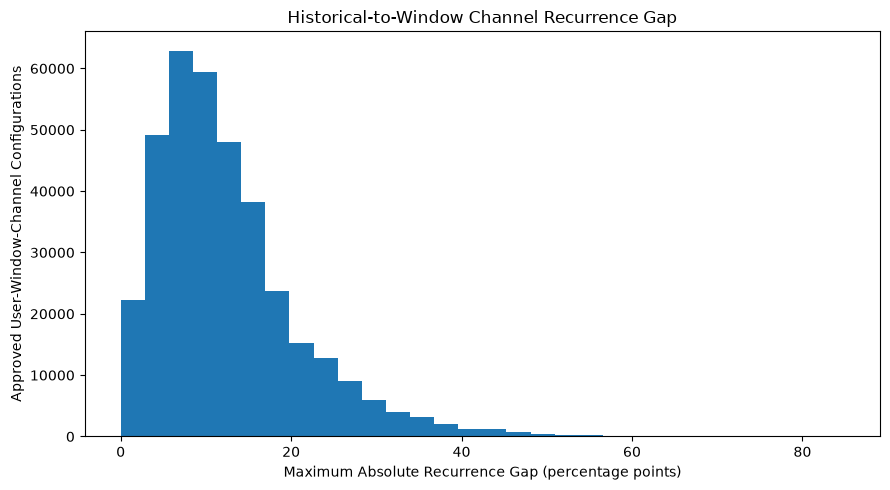


NOTEBOOK 08 — SECTION 8.3.1 SUMMARY
Window-channel profiles : 360,466
User-core profiles      : 20,281
Historical references   : VALID
Baseline recalculated   : NO
Switching recalculated  : NO
Attackers selected      : 0
Files saved             : NO
Original files modified : NO
SECTION 8.3.1 — PASS


In [28]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.3.1
# USER-SPECIFIC BEHAVIORAL FAMILIARITY
#
# Reuse approved summaries | Read-only | No exports
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Locate approved behavioral summaries
# ------------------------------------------------------------

reports_0831 = ROOT_08 / "reports"

paths_0831 = {
    "population": (
        reports_0831 / "01_User_Population_Audit"
        / "user_population_profile.parquet"
    ),
    "frequency": (
        reports_0831 / "03_Channel_Behavior_Audit"
        / "user_channel_frequency_comparison.parquet"
    ),
    "windows": (
        reports_0831 / "05_Simulation_Rules_Feasibility"
        / "02_Switching"
        / "natural_window_switching_enriched.parquet"
    ),
}

for name, path in paths_0831.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")

print("STEP 1 — Approved behavioral sources located: PASS")


# ------------------------------------------------------------
# STEP 2 — Load previously computed summaries
# ------------------------------------------------------------

population_0831 = pd.read_parquet(
    paths_0831["population"],
    columns=["user", "baseline_workdays"],
)

frequency_0831 = pd.read_parquet(
    paths_0831["frequency"],
    columns=[
        "user",
        "channel",
        "baseline_active_days",
        "has_baseline_reference",
    ],
)

windows_0831 = pd.read_parquet(
    paths_0831["windows"],
    columns=[
        "user",
        "window_workdays",
        "window_start",
        "window_end",
        "email_active_days",
        "usb_active_days",
        "http_active_days",
        "natural_set_change_rate_pct",
        "natural_dominant_switch_rate_pct",
    ],
)

for df in [population_0831, frequency_0831, windows_0831]:
    df["user"] = df["user"].astype("string").str.strip()

frequency_0831["channel"] = (
    frequency_0831["channel"].astype("string").str.upper()
)

for col in ["window_start", "window_end"]:
    windows_0831[col] = pd.to_datetime(
        windows_0831[col]
    ).dt.normalize()

window_keys_0831 = [
    "user", "window_workdays", "window_start", "window_end"
]

assert population_0831["user"].is_unique
assert not frequency_0831.duplicated(["user", "channel"]).any()
assert not windows_0831.duplicated(window_keys_0831).any()

print("STEP 2 — Historical and Future summaries loaded: PASS")


# ------------------------------------------------------------
# STEP 3 — Prepare historical recurrence references
# ------------------------------------------------------------

historical_days_0831 = (
    frequency_0831.pivot(
        index="user",
        columns="channel",
        values="baseline_active_days",
    )
    .rename(columns={
        "EMAIL": "baseline_email_days",
        "USB": "baseline_usb_days",
        "HTTP": "baseline_http_days",
    })
    .reset_index()
)

historical_valid_0831 = (
    frequency_0831.pivot(
        index="user",
        columns="channel",
        values="has_baseline_reference",
    )
    .rename(columns={
        "EMAIL": "reference_email_valid",
        "USB": "reference_usb_valid",
        "HTTP": "reference_http_valid",
    })
    .reset_index()
)

baseline_reference_0831 = (
    population_0831
    .merge(historical_days_0831, on="user", validate="one_to_one")
    .merge(historical_valid_0831, on="user", validate="one_to_one")
)

assert baseline_reference_0831["baseline_workdays"].gt(0).all()

for channel in ["email", "usb", "http"]:
    baseline_reference_0831[f"baseline_{channel}_rate"] = (
        baseline_reference_0831[f"baseline_{channel}_days"]
        / baseline_reference_0831["baseline_workdays"]
    )

print("STEP 3 — Historical recurrence references prepared: PASS")


# ------------------------------------------------------------
# STEP 4 — Link approved user-window-channel configurations
# ------------------------------------------------------------

approved_windows_0831 = (
    scenario_catalog_08[
        window_keys_0831 + ["channel_configuration"]
    ]
    .drop_duplicates()
    .copy()
)

approved_windows_0831["user"] = (
    approved_windows_0831["user"].astype("string").str.strip()
)

for col in ["window_start", "window_end"]:
    approved_windows_0831[col] = pd.to_datetime(
        approved_windows_0831[col]
    ).dt.normalize()

window_channel_familiarity_08 = (
    approved_windows_0831
    .merge(
        windows_0831,
        on=window_keys_0831,
        how="left",
        validate="many_to_one",
        indicator=True,
    )
)

assert window_channel_familiarity_08["_merge"].eq("both").all()

window_channel_familiarity_08.drop(
    columns="_merge", inplace=True
)

window_channel_familiarity_08 = (
    window_channel_familiarity_08.merge(
        baseline_reference_0831,
        on="user",
        how="left",
        validate="many_to_one",
    )
)

print("STEP 4 — Approved windows linked: PASS")


# ------------------------------------------------------------
# STEP 5 — Compare channel recurrence
#
# Gap (pp) = 100 × (window rate - baseline rate)
# Only selected channels contribute to the final metric.
# ------------------------------------------------------------

gap_cols_0831 = []
increase_cols_0831 = []
reference_checks_0831 = []

for channel, code in {
    "email": "E",
    "usb": "U",
    "http": "H",
}.items():

    selected = (
        window_channel_familiarity_08[
            "channel_configuration"
        ].str.split("+").map(lambda parts: code in parts)
        .to_numpy(dtype=bool)
    )

    baseline_rate = window_channel_familiarity_08[
        f"baseline_{channel}_rate"
    ]

    window_rate = (
        window_channel_familiarity_08[
            f"{channel}_active_days"
        ]
        / window_channel_familiarity_08["window_workdays"]
    )

    gap = f"{channel}_recurrence_gap_pp"
    increase = f"{channel}_positive_increase_pp"

    window_channel_familiarity_08[gap] = np.where(
        selected,
        100 * (window_rate - baseline_rate),
        np.nan,
    )

    window_channel_familiarity_08[increase] = (
        window_channel_familiarity_08[gap].clip(lower=0)
    )

    valid_reference = (
        window_channel_familiarity_08[
            f"reference_{channel}_valid"
        ].fillna(False).astype(bool)
        &
        window_channel_familiarity_08[
            f"baseline_{channel}_days"
        ].gt(0)
    )

    reference_checks_0831.append(
        (~selected) | valid_reference.to_numpy(dtype=bool)
    )

    gap_cols_0831.append(gap)
    increase_cols_0831.append(increase)

window_channel_familiarity_08[
    "all_selected_channels_have_reference"
] = np.logical_and.reduce(reference_checks_0831)

assert window_channel_familiarity_08[
    "all_selected_channels_have_reference"
].all()

window_channel_familiarity_08[
    "max_abs_recurrence_gap_pp"
] = (
    window_channel_familiarity_08[gap_cols_0831]
    .abs()
    .max(axis=1)
)

window_channel_familiarity_08[
    "max_positive_recurrence_increase_pp"
] = (
    window_channel_familiarity_08[increase_cols_0831]
    .max(axis=1)
)

# Natural switching is only contextual information.
observed_sets_0831 = [
    "+".join(
        code
        for code, active in zip(
            ["E", "U", "H"],
            [e > 0, u > 0, h > 0],
        )
        if active
    )
    for e, u, h in zip(
        window_channel_familiarity_08["email_active_days"],
        window_channel_familiarity_08["usb_active_days"],
        window_channel_familiarity_08["http_active_days"],
    )
]

window_channel_familiarity_08["observed_channel_set"] = (
    observed_sets_0831
)

window_channel_familiarity_08[
    "natural_switching_context_usable"
] = (
    window_channel_familiarity_08["observed_channel_set"]
    .eq(window_channel_familiarity_08["channel_configuration"])
)

print("STEP 5 — Behavioral recurrence gaps calculated: PASS")


# ------------------------------------------------------------
# STEP 6 — Summarize approved user-core alternatives
# ------------------------------------------------------------

core_keys_0831 = [
    "user",
    "window_workdays",
    "channel_configuration",
    "switching_level",
]

core_windows_0831 = (
    scenario_catalog_08[
        core_keys_0831 + ["window_start", "window_end"]
    ]
    .drop_duplicates()
    .copy()
)

core_windows_0831["user"] = (
    core_windows_0831["user"].astype("string").str.strip()
)

for col in ["window_start", "window_end"]:
    core_windows_0831[col] = pd.to_datetime(
        core_windows_0831[col]
    ).dt.normalize()

core_window_familiarity_0831 = core_windows_0831.merge(
    window_channel_familiarity_08[
        window_keys_0831
        + [
            "channel_configuration",
            "max_abs_recurrence_gap_pp",
            "max_positive_recurrence_increase_pp",
            "natural_switching_context_usable",
        ]
    ],
    on=window_keys_0831 + ["channel_configuration"],
    how="left",
    validate="many_to_one",
)

assert core_window_familiarity_0831[
    "max_abs_recurrence_gap_pp"
].notna().all()

core_familiarity_08 = (
    core_window_familiarity_0831
    .groupby(core_keys_0831)
    .agg(
        available_windows=("window_start", "size"),
        best_recurrence_gap_pp=(
            "max_abs_recurrence_gap_pp", "min"
        ),
        median_recurrence_gap_pp=(
            "max_abs_recurrence_gap_pp", "median"
        ),
        minimum_positive_increase_pp=(
            "max_positive_recurrence_increase_pp", "min"
        ),
        matching_natural_channel_sets=(
            "natural_switching_context_usable", "sum"
        ),
    )
    .reset_index()
)

print("STEP 6 — User-core familiarity summaries prepared: PASS")


# ------------------------------------------------------------
# STEP 7 — Display results
# ------------------------------------------------------------

print("\nWINDOW-LEVEL RECURRENCE GAP")
display(
    window_channel_familiarity_08[
        [
            "max_abs_recurrence_gap_pp",
            "max_positive_recurrence_increase_pp",
        ]
    ].describe().round(2)
)

print("\nUSER-CORE FAMILIARITY")
display(
    core_familiarity_08[
        [
            "available_windows",
            "best_recurrence_gap_pp",
            "median_recurrence_gap_pp",
        ]
    ].describe().round(2)
)

plt.figure(figsize=(9, 5))
plt.hist(
    window_channel_familiarity_08[
        "max_abs_recurrence_gap_pp"
    ].dropna(),
    bins=30,
)
plt.title("Historical-to-Window Channel Recurrence Gap")
plt.xlabel("Maximum Absolute Recurrence Gap (percentage points)")
plt.ylabel("Approved User-Window-Channel Configurations")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 8 — Final summary
# ------------------------------------------------------------

print("\n" + "=" * 62)
print("NOTEBOOK 08 — SECTION 8.3.1 SUMMARY")
print("=" * 62)
print(
    "Window-channel profiles :",
    f"{len(window_channel_familiarity_08):,}"
)
print(
    "User-core profiles      :",
    f"{len(core_familiarity_08):,}"
)
print("Historical references   : VALID")
print("Baseline recalculated   : NO")
print("Switching recalculated  : NO")
print("Attackers selected      : 0")
print("Files saved             : NO")
print("Original files modified : NO")
print("=" * 62)
print("SECTION 8.3.1 — PASS")



### 8.3.1.1 — Scenario Scarcity vs. Behavioral Familiarity

#### Objective

Examine the relationship between scenario availability and behavioral familiarity to understand whether configurations supported by fewer users tend to exhibit greater deviations from historical channel-use recurrence.

#### Methodology

1. Calculate the number of distinct supporting users for each core configuration (duration, channels, and switching level).
2. Link these availability counts to the previously calculated user-specific familiarity summaries.
3. Classify core configurations supported by fewer than 50 users as scarce for descriptive comparison.
4. Compare behavioral familiarity between scarce and non-scarce configurations.
5. Examine the association between configuration availability and recurrence gaps, including a separate analysis of U+H configurations.

#### Interpretation

- **Scenario Scarcity:** The number of distinct users supporting a core configuration.
- **Behavioral Familiarity:** The similarity between historical channel-use recurrence and natural activity within an approved Future window.
- **Lower Recurrence Gap:** Greater similarity in channel-use frequency, not guaranteed stealth.

Scarcity and familiarity are separate considerations. Their relationship is observational and does not establish causation.

The 50-user threshold is used only for descriptive analysis and does not introduce a new scenario eligibility restriction.

#### Constraints

- Reuse approved results from Sections 8.2 and 8.3.1.
- Do not recalculate historical baselines or natural window activity.
- Do not modify scenario eligibility.
- Do not select or assign attackers.
- Do not export or modify files.

#### Expected Outcome

A configuration-level analysis identifying how scenario scarcity relates to behavioral familiarity, supporting the development of a diversity-aware assignment strategy.


STEP 1 — Core configuration scarcity prepared: PASS
STEP 2 — Familiarity linked to scarcity: PASS
STEP 3 — Configuration-level familiarity summarized: PASS

SCARCE VS NON-SCARCE CONFIGURATIONS


,scarcity_group,configurations,median_supporting_users,median_best_gap_pp,mean_best_gap_pp
0,Non-scarce (>=50 users),59,298.0,4.11,6.67
1,Scarce (<50 users),12,25.5,1.69,2.38



SCARCITY–FAMILIARITY ASSOCIATION


,channel_configuration,core_configurations,spearman_rho
0,ALL,71,0.070
1,E+U,18,0.404
2,E+H,18,0.459
3,U+H,18,0.786
4,E+U+H,17,-0.042



SCARCE CORE CONFIGURATIONS


,window_workdays,channel_configuration,switching_level,supporting_users,median_best_gap_pp,min_best_gap_pp,p75_best_gap_pp
0,50,U+H,High,4,1.33,0.39,1.62
1,40,U+H,High,7,4.10,0.39,4.90
2,30,U+H,High,13,5.43,1.18,7.13
3,50,U+H,Medium,18,1.04,0.29,1.59
4,50,U+H,Low,22,1.33,0.29,3.34
5,40,U+H,Medium,25,1.51,0.01,4.72
6,40,U+H,Low,26,1.81,0.01,5.34
7,30,U+H,Medium,33,1.51,0.03,5.08
8,30,U+H,Low,34,1.56,0.03,5.34
9,20,U+H,High,35,4.61,0.30,9.32


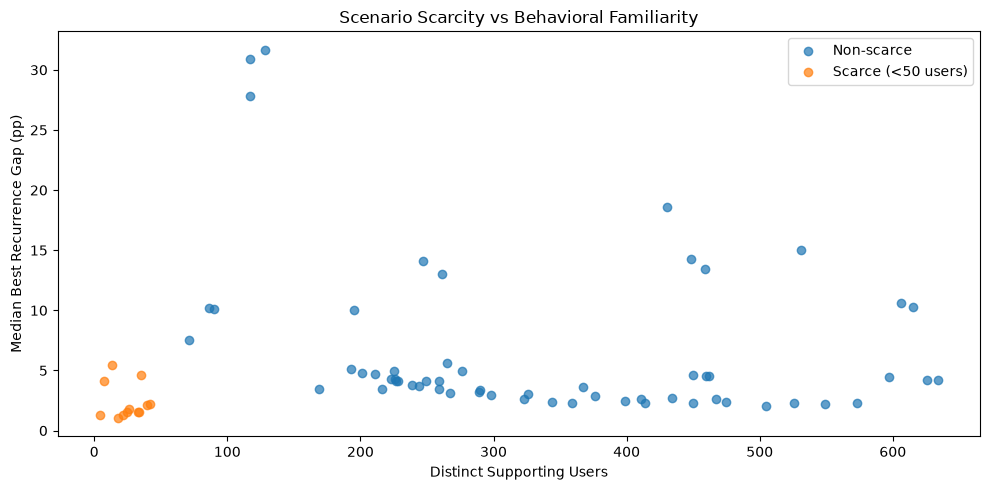

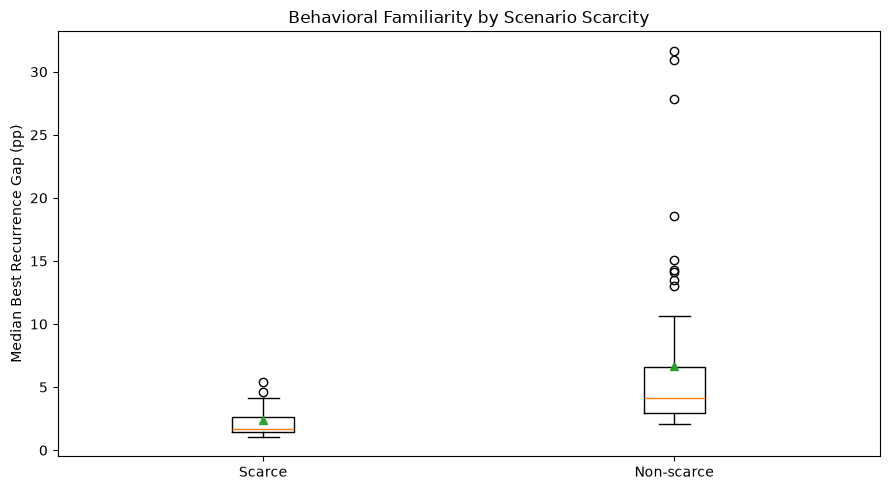

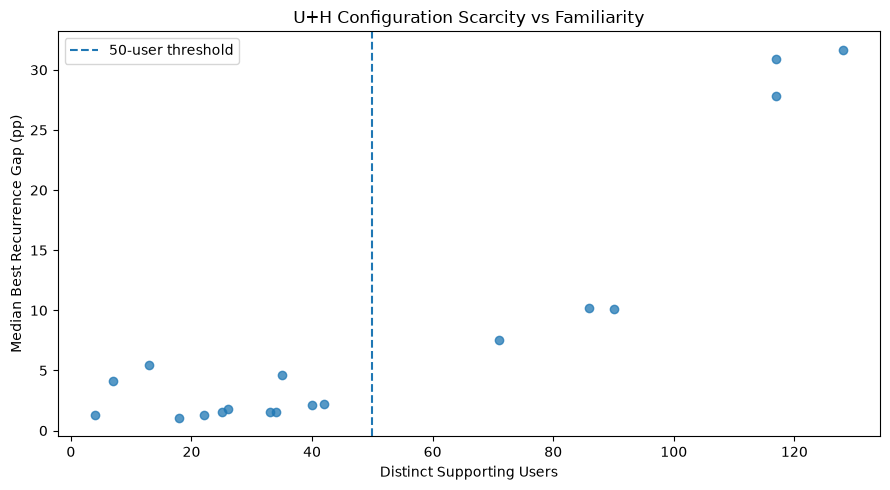


NOTEBOOK 08 — SECTION 8.3.1.1 SUMMARY
User-core records       : 20,281
Core configurations     : 71
Scarce configurations   : 12
Non-scarce configurations: 59
Visualizations generated: 3
Attackers selected      : 0
Files saved             : NO
Original files modified : NO
SECTION 8.3.1.1 — PASS


In [29]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.3.1.1
# SCENARIO SCARCITY VS. BEHAVIORAL FAMILIARITY
#
# Read-only | Reuse existing results | No exports
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

CORE_KEYS_08311 = [
    "window_workdays",
    "channel_configuration",
    "switching_level",
]

USER_CORE_KEYS_08311 = ["user", *CORE_KEYS_08311]


# ------------------------------------------------------------
# STEP 1 — Derive core scarcity from approved catalog
#
# Core = duration + channel configuration + switching.
# Stealth is excluded because it does not change the
# underlying user/window/channel availability.
# ------------------------------------------------------------

user_core_support_08311 = (
    scenario_catalog_08[USER_CORE_KEYS_08311]
    .drop_duplicates()
)

core_scarcity_08 = (
    user_core_support_08311
    .groupby(CORE_KEYS_08311)
    .agg(supporting_users=("user", "nunique"))
    .reset_index()
)

core_scarcity_08["scarce_under_50"] = (
    core_scarcity_08["supporting_users"] < 50
)

assert not core_scarcity_08.duplicated(
    CORE_KEYS_08311
).any()

print("STEP 1 — Core configuration scarcity prepared: PASS")


# ------------------------------------------------------------
# STEP 2 — Link previously calculated familiarity
# ------------------------------------------------------------

familiarity_08311 = core_familiarity_08[
    USER_CORE_KEYS_08311
    + [
        "available_windows",
        "best_recurrence_gap_pp",
        "median_recurrence_gap_pp",
    ]
].copy()

assert not familiarity_08311.duplicated(
    USER_CORE_KEYS_08311
).any()

user_scarcity_familiarity_08 = (
    familiarity_08311.merge(
        core_scarcity_08,
        on=CORE_KEYS_08311,
        how="left",
        validate="many_to_one",
        indicator=True,
    )
)

assert user_scarcity_familiarity_08["_merge"].eq("both").all()

user_scarcity_familiarity_08.drop(
    columns="_merge",
    inplace=True,
)

# Confirm the support count matches actual user-core records.
actual_support_08311 = (
    user_scarcity_familiarity_08
    .groupby(CORE_KEYS_08311)["user"]
    .nunique()
    .rename("actual_users")
    .reset_index()
)

support_check_08311 = core_scarcity_08.merge(
    actual_support_08311,
    on=CORE_KEYS_08311,
    validate="one_to_one",
)

assert support_check_08311["supporting_users"].eq(
    support_check_08311["actual_users"]
).all()

print("STEP 2 — Familiarity linked to scarcity: PASS")


# ------------------------------------------------------------
# STEP 3 — Configuration-level familiarity
#
# Each user contributes one best-gap value per core.
# Each core then contributes one summary observation.
# ------------------------------------------------------------

core_gap_summary_08311 = (
    user_scarcity_familiarity_08
    .groupby(CORE_KEYS_08311)
    .agg(
        median_best_gap_pp=(
            "best_recurrence_gap_pp", "median"
        ),
        mean_best_gap_pp=(
            "best_recurrence_gap_pp", "mean"
        ),
        min_best_gap_pp=(
            "best_recurrence_gap_pp", "min"
        ),
        p75_best_gap_pp=(
            "best_recurrence_gap_pp",
            lambda s: s.quantile(0.75),
        ),
        median_window_gap_pp=(
            "median_recurrence_gap_pp", "median"
        ),
    )
    .reset_index()
)

scenario_scarcity_familiarity_08 = (
    core_scarcity_08.merge(
        core_gap_summary_08311,
        on=CORE_KEYS_08311,
        how="left",
        validate="one_to_one",
    )
)

assert scenario_scarcity_familiarity_08[
    "median_best_gap_pp"
].notna().all()

print("STEP 3 — Configuration-level familiarity summarized: PASS")


# ------------------------------------------------------------
# STEP 4 — Compare scarce vs non-scarce configurations
# ------------------------------------------------------------

scenario_scarcity_familiarity_08["scarcity_group"] = (
    np.where(
        scenario_scarcity_familiarity_08["scarce_under_50"],
        "Scarce (<50 users)",
        "Non-scarce (>=50 users)",
    )
)

scarcity_comparison_08 = (
    scenario_scarcity_familiarity_08
    .groupby("scarcity_group")
    .agg(
        configurations=("supporting_users", "size"),
        median_supporting_users=("supporting_users", "median"),
        median_best_gap_pp=("median_best_gap_pp", "median"),
        mean_best_gap_pp=("median_best_gap_pp", "mean"),
    )
    .reset_index()
)

print("\nSCARCE VS NON-SCARCE CONFIGURATIONS")
display(scarcity_comparison_08.round(2))


# ------------------------------------------------------------
# STEP 5 — Descriptive Spearman association
# ------------------------------------------------------------

def safe_spearman_08311(df):
    if (
        len(df) < 3
        or df["supporting_users"].nunique() < 2
        or df["median_best_gap_pp"].nunique() < 2
    ):
        return np.nan

    return float(
        spearmanr(
            df["supporting_users"],
            df["median_best_gap_pp"],
        ).statistic
    )

association_rows_08311 = []

for config in ["ALL", *ASSIGNMENT_RULES_08["channel_configurations"]]:

    subset = (
        scenario_scarcity_familiarity_08
        if config == "ALL"
        else scenario_scarcity_familiarity_08.loc[
            scenario_scarcity_familiarity_08[
                "channel_configuration"
            ].eq(config)
        ]
    )

    association_rows_08311.append({
        "channel_configuration": config,
        "core_configurations": len(subset),
        "spearman_rho": safe_spearman_08311(subset),
    })

association_summary_08 = pd.DataFrame(
    association_rows_08311
)

print("\nSCARCITY–FAMILIARITY ASSOCIATION")
display(association_summary_08.round(3))


# ------------------------------------------------------------
# STEP 6 — Inspect scarce configurations
# ------------------------------------------------------------

rare_familiarity_08 = (
    scenario_scarcity_familiarity_08.loc[
        scenario_scarcity_familiarity_08["scarce_under_50"]
    ]
    .sort_values(
        ["supporting_users", "window_workdays"]
    )
    .reset_index(drop=True)
)

print("\nSCARCE CORE CONFIGURATIONS")
display(
    rare_familiarity_08[
        CORE_KEYS_08311
        + [
            "supporting_users",
            "median_best_gap_pp",
            "min_best_gap_pp",
            "p75_best_gap_pp",
        ]
    ].round(2)
)


# ------------------------------------------------------------
# STEP 7 — Visualization: scarcity vs familiarity
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

for scarce, label in [
    (False, "Non-scarce"),
    (True, "Scarce (<50 users)"),
]:
    subset = scenario_scarcity_familiarity_08.loc[
        scenario_scarcity_familiarity_08[
            "scarce_under_50"
        ].eq(scarce)
    ]

    plt.scatter(
        subset["supporting_users"],
        subset["median_best_gap_pp"],
        label=label,
        alpha=0.7,
    )

plt.xlabel("Distinct Supporting Users")
plt.ylabel("Median Best Recurrence Gap (pp)")
plt.title("Scenario Scarcity vs Behavioral Familiarity")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 8 — Visualization: scarce vs non-scarce
# ------------------------------------------------------------

scarce_gaps_08311 = (
    scenario_scarcity_familiarity_08.loc[
        scenario_scarcity_familiarity_08["scarce_under_50"],
        "median_best_gap_pp",
    ].to_numpy()
)

common_gaps_08311 = (
    scenario_scarcity_familiarity_08.loc[
        ~scenario_scarcity_familiarity_08["scarce_under_50"],
        "median_best_gap_pp",
    ].to_numpy()
)

plt.figure(figsize=(9, 5))
plt.boxplot(
    [scarce_gaps_08311, common_gaps_08311],
    tick_labels=["Scarce", "Non-scarce"],
    showmeans=True,
)
plt.ylabel("Median Best Recurrence Gap (pp)")
plt.title("Behavioral Familiarity by Scenario Scarcity")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 9 — Visualization: U+H configurations only
# ------------------------------------------------------------

uh_08311 = scenario_scarcity_familiarity_08.loc[
    scenario_scarcity_familiarity_08[
        "channel_configuration"
    ].eq("U+H")
]

plt.figure(figsize=(9, 5))
plt.scatter(
    uh_08311["supporting_users"],
    uh_08311["median_best_gap_pp"],
    alpha=0.75,
)
plt.axvline(50, linestyle="--", label="50-user threshold")
plt.xlabel("Distinct Supporting Users")
plt.ylabel("Median Best Recurrence Gap (pp)")
plt.title("U+H Configuration Scarcity vs Familiarity")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 10 — Final integrity and summary
# ------------------------------------------------------------

assert len(user_scarcity_familiarity_08) == len(
    core_familiarity_08
)

assert len(scenario_scarcity_familiarity_08) == len(
    core_scarcity_08
)

assert (
    len(rare_familiarity_08)
    + len(common_gaps_08311)
    == len(core_scarcity_08)
)

print("\n" + "=" * 62)
print("NOTEBOOK 08 — SECTION 8.3.1.1 SUMMARY")
print("=" * 62)
print(
    "User-core records       :",
    f"{len(user_scarcity_familiarity_08):,}"
)
print(
    "Core configurations     :",
    len(core_scarcity_08)
)
print(
    "Scarce configurations   :",
    len(rare_familiarity_08)
)
print(
    "Non-scarce configurations:",
    len(common_gaps_08311)
)
print("Visualizations generated: 3")
print("Attackers selected      : 0")
print("Files saved             : NO")
print("Original files modified : NO")
print("=" * 62)
print("SECTION 8.3.1.1 — PASS")



### 8.3.2 — Joint Diversity Feasibility Assessment

#### Objective

Evaluate whether 400 distinct users can jointly support diverse scenario assignments across attack duration, channel configuration, and switching level, while respecting approved user-specific scenario eligibility.

#### Methodology

Three feasibility experiments are conducted using binary integer optimization.

**Experiment A — Basic Coverage**
- Exactly 400 distinct attackers.
- At least one assignment per duration, channel configuration, and switching level.
- Represent scarce U+H High-Switching configurations at 30, 40, and 50 workdays.

**Experiment B — Exploratory Diversity Balance**
- At least 40 assignments per duration.
- At least 30 assignments per channel configuration.
- At least 90 assignments per switching level.
- Preserve the specified scarce-configuration coverage.

**Experiment C — Familiarity-Aware Balance**
- Apply the same diversity requirements as Experiment B.
- Restrict the feasibility test to user-core alternatives within the 75th percentile of the previously calculated best recurrence gaps, evaluated separately by duration.

#### Feasibility Constraints

- Exactly 400 assignments.
- At most one assignment per user.
- Each assignment must correspond to an approved user-core configuration.
- All diversity requirements must be satisfied simultaneously.

#### Interpretation

A feasible result demonstrates that the tested constraints can be satisfied together. It does not establish an optimal assignment.

The exploratory minimum counts and familiarity percentile are sensitivity assumptions, not permanent eligibility rules or final assignment quotas.

Stealth remains part of the approved scenario catalog and will be balanced during final scenario assignment.

#### Expected Outcome

Compare the three feasibility experiments and establish whether the approved candidate population can support a diverse, user-specific attack population.

No final attackers are selected, and no files are saved or modified.


STEP 1 — Approved user-core alternatives prepared: PASS
User-core alternatives: 20,281

STEP 2 — Three feasibility experiments defined: PASS

STEP 3 — Exploratory familiarity thresholds prepared


,window_workdays,exploratory_p75_gap_pp
0,5,24.94
1,10,8.45
2,20,5.90
3,30,5.71
4,40,5.78
5,50,6.06


STEP 4 — Joint feasibility solver prepared: PASS

Running A — Basic Coverage ...
Outcome: FEASIBLE | Users: 936 | Solver status: 0

Running B — Exploratory Balance ...
Outcome: FEASIBLE | Users: 936 | Solver status: 0

Running C — Familiarity-Aware Balance ...
Outcome: FEASIBLE | Users: 836 | Solver status: 0

JOINT FEASIBILITY RESULTS


,experiment,candidate_users,user_core_pairs,outcome,solver_status
0,A — Basic Coverage,936,20281,FEASIBLE,0
1,B — Exploratory Balance,936,20281,FEASIBLE,0
2,C — Familiarity-Aware Balance,836,15218,FEASIBLE,0



FEASIBLE DISTRIBUTIONS


,dimension,category,assigned,experiment
0,Duration,5,84,A — Basic Coverage
1,Duration,10,94,A — Basic Coverage
2,Duration,20,62,A — Basic Coverage
3,Duration,30,59,A — Basic Coverage
4,Duration,40,48,A — Basic Coverage
5,Duration,50,53,A — Basic Coverage
6,Channels,E+U,182,A — Basic Coverage
7,Channels,E+H,131,A — Basic Coverage
8,Channels,U+H,21,A — Basic Coverage
9,Channels,E+U+H,66,A — Basic Coverage



SCARCE CONFIGURATION COVERAGE


,configuration,assigned,experiment
0,30d | U+H | High,1,A — Basic Coverage
1,40d | U+H | High,1,A — Basic Coverage
2,50d | U+H | High,1,A — Basic Coverage
3,30d | U+H | High,3,B — Exploratory Balance
4,40d | U+H | High,1,B — Exploratory Balance
5,50d | U+H | High,1,B — Exploratory Balance
6,30d | U+H | High,1,C — Familiarity-Aware Balance
7,40d | U+H | High,1,C — Familiarity-Aware Balance
8,50d | U+H | High,2,C — Familiarity-Aware Balance


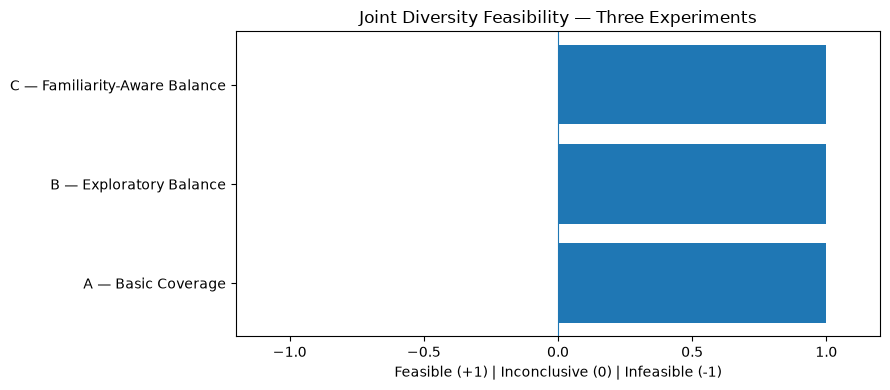


NOTEBOOK 08 — SECTION 8.3.2 SUMMARY
A — Basic Coverage: FEASIBLE
B — Exploratory Balance: FEASIBLE
C — Familiarity-Aware Balance: FEASIBLE

Baseline recalculated  : NO
Switching recalculated : NO
Final quotas imposed   : NO
Attackers selected     : 0
Files saved            : NO
Originals modified     : NO
SECTION 8.3.2 — EXPERIMENTS COMPLETED


In [30]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.3.2
# JOINT DIVERSITY FEASIBILITY ASSESSMENT
#
# Read-only | Three feasibility experiments | No exports
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix, vstack
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Prepare approved user-core alternatives
# ------------------------------------------------------------

TARGET_0832 = ASSIGNMENT_RULES_08["target_attackers"]
DURATIONS_0832 = ASSIGNMENT_RULES_08["durations"]
CHANNELS_0832 = ASSIGNMENT_RULES_08["channel_configurations"]
SWITCHING_0832 = ASSIGNMENT_RULES_08["switching_levels"]

CORE_KEYS_0832 = [
    "window_workdays",
    "channel_configuration",
    "switching_level",
]

USER_CORE_KEYS_0832 = ["user", *CORE_KEYS_0832]

eligible_0832 = (
    scenario_catalog_08[USER_CORE_KEYS_0832]
    .drop_duplicates()
    .merge(
        core_familiarity_08[
            USER_CORE_KEYS_0832
            + ["best_recurrence_gap_pp"]
        ],
        on=USER_CORE_KEYS_0832,
        how="left",
        validate="one_to_one",
    )
)

assert len(eligible_0832) == len(core_familiarity_08)
assert eligible_0832["user"].nunique() == 936
assert eligible_0832["best_recurrence_gap_pp"].notna().all()
assert not eligible_0832.duplicated(USER_CORE_KEYS_0832).any()

print("STEP 1 — Approved user-core alternatives prepared: PASS")
print("User-core alternatives:", f"{len(eligible_0832):,}")


# ------------------------------------------------------------
# STEP 2 — Define three feasibility experiments
# ------------------------------------------------------------

RARE_PROBES_0832 = [
    (30, "U+H", "High"),
    (40, "U+H", "High"),
    (50, "U+H", "High"),
]

BASIC_MINIMA_0832 = {
    "Duration": 1,
    "Channels": 1,
    "Switching": 1,
}

BALANCED_MINIMA_0832 = {
    "Duration": 40,
    "Channels": 30,
    "Switching": 90,
}

experiments_0832 = [
    ("A — Basic Coverage", BASIC_MINIMA_0832, False),
    ("B — Exploratory Balance", BALANCED_MINIMA_0832, False),
    ("C — Familiarity-Aware Balance", BALANCED_MINIMA_0832, True),
]

print("\nSTEP 2 — Three feasibility experiments defined: PASS")


# ------------------------------------------------------------
# STEP 3 — Prepare familiarity sensitivity subset
# ------------------------------------------------------------

familiarity_thresholds_08 = (
    eligible_0832.groupby("window_workdays")[
        "best_recurrence_gap_pp"
    ]
    .quantile(0.75)
    .rename("exploratory_p75_gap_pp")
    .reset_index()
)

eligible_0832 = eligible_0832.merge(
    familiarity_thresholds_08,
    on="window_workdays",
    validate="many_to_one",
)

eligible_0832["familiarity_preferred"] = (
    eligible_0832["best_recurrence_gap_pp"]
    <= eligible_0832["exploratory_p75_gap_pp"]
)

print("\nSTEP 3 — Exploratory familiarity thresholds prepared")
display(familiarity_thresholds_08.round(2))


# ------------------------------------------------------------
# STEP 4 — Define joint feasibility solver
# ------------------------------------------------------------

def run_feasibility_0832(candidates, minima, name):

    candidates = candidates.reset_index(drop=True)
    n = len(candidates)
    columns = np.arange(n)

    user_codes, user_names = pd.factorize(
        candidates["user"], sort=True
    )

    duration_codes = pd.Categorical(
        candidates["window_workdays"],
        categories=DURATIONS_0832,
    ).codes

    channel_codes = pd.Categorical(
        candidates["channel_configuration"],
        categories=CHANNELS_0832,
    ).codes

    switching_codes = pd.Categorical(
        candidates["switching_level"],
        categories=SWITCHING_0832,
    ).codes

    assert (duration_codes >= 0).all()
    assert (channel_codes >= 0).all()
    assert (switching_codes >= 0).all()

    def indicator(codes, rows):
        return coo_matrix(
            (
                np.ones(n),
                (codes, columns),
            ),
            shape=(rows, n),
        ).tocsr()

    total_matrix = coo_matrix(
        (
            np.ones(n),
            (np.zeros(n, dtype=int), columns),
        ),
        shape=(1, n),
    ).tocsr()

    user_matrix = indicator(user_codes, len(user_names))
    duration_matrix = indicator(
        duration_codes, len(DURATIONS_0832)
    )
    channel_matrix = indicator(
        channel_codes, len(CHANNELS_0832)
    )
    switching_matrix = indicator(
        switching_codes, len(SWITCHING_0832)
    )

    rare_masks = []

    for duration, channel, switching in RARE_PROBES_0832:
        rare_masks.append(
            (
                candidates["window_workdays"].eq(duration)
                & candidates["channel_configuration"].eq(channel)
                & candidates["switching_level"].eq(switching)
            ).to_numpy(dtype=float)
        )

    rare_matrix = coo_matrix(
        np.vstack(rare_masks)
    ).tocsr()

    A = vstack(
        [
            total_matrix,
            user_matrix,
            duration_matrix,
            channel_matrix,
            switching_matrix,
            rare_matrix,
        ],
        format="csr",
    )

    u0 = 1
    d0 = u0 + len(user_names)
    c0 = d0 + len(DURATIONS_0832)
    s0 = c0 + len(CHANNELS_0832)
    r0 = s0 + len(SWITCHING_0832)

    lower = np.zeros(A.shape[0])
    upper = np.full(A.shape[0], np.inf)

    # Exactly 400 assignments.
    lower[0] = TARGET_0832
    upper[0] = TARGET_0832

    # At most one assignment per user.
    upper[u0:d0] = 1

    # Experiment-specific diversity requirements.
    lower[d0:c0] = minima["Duration"]
    lower[c0:s0] = minima["Channels"]
    lower[s0:r0] = minima["Switching"]

    # Preserve the three rare U+H configurations.
    lower[r0:] = 1

    result = milp(
        c=np.zeros(n),
        integrality=np.ones(n, dtype=np.uint8),
        bounds=Bounds(np.zeros(n), np.ones(n)),
        constraints=LinearConstraint(
            A,
            lb=lower,
            ub=upper,
        ),
        options={
            "time_limit": 45,
            "presolve": True,
            "disp": False,
        },
    )

    feasible = False
    marginals = []
    rare_coverage = []

    if result.x is not None:

        x = np.rint(result.x)

        integer_valid = np.all(
            np.abs(result.x - x) < 1e-5
        )

        if integer_valid:

            achieved = np.asarray(A @ x).ravel()

            feasible = bool(
                np.all(achieved >= lower - 1e-6)
                and np.all(achieved <= upper + 1e-6)
            )

            if feasible:

                for dimension, categories, start in [
                    ("Duration", DURATIONS_0832, d0),
                    ("Channels", CHANNELS_0832, c0),
                    ("Switching", SWITCHING_0832, s0),
                ]:
                    for i, category in enumerate(categories):
                        marginals.append({
                            "dimension": dimension,
                            "category": str(category),
                            "assigned": int(achieved[start + i]),
                        })

                for i, probe in enumerate(RARE_PROBES_0832):
                    rare_coverage.append({
                        "configuration": (
                            f"{probe[0]}d | {probe[1]} | {probe[2]}"
                        ),
                        "assigned": int(achieved[r0 + i]),
                    })

    if feasible:
        outcome = "FEASIBLE"
    elif result.status == 2:
        outcome = "INFEASIBLE"
    else:
        outcome = "INCONCLUSIVE"

    return {
        "experiment": name,
        "outcome": outcome,
        "solver_status": int(result.status),
        "candidate_users": len(user_names),
        "user_core_pairs": n,
        "marginals": pd.DataFrame(marginals),
        "rare_coverage": pd.DataFrame(rare_coverage),
    }


print("STEP 4 — Joint feasibility solver prepared: PASS")


# ------------------------------------------------------------
# STEP 5 — Run the three experiments
# ------------------------------------------------------------

results_0832 = []

for name, minima, familiarity_filter in experiments_0832:

    candidates = (
        eligible_0832.loc[
            eligible_0832["familiarity_preferred"]
        ]
        if familiarity_filter
        else eligible_0832
    )

    print(f"\nRunning {name} ...")

    result = run_feasibility_0832(
        candidates, minima, name
    )

    results_0832.append(result)

    print(
        f"Outcome: {result['outcome']} "
        f"| Users: {result['candidate_users']} "
        f"| Solver status: {result['solver_status']}"
    )


# ------------------------------------------------------------
# STEP 6 — Compare experiment outcomes
# ------------------------------------------------------------

joint_feasibility_results_08 = pd.DataFrame([
    {
        "experiment": r["experiment"],
        "candidate_users": r["candidate_users"],
        "user_core_pairs": r["user_core_pairs"],
        "outcome": r["outcome"],
        "solver_status": r["solver_status"],
    }
    for r in results_0832
])

print("\nJOINT FEASIBILITY RESULTS")
display(joint_feasibility_results_08)

feasible_marginals_0832 = []
feasible_rare_0832 = []

for r in results_0832:

    if r["outcome"] != "FEASIBLE":
        continue

    margins = r["marginals"].copy()
    margins["experiment"] = r["experiment"]
    feasible_marginals_0832.append(margins)

    rare = r["rare_coverage"].copy()
    rare["experiment"] = r["experiment"]
    feasible_rare_0832.append(rare)

joint_feasibility_marginals_08 = (
    pd.concat(feasible_marginals_0832, ignore_index=True)
    if feasible_marginals_0832 else pd.DataFrame()
)

joint_feasibility_rare_08 = (
    pd.concat(feasible_rare_0832, ignore_index=True)
    if feasible_rare_0832 else pd.DataFrame()
)

if not joint_feasibility_marginals_08.empty:
    print("\nFEASIBLE DISTRIBUTIONS")
    display(joint_feasibility_marginals_08)

    print("\nSCARCE CONFIGURATION COVERAGE")
    display(joint_feasibility_rare_08)


# ------------------------------------------------------------
# STEP 7 — Visualize experiment outcomes
# ------------------------------------------------------------

outcome_values_0832 = {
    "FEASIBLE": 1,
    "INCONCLUSIVE": 0,
    "INFEASIBLE": -1,
}

plt.figure(figsize=(9, 4))

plt.barh(
    joint_feasibility_results_08["experiment"],
    joint_feasibility_results_08["outcome"].map(
        outcome_values_0832
    ),
)

plt.axvline(0, linewidth=0.8)
plt.xlim(-1.2, 1.2)
plt.xlabel("Feasible (+1) | Inconclusive (0) | Infeasible (-1)")
plt.title("Joint Diversity Feasibility — Three Experiments")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 8 — Final summary
# ------------------------------------------------------------

assert len(joint_feasibility_results_08) == 3
assert joint_feasibility_results_08["outcome"].isin(
    ["FEASIBLE", "INFEASIBLE", "INCONCLUSIVE"]
).all()

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.3.2 SUMMARY")
print("=" * 65)

for r in results_0832:
    print(f"{r['experiment']}: {r['outcome']}")

print("\nBaseline recalculated  : NO")
print("Switching recalculated : NO")
print("Final quotas imposed   : NO")
print("Attackers selected     : 0")
print("Files saved            : NO")
print("Originals modified     : NO")
print("=" * 65)
print("SECTION 8.3.2 — EXPERIMENTS COMPLETED")



### 8.3.3 — Diversity-Aware Assignment Policy

#### Objective

Establish an evidence-based policy for selecting 400 unique attackers and assigning approved scenarios while balancing diversity, behavioral familiarity, scenario scarcity, and forced off-days.

#### Supporting Evidence

- **Section 8.2:** Candidate flexibility and scenario scarcity.
- **Section 8.3.1:** Historical-to-window behavioral familiarity.
- **Section 8.3.1.1:** Relationship between configuration scarcity and familiarity.
- **Section 8.3.2:** Successful joint-diversity feasibility experiments.

#### Mandatory Constraints

1. Select exactly 400 distinct users.
2. Assign one approved scenario option to each attacker.
3. Preserve approved user-specific windows, channel availability, and switching feasibility.
4. Preserve Formula A with Balanced stealth multipliers.
5. Respect forced Off-Day restrictions and the immutable historical baseline.
6. Use only approved Future-period scenarios.

#### Assignment Objectives

- **Duration Diversity:** Maintain broad representation across all six durations.
- **Channel Diversity:** Preserve meaningful representation of all two-channel configurations and the three-channel configuration.
- **Three-Channel Representation:** Explicitly consider users eligible for E+U+H before assigning them to two-channel alternatives, preventing avoidable underrepresentation.
- **Switching Diversity:** Seek balanced Low, Medium, and High switching levels.
- **Stealth Diversity:** Seek approximately equal representation of all three stealth levels.
- **Behavioral Familiarity:** Prefer approved windows with smaller historical-to-window recurrence gaps.
- **Scenario Scarcity:** Account for limited supporting-user availability, particularly for U+H.
- **Forced Off-Days:** Prefer fewer forced Off-Days among otherwise suitable scenarios.

#### Policy Decisions

- Diversity requirements tested in Section 8.3.2 serve as feasibility benchmarks, not mandatory category quotas.
- Familiarity percentile thresholds are descriptive references, not eligibility exclusions.
- Scenario scarcity does not automatically justify selecting or rejecting a configuration.
- Three-channel eligibility must be considered during assignment optimization rather than only during final evaluation.
- Behavioral familiarity is a preference, not a guarantee of stealth.
- Final category distributions must be evaluated jointly before approval.

#### Expected Outcome

A documented distinction between mandatory constraints and flexible selection objectives, ready for implementation in Section 8.4.

No attackers are selected and no files are exported.


In [31]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.3.3
# DIVERSITY-AWARE ASSIGNMENT POLICY
#
# Policy definition only | No selection | No export
# ============================================================

import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Confirm approved analytical evidence
# ------------------------------------------------------------

assert ASSIGNMENT_RULES_08["target_attackers"] == 400

expected_experiments_0833 = {
    "A — Basic Coverage",
    "B — Exploratory Balance",
    "C — Familiarity-Aware Balance",
}

results_0833 = joint_feasibility_results_08.set_index(
    "experiment"
)

assert expected_experiments_0833.issubset(results_0833.index)

assert results_0833.loc[
    sorted(expected_experiments_0833), "outcome"
].eq("FEASIBLE").all()

assert len(core_scarcity_08) == 71
assert len(core_familiarity_08) == 20_281
assert len(triple_eligible_users_08) == 281

print("STEP 1 — Previous evidence confirmed: PASS")


# ------------------------------------------------------------
# STEP 2 — Establish mandatory constraints
# ------------------------------------------------------------

assignment_hard_constraints_08 = {
    "target_attackers": 400,
    "unique_users": True,
    "one_scenario_per_user": True,
    "approved_catalog_only": True,
    "approved_future_windows_only": True,
    "preserve_switching_feasibility": True,
    "preserve_forced_offday_rules": True,
    "preserve_immutable_baseline": True,
    "stealth_formula": "A",
    "multiplier_configuration": "Balanced",
    "modify_source_data": False,
}

print("STEP 2 — Mandatory constraints established: PASS")


# ------------------------------------------------------------
# STEP 3 — Establish flexible selection objectives
# ------------------------------------------------------------

assignment_objectives_08 = pd.DataFrame([
    {
        "objective": "Duration Diversity",
        "target": "Broad representation of all six durations",
        "role": "SOFT",
    },
    {
        "objective": "Channel Diversity",
        "target": "Meaningful representation of all four configurations",
        "role": "SOFT",
    },
    {
        "objective": "Three-Channel Representation",
        "target": "Evaluate E+U+H alternatives before assigning flexible users to two-channel scenarios",
        "role": "SOFT",
    },
    {
        "objective": "Switching Diversity",
        "target": "Balanced Low, Medium, and High",
        "role": "SOFT",
    },
    {
        "objective": "Stealth Diversity",
        "target": "Approximately equal representation",
        "role": "SOFT",
    },
    {
        "objective": "Behavioral Familiarity",
        "target": "Prefer smaller actual-window recurrence gaps",
        "role": "SOFT",
    },
    {
        "objective": "Scenario Scarcity",
        "target": "Protect representation of limited configurations",
        "role": "SOFT",
    },
    {
        "objective": "Forced Off-Days",
        "target": "Prefer fewer among suitable alternatives",
        "role": "SOFT",
    },
])

print("STEP 3 — Selection objectives established: PASS")


# ------------------------------------------------------------
# STEP 4 — Retain experimental bounds as references
# ------------------------------------------------------------

benchmark_rows_0833 = []

for dimension, categories, minimum in [
    ("Duration", ASSIGNMENT_RULES_08["durations"], 40),
    ("Channels", ASSIGNMENT_RULES_08["channel_configurations"], 30),
    ("Switching", ASSIGNMENT_RULES_08["switching_levels"], 90),
]:
    for category in categories:
        benchmark_rows_0833.append({
            "dimension": dimension,
            "category": str(category),
            "tested_minimum": minimum,
            "policy": "REFERENCE_ONLY",
        })

diversity_benchmarks_08 = pd.DataFrame(
    benchmark_rows_0833
)

rare_benchmarks_08 = [
    (30, "U+H", "High"),
    (40, "U+H", "High"),
    (50, "U+H", "High"),
]

familiarity_reference_08 = (
    familiarity_thresholds_08.copy()
    .rename(columns={
        "exploratory_p75_gap_pp": "reference_p75_gap_pp"
    })
)

familiarity_reference_08["policy"] = "REFERENCE_ONLY"

print("STEP 4 — Feasibility benchmarks retained: PASS")


# ------------------------------------------------------------
# STEP 5 — Define balanced stealth preference
# ------------------------------------------------------------

stealth_preference_08 = {
    "High": 134,
    "Medium": 133,
    "Low": 133,
}

assert sum(stealth_preference_08.values()) == 400

print("STEP 5 — Stealth preference established: PASS")


# ------------------------------------------------------------
# STEP 6 — Consolidate assignment policy
# ------------------------------------------------------------

assignment_policy_08 = {
    "hard_constraints": assignment_hard_constraints_08,

    "soft_objectives": assignment_objectives_08[
        "objective"
    ].tolist(),

    "diversity_benchmarks": diversity_benchmarks_08,

    "rare_configuration_benchmarks": rare_benchmarks_08,

    "stealth_preference": stealth_preference_08,

    "three_channel_policy": {
        "configuration": "E+U+H",
        "eligible_users": len(triple_eligible_users_08),
        "evaluate_eligible_alternatives": True,
        "avoid_unnecessary_two_channel_assignment": True,
        "fixed_category_quota": None,
    },

    "familiarity": {
        "metric": "max_abs_recurrence_gap_pp",
        "actual_window_required": True,
        "p75_hard_exclusion": False,
    },

    "selection_strategy_status": "NOT_YET_DESIGNED",
    "final_assignments_created": False,
}

print("STEP 6 — Assignment policy established: PASS")


# ------------------------------------------------------------
# STEP 7 — Display policy
# ------------------------------------------------------------

print("\nMANDATORY CONSTRAINTS")
display(pd.DataFrame([
    {"constraint": key, "value": value}
    for key, value in assignment_hard_constraints_08.items()
]))

print("\nSELECTION OBJECTIVES")
display(assignment_objectives_08)

print("\nEXPLORATORY DIVERSITY BENCHMARKS")
display(diversity_benchmarks_08)

print("\nSTEALTH PREFERENCE")
display(pd.DataFrame([
    {"level": level, "preferred_count": count}
    for level, count in stealth_preference_08.items()
]))


# ------------------------------------------------------------
# STEP 8 — Final summary
# ------------------------------------------------------------

assert len(assignment_objectives_08) == 8

assert (
    assignment_policy_08["three_channel_policy"][
        "eligible_users"
    ] == 281
)

print("\n" + "=" * 62)
print("NOTEBOOK 08 — SECTION 8.3.3 SUMMARY")
print("=" * 62)

print("Target attackers         : 400")
print("Feasibility experiments  : 3/3 FEASIBLE")
print("Soft selection objectives:", len(assignment_objectives_08))
print("E+U+H eligible users     :", len(triple_eligible_users_08))
print("Fixed channel quotas     : NONE")
print("P75 hard exclusion       : NO")
print("Stealth preference       : 134 / 133 / 133")
print("Selection strategy       : NOT YET DESIGNED")
print("Attackers selected       : 0")
print("Files saved              : NO")
print("Original files modified  : NO")
print("=" * 62)
print("SECTION 8.3.3 — PASS")


STEP 1 — Previous evidence confirmed: PASS
STEP 2 — Mandatory constraints established: PASS
STEP 3 — Selection objectives established: PASS
STEP 4 — Feasibility benchmarks retained: PASS
STEP 5 — Stealth preference established: PASS
STEP 6 — Assignment policy established: PASS

MANDATORY CONSTRAINTS


,constraint,value
0,target_attackers,400
1,unique_users,True
2,one_scenario_per_user,True
3,approved_catalog_only,True
4,approved_future_windows_only,True
5,preserve_switching_feasibility,True
6,preserve_forced_offday_rules,True
7,preserve_immutable_baseline,True
8,stealth_formula,A
9,multiplier_configuration,Balanced



SELECTION OBJECTIVES


,objective,target,role
0,Duration Diversity,Broad representation of all six durations,SOFT
1,Channel Diversity,Meaningful representation of all four configur...,SOFT
2,Three-Channel Representation,Evaluate E+U+H alternatives before assigning f...,SOFT
3,Switching Diversity,"Balanced Low, Medium, and High",SOFT
4,Stealth Diversity,Approximately equal representation,SOFT
5,Behavioral Familiarity,Prefer smaller actual-window recurrence gaps,SOFT
6,Scenario Scarcity,Protect representation of limited configurations,SOFT
7,Forced Off-Days,Prefer fewer among suitable alternatives,SOFT



EXPLORATORY DIVERSITY BENCHMARKS


,dimension,category,tested_minimum,policy
0,Duration,5,40,REFERENCE_ONLY
1,Duration,10,40,REFERENCE_ONLY
2,Duration,20,40,REFERENCE_ONLY
3,Duration,30,40,REFERENCE_ONLY
4,Duration,40,40,REFERENCE_ONLY
5,Duration,50,40,REFERENCE_ONLY
6,Channels,E+U,30,REFERENCE_ONLY
7,Channels,E+H,30,REFERENCE_ONLY
8,Channels,U+H,30,REFERENCE_ONLY
9,Channels,E+U+H,30,REFERENCE_ONLY



STEALTH PREFERENCE


,level,preferred_count
0,High,134
1,Medium,133
2,Low,133



NOTEBOOK 08 — SECTION 8.3.3 SUMMARY
Target attackers         : 400
Feasibility experiments  : 3/3 FEASIBLE
Soft selection objectives: 8
E+U+H eligible users     : 281
Fixed channel quotas     : NONE
P75 hard exclusion       : NO
Stealth preference       : 134 / 133 / 133
Selection strategy       : NOT YET DESIGNED
Attackers selected       : 0
Files saved              : NO
Original files modified  : NO
SECTION 8.3.3 — PASS



## 8.4 — Assignment Strategy Design

### Objective

Define a reproducible, constrained assignment strategy for selecting 400 unique attackers from the approved scenario catalog.

The strategy preserves the established attacker population composition while balancing attack duration, channel configuration, switching intensity, stealth level, behavioral familiarity, and Forced Off-Day diversity.

### 1. Attacker Population and Channel Allocation

Select exactly 400 distinct attackers with the following channel configuration distribution:

| Channel Configuration | Target |
|---|---:|
| E+U+H | 139 |
| E+U | 117 |
| E+H | 117 |
| U+H | 27 |
| **Total** | **400** |

Among the 281 users eligible for E+U+H, assign 139 to E+U+H and 27 to U+H, leaving 115 outside the attacker population.

This preserves naturally occurring three-channel behavior among unselected users and prevents three-channel eligibility from becoming an exclusive indicator of malicious behavior.

### 2. Attack Duration Distribution

| Duration (Workdays) | Target |
|---|---:|
| 5 | 50 |
| 10 | 70 |
| 20 | 70 |
| 30 | 70 |
| 40 | 70 |
| 50 | 70 |

Extended windows receive greater overall representation to support the Low-and-Slow simulation objective.

### 3. Switching and Stealth Balance

**Switching:** Low 133, Medium 134, High 133.

**Stealth:** Low 133, Medium 133, High 134.

Stealth follows Formula A with Balanced multipliers:

- High: 0.25
- Medium: 0.50
- Low: 0.75

### 4. Duration-Based Forced Off-Days

| Duration | Allowed Forced Off-Days |
|---|---|
| 5 | 0 |
| 10 | 1, 2 |
| 20 | 2, 3, 4 |
| 30 | 4, 5, 6 |
| 40 | 6, 7, 8 |
| 50 | 8, 9, 10 |

Only approved scenario options satisfying these rules may be selected.

### 5. Forced Off-Day Diversity

The assignment strategy encourages representation of multiple allowed Forced Off-Day counts within each duration.

Diversity is implemented using soft category targets and penalized shortfalls. These are optimization preferences, not mandatory assignment quotas.

The objective balances:

1. Minimizing Forced Off-Days.
2. Encouraging diversity across allowed Off-Day counts.
3. Minimizing behavioral recurrence gaps.
4. Applying deterministic tie-breaking.

### 6. Assignment Execution

1. Prepare approved user-specific candidate options.
2. Apply duration-based Off-Day eligibility.
3. Preserve separate user-core-Off-Day alternatives.
4. Verify joint assignment feasibility.
5. Optimize assignment costs and Off-Day diversity simultaneously.
6. Resolve each selected alternative to its approved catalog scenario.
7. Audit assignment quality and validate against original source records.

### Constraints

- Exactly one assignment per selected user.
- Only approved Future-period windows.
- No Baseline recalculation.
- No arbitrary or artificial Off-Days.
- No daily attack scheduling or injection.
- No source modifications.
- No export before final validation.

### Expected Outcome

A reproducible assignment strategy producing 400 validated attacker-scenario assignments, with approved diversity distributions and measurable Forced Off-Day variation.


In [32]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.4
# ASSIGNMENT STRATEGY DESIGN
#
# Policy definition only | No selection | No exports
# ============================================================

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Confirm approved analytical evidence
# ------------------------------------------------------------

assert ASSIGNMENT_RULES_08["target_attackers"] == 400
assert len(triple_eligible_users_08) == 281

assert joint_feasibility_results_08["outcome"].eq(
    "FEASIBLE"
).all()

print("STEP 1 — Approved evidence confirmed: PASS")


# ------------------------------------------------------------
# STEP 2 — Approved channel allocation
# ------------------------------------------------------------

CHANNEL_TARGETS_08 = {
    "E+U": 117,
    "E+H": 117,
    "U+H": 27,
    "E+U+H": 139,
}

TRIPLE_POPULATION_08 = {
    "eligible_users": 281,
    "assigned_three_channel": 139,
    "assigned_uh": 27,
    "remain_unselected": 115,
}

assert sum(CHANNEL_TARGETS_08.values()) == 400

assert sum([
    TRIPLE_POPULATION_08["assigned_three_channel"],
    TRIPLE_POPULATION_08["assigned_uh"],
    TRIPLE_POPULATION_08["remain_unselected"],
]) == 281

print("STEP 2 — Channel allocation established: PASS")


# ------------------------------------------------------------
# STEP 3 — Duration, Switching and Stealth targets
# ------------------------------------------------------------

DURATION_TARGETS_08 = {
    5: 50,
    10: 70,
    20: 70,
    30: 70,
    40: 70,
    50: 70,
}

SWITCHING_TARGETS_08 = {
    "Low": 133,
    "Medium": 134,
    "High": 133,
}

STEALTH_TARGETS_08 = {
    "Low": 133,
    "Medium": 133,
    "High": 134,
}

assert sum(DURATION_TARGETS_08.values()) == 400
assert sum(SWITCHING_TARGETS_08.values()) == 400
assert sum(STEALTH_TARGETS_08.values()) == 400

long_duration_084 = sum(
    count
    for duration, count in DURATION_TARGETS_08.items()
    if duration >= 30
)

assert long_duration_084 == 210

print("STEP 3 — Duration, Switching and Stealth: PASS")


# ------------------------------------------------------------
# STEP 4 — Approved duration-based Off-Day policy
# ------------------------------------------------------------

ALLOWED_OFFDAYS_08 = {
    5: [0],
    10: [1, 2],
    20: [2, 3, 4],
    30: [4, 5, 6],
    40: [6, 7, 8],
    50: [8, 9, 10],
}

assert set(ALLOWED_OFFDAYS_08) == set(DURATION_TARGETS_08)

print("STEP 4 — Duration-based Off-Day rules: PASS")


# ------------------------------------------------------------
# STEP 5 — Soft Forced Off-Day diversity preferences
#
# These floors are exploratory optimization preferences,
# not eligibility restrictions or mandatory quotas.
# ------------------------------------------------------------

OFFDAY_DIVERSITY_FLOORS_08 = {
    5: 0,
    10: 20,
    20: 15,
    30: 15,
    40: 15,
    50: 15,
}

OFFDAY_WEIGHT_08 = 250.0
FAMILIARITY_WEIGHT_08 = 1.0
OFFDAY_DIVERSITY_PENALTY_08 = 1000.0
TIE_WEIGHT_08 = 0.001

for duration, allowed in ALLOWED_OFFDAYS_08.items():
    floor = OFFDAY_DIVERSITY_FLOORS_08[duration]

    assert (
        floor * len(allowed)
        <= DURATION_TARGETS_08[duration]
    )

print("STEP 5 — Soft diversity preferences: DEFINED")


# ------------------------------------------------------------
# STEP 6 — Window-selection policy
# ------------------------------------------------------------

WINDOW_POLICY_08 = {
    "approved_catalog_only": True,
    "preserve_switching": True,
    "preserve_stealth": True,
    "duration_offday_rules": ALLOWED_OFFDAYS_08,
    "offday_diversity": "SOFT",
    "preserve_offday_alternatives": True,
    "familiarity_metric": "max_abs_recurrence_gap_pp",
    "compare_same_channel_configuration": True,
    "deterministic_tie_break": "scenario_option_id",
    "offday_weight": OFFDAY_WEIGHT_08,
    "familiarity_weight": FAMILIARITY_WEIGHT_08,
    "diversity_shortfall_penalty":
        OFFDAY_DIVERSITY_PENALTY_08,
}

# Historical reference only — not a constraint.
OFFDAY_REFERENCE_08 = 649

print("STEP 6 — Window-selection policy: DEFINED")


# ------------------------------------------------------------
# STEP 7 — Consolidated strategy
# ------------------------------------------------------------

ASSIGNMENT_STRATEGY_08 = {
    "target_attackers": 400,
    "channel_targets": CHANNEL_TARGETS_08,
    "triple_population": TRIPLE_POPULATION_08,
    "duration_targets": DURATION_TARGETS_08,
    "switching_targets": SWITCHING_TARGETS_08,
    "stealth_targets": STEALTH_TARGETS_08,
    "window_policy": WINDOW_POLICY_08,
    "offday_diversity_floors": OFFDAY_DIVERSITY_FLOORS_08,
    "status": "DEFINED_NOT_EXECUTED",
}

print("STEP 7 — Assignment strategy established: PASS")


# ------------------------------------------------------------
# STEP 8 — Display approved targets
# ------------------------------------------------------------

print("\nCHANNEL ALLOCATION")
display(pd.DataFrame([
    {"configuration": k, "target": v}
    for k, v in CHANNEL_TARGETS_08.items()
]))

print("\nDURATION DISTRIBUTION")
display(pd.DataFrame([
    {"duration": k, "target": v}
    for k, v in DURATION_TARGETS_08.items()
]))

print("\nSWITCHING AND STEALTH")
display(pd.DataFrame([
    {
        "level": level,
        "switching": SWITCHING_TARGETS_08[level],
        "stealth": STEALTH_TARGETS_08[level],
    }
    for level in ["Low", "Medium", "High"]
]))

print("\nOFF-DAY DIVERSITY PREFERENCES")
display(pd.DataFrame([
    {
        "duration": duration,
        "allowed_offdays": str(allowed),
        "soft_floor_per_category":
            OFFDAY_DIVERSITY_FLOORS_08[duration],
    }
    for duration, allowed in ALLOWED_OFFDAYS_08.items()
]))


# ------------------------------------------------------------
# STEP 9 — Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.4 SUMMARY")
print("=" * 65)
print("Target attackers           : 400")
print("E+U+H assignments         : 139")
print("E+U assignments           : 117")
print("E+H assignments           : 117")
print("U+H assignments           : 27")
print("Triple-eligible unselected: 115")
print("Extended-duration attacks :", long_duration_084)
print("Off-Day diversity         : SOFT OBJECTIVE")
print("Switching balance         : 133 / 134 / 133")
print("Stealth balance           : 133 / 133 / 134")
print("Selection performed       : NO")
print("Files saved               : NO")
print("Original files modified   : NO")
print("=" * 65)
print("SECTION 8.4 — PASS")


STEP 1 — Approved evidence confirmed: PASS
STEP 2 — Channel allocation established: PASS
STEP 3 — Duration, Switching and Stealth: PASS
STEP 4 — Duration-based Off-Day rules: PASS
STEP 5 — Soft diversity preferences: DEFINED
STEP 6 — Window-selection policy: DEFINED
STEP 7 — Assignment strategy established: PASS

CHANNEL ALLOCATION


,configuration,target
0,E+U,117
1,E+H,117
2,U+H,27
3,E+U+H,139



DURATION DISTRIBUTION


,duration,target
0,5,50
1,10,70
2,20,70
3,30,70
4,40,70
5,50,70



SWITCHING AND STEALTH


,level,switching,stealth
0,Low,133,133
1,Medium,134,133
2,High,133,134



OFF-DAY DIVERSITY PREFERENCES


,duration,allowed_offdays,soft_floor_per_category
0,5,[0],0
1,10,"[1, 2]",20
2,20,"[2, 3, 4]",15
3,30,"[4, 5, 6]",15
4,40,"[6, 7, 8]",15
5,50,"[8, 9, 10]",15



NOTEBOOK 08 — SECTION 8.4 SUMMARY
Target attackers           : 400
E+U+H assignments         : 139
E+U assignments           : 117
E+H assignments           : 117
U+H assignments           : 27
Triple-eligible unselected: 115
Extended-duration attacks : 210
Off-Day diversity         : SOFT OBJECTIVE
Switching balance         : 133 / 134 / 133
Stealth balance           : 133 / 133 / 134
Selection performed       : NO
Files saved               : NO
Original files modified   : NO
SECTION 8.4 — PASS



### 8.5.1 — Assignment Candidate Preparation & Eligibility Audit

#### Objective

Prepare the approved candidate options for the final 400-attacker assignment using the established channel allocation, duration distribution, and simulation constraints.

#### Candidate Population Policy

The 281 users eligible for E+U+H are allocated across three groups:

- 139 attackers assigned to E+U+H.
- 27 attackers assigned to U+H.
- 115 users retained outside the attacker population.

The remaining E+U and E+H assignments are drawn from eligible users outside this three-channel-capable population.

#### Preparation Procedure

1. Identify the eligible three-channel population.
2. Apply the approved channel-population policy.
3. Exclude five-workday scenarios containing Forced Off-Days.
4. Preserve approved durations, switching levels, and stealth levels.
5. Consolidate duplicate windows into distinct user-core alternatives for subsequent assignment optimization.
6. Examine candidate availability and identify any immediately unsupported targets.

#### Constraints

- Use only approved Notebook 07 scenario options.
- Preserve user-specific feasibility and scenario provenance.
- Do not modify baseline data or original datasets.
- Do not select or reserve attackers at this stage.
- Do not generate daily schedules or injected activity.
- Do not export files.

#### Expected Outcome

A validated candidate pool ready for joint assignment feasibility testing and attacker selection.


In [33]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.5.1
# ASSIGNMENT CANDIDATE PREPARATION & ELIGIBILITY AUDIT
#
# Approved catalog only | No selection | No exports
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Confirm assignment targets
# ------------------------------------------------------------

target_0851 = ASSIGNMENT_STRATEGY_08["target_attackers"]

channel_targets_0851 = CHANNEL_TARGETS_08.copy()
duration_targets_0851 = DURATION_TARGETS_08.copy()
switching_targets_0851 = SWITCHING_TARGETS_08.copy()
stealth_targets_0851 = STEALTH_TARGETS_08.copy()

triple_users_0851 = set(triple_eligible_users_08)

assert target_0851 == 400
assert len(triple_users_0851) == 281

assert channel_targets_0851 == {
    "E+U": 117,
    "E+H": 117,
    "U+H": 27,
    "E+U+H": 139,
}

assert duration_targets_0851 == {
    5: 50,
    10: 70,
    20: 70,
    30: 70,
    40: 70,
    50: 70,
}

assert sum(channel_targets_0851.values()) == target_0851
assert sum(duration_targets_0851.values()) == target_0851
assert sum(switching_targets_0851.values()) == target_0851
assert sum(stealth_targets_0851.values()) == target_0851

assert (
    channel_targets_0851["E+U+H"]
    + channel_targets_0851["U+H"]
    + TRIPLE_POPULATION_08["remain_unselected"]
    == len(triple_users_0851)
)

print("STEP 1 — Approved assignment targets confirmed: PASS")


# ------------------------------------------------------------
# STEP 2 — Apply candidate population policy
#
# Triple-eligible users:
#    E+U+H or U+H
#
# Other eligible users:
#    E+U or E+H
#
# This preserves the 115-user non-attacker population
# without selecting their identities in advance.
# ------------------------------------------------------------

candidate_cols_0851 = [
    "scenario_option_id",
    "user",
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
    "forced_offdays",
]

candidate_options_08 = scenario_catalog_08[
    candidate_cols_0851
].copy()

candidate_options_08["triple_eligible"] = (
    candidate_options_08["user"].isin(triple_users_0851)
)

triple_allowed_0851 = (
    candidate_options_08["triple_eligible"]
    & candidate_options_08["channel_configuration"].isin(
        ["E+U+H", "U+H"]
    )
)

other_allowed_0851 = (
    ~candidate_options_08["triple_eligible"]
    & candidate_options_08["channel_configuration"].isin(
        ["E+U", "E+H"]
    )
)

candidate_options_08 = candidate_options_08.loc[
    triple_allowed_0851 | other_allowed_0851
].copy()

assert candidate_options_08["scenario_option_id"].is_unique

print("STEP 2 — Candidate population policy applied: PASS")


# ------------------------------------------------------------
# STEP 3 — Enforce zero Forced Off-Days for 5-day options
# ------------------------------------------------------------

invalid_five_day_0851 = (
    candidate_options_08["window_workdays"].eq(5)
    & candidate_options_08["forced_offdays"].gt(0)
)

excluded_five_day_0851 = int(invalid_five_day_0851.sum())

candidate_options_08 = candidate_options_08.loc[
    ~invalid_five_day_0851
].copy()

assert not (
    candidate_options_08["window_workdays"].eq(5)
    & candidate_options_08["forced_offdays"].ne(0)
).any()

print("STEP 3 — Five-day Off-Day restriction applied: PASS")


# ------------------------------------------------------------
# STEP 4 — Build distinct user-core-stealth alternatives
#
# Multiple windows belonging to the same core and stealth
# level are consolidated for assignment feasibility.
# Actual window selection is performed later.
# ------------------------------------------------------------

core_keys_0851 = [
    "user",
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

candidate_cores_08 = (
    candidate_options_08
    .groupby(core_keys_0851, as_index=False)
    .agg(
        available_options=("scenario_option_id", "size"),
        minimum_forced_offdays=("forced_offdays", "min"),
        maximum_forced_offdays=("forced_offdays", "max"),
    )
)

assert not candidate_cores_08.duplicated(
    core_keys_0851
).any()

assert candidate_cores_08["available_options"].sum() == len(
    candidate_options_08
)

assert candidate_cores_08["minimum_forced_offdays"].ge(0).all()

print("STEP 4 — Distinct user-core alternatives prepared: PASS")


# ------------------------------------------------------------
# STEP 5 — Channel availability and population capacity
# ------------------------------------------------------------

channel_capacity_08 = (
    candidate_cores_08
    .groupby("channel_configuration")
    .agg(
        eligible_users=("user", "nunique"),
        user_core_options=("user", "size"),
    )
    .reindex(channel_targets_0851)
    .reset_index()
)

channel_capacity_08["target"] = (
    channel_capacity_08["channel_configuration"]
    .map(channel_targets_0851)
)

channel_capacity_08["capacity_pass"] = (
    channel_capacity_08["eligible_users"]
    >= channel_capacity_08["target"]
)

print("\nCHANNEL ASSIGNMENT CAPACITY")
display(channel_capacity_08)

assert channel_capacity_08["capacity_pass"].all()

print("STEP 5 — Individual channel capacities: PASS")


# ------------------------------------------------------------
# STEP 6 — Availability across other dimensions
#
# These checks assess each dimension individually.
# Joint compatibility is tested in the next section.
# ------------------------------------------------------------

capacity_rows_0851 = []

for dimension, column, targets in [
    ("Duration", "window_workdays", duration_targets_0851),
    ("Switching", "switching_level", switching_targets_0851),
    ("Stealth", "stealth_level", stealth_targets_0851),
]:

    available = candidate_cores_08.groupby(column)[
        "user"
    ].nunique()

    for category, required in targets.items():
        supporting_users = int(available.get(category, 0))

        capacity_rows_0851.append({
            "dimension": dimension,
            "category": category,
            "target": required,
            "supporting_users": supporting_users,
            "capacity_pass": supporting_users >= required,
        })

dimension_capacity_08 = pd.DataFrame(capacity_rows_0851)

print("\nDURATION / SWITCHING / STEALTH CAPACITY")
display(dimension_capacity_08)

assert dimension_capacity_08["capacity_pass"].all()

print("STEP 6 — Individual dimension capacities: PASS")


# ------------------------------------------------------------
# STEP 7 — Inspect five-day eligibility and triple users
# ------------------------------------------------------------

five_day_users_0851 = (
    candidate_cores_08.loc[
        candidate_cores_08["window_workdays"].eq(5),
        "user",
    ].nunique()
)

triple_candidate_users_0851 = set(
    candidate_cores_08.loc[
        candidate_cores_08["channel_configuration"]
        .eq("E+U+H"),
        "user",
    ]
)

uh_candidate_users_0851 = set(
    candidate_cores_08.loc[
        candidate_cores_08["channel_configuration"]
        .eq("U+H"),
        "user",
    ]
)

# The 139 triple and 27 U+H attackers must be distinct.
# Verify basic pool capacity; joint assignment comes next.
assert len(triple_candidate_users_0851) >= 139
assert len(uh_candidate_users_0851) >= 27

assert len(
    triple_candidate_users_0851 | uh_candidate_users_0851
) >= 166

assert five_day_users_0851 >= duration_targets_0851[5]

print("\nTHREE-CHANNEL-ELIGIBLE POPULATION")
print("Original eligible users :", len(triple_users_0851))
print("E+U+H candidate users   :", len(triple_candidate_users_0851))
print("U+H candidate users     :", len(uh_candidate_users_0851))
print("Required attackers      : 166")
print("Required unselected     : 115")

print("\nFIVE-DAY ELIGIBILITY")
print("Eligible users          :", five_day_users_0851)
print("Required assignments    :", duration_targets_0851[5])
print("Forced Off-Days allowed : 0")

print("\nSTEP 7 — Population-level availability: PASS")


# ------------------------------------------------------------
# STEP 8 — Final preparation summary
# ------------------------------------------------------------

assert candidate_options_08["user"].nunique() <= 936

assert (
    set(candidate_cores_08["user"])
    .issubset(set(scenario_catalog_08["user"]))
)

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.5.1 SUMMARY")
print("=" * 65)

print(
    "Prepared scenario options :",
    f"{len(candidate_options_08):,}"
)
print(
    "Distinct user-core options:",
    f"{len(candidate_cores_08):,}"
)
print(
    "Eligible candidate users  :",
    candidate_cores_08["user"].nunique()
)
print(
    "Excluded 5-day options    :",
    f"{excluded_five_day_0851:,}"
)
print("Individual capacities     : PASS")
print("Joint assignment          : NOT YET TESTED")
print("Attackers selected        : 0")
print("Files saved               : NO")
print("Original files modified   : NO")
print("=" * 65)
print("SECTION 8.5.1 — PASS")


STEP 1 — Approved assignment targets confirmed: PASS
STEP 2 — Candidate population policy applied: PASS
STEP 3 — Five-day Off-Day restriction applied: PASS
STEP 4 — Distinct user-core alternatives prepared: PASS

CHANNEL ASSIGNMENT CAPACITY


,channel_configuration,eligible_users,user_core_options,target,capacity_pass
0,E+U,403,18804,117,True
1,E+H,251,10665,117,True
2,U+H,157,2712,27,True
3,E+U+H,281,11907,139,True


STEP 5 — Individual channel capacities: PASS

DURATION / SWITCHING / STEALTH CAPACITY


,dimension,category,target,supporting_users,capacity_pass
0,Duration,5,50,881,True
1,Duration,10,70,928,True
2,Duration,20,70,852,True
3,Duration,30,70,827,True
4,Duration,40,70,788,True
5,Duration,50,70,773,True
6,Switching,Low,133,871,True
7,Switching,Medium,134,913,True
8,Switching,High,133,912,True
9,Stealth,Low,133,935,True


STEP 6 — Individual dimension capacities: PASS

THREE-CHANNEL-ELIGIBLE POPULATION
Original eligible users : 281
E+U+H candidate users   : 281
U+H candidate users     : 157
Required attackers      : 166
Required unselected     : 115

FIVE-DAY ELIGIBILITY
Eligible users          : 881
Required assignments    : 50
Forced Off-Days allowed : 0

STEP 7 — Population-level availability: PASS

NOTEBOOK 08 — SECTION 8.5.1 SUMMARY
Prepared scenario options : 1,905,045
Distinct user-core options: 44,088
Eligible candidate users  : 935
Excluded 5-day options    : 0
Individual capacities     : PASS
Joint assignment          : NOT YET TESTED
Attackers selected        : 0
Files saved               : NO
Original files modified   : NO
SECTION 8.5.1 — PASS



### 8.5.1.1 — Duration-Based Forced Off-Day Requirements and Diversity Preparation

#### Objective

Apply the approved duration-specific Forced Off-Day rules while preserving alternative Off-Day configurations for the final assignment optimization.

#### Approved Configurations

| Attack Duration | Allowed Forced Off-Days |
|---|---|
| 5 workdays | 0 |
| 10 workdays | 1, 2 |
| 20 workdays | 2, 3, 4 |
| 30 workdays | 4, 5, 6 |
| 40 workdays | 6, 7, 8 |
| 50 workdays | 8, 9, 10 |

#### Methodology

1. Filter approved scenario options using the duration-specific rules.
2. Preserve separate alternatives for each allowed Forced Off-Day count.
3. Group candidates by user, duration, channel configuration, switching level, stealth level, and Forced Off-Day count.
4. Examine candidate availability across the permitted Off-Day categories.
5. Prepare the candidate pool for joint feasibility and diversity-aware optimization.

#### Diversity Principle

Different allowed Forced Off-Day counts remain available during optimization. The final selection will encourage variation while preferring lower Off-Day counts.

#### Constraints

- Do not generate artificial Off-Days.
- Preserve approved scenario windows and switching evidence.
- Preserve the established attacker population and diversity targets.
- No source modifications, scheduling, injection, or exports.

#### Expected Outcome

A duration-compliant candidate pool that retains the full range of approved Forced Off-Day alternatives for subsequent optimization.


In [34]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.5.1.1
# DURATION-BASED FORCED OFF-DAY REQUIREMENTS
# AND DIVERSITY PREPARATION
#
# Read-only | No selection | No exports
# ============================================================

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Approved duration-specific Off-Day rules
# ------------------------------------------------------------

ALLOWED_OFFDAYS_08 = {
    5:  [0],
    10: [1, 2],
    20: [2, 3, 4],
    30: [4, 5, 6],
    40: [6, 7, 8],
    50: [8, 9, 10],
}

assert set(ALLOWED_OFFDAYS_08) == set(DURATION_TARGETS_08)

print("STEP 1 — Approved Off-Day rules confirmed: PASS")


# ------------------------------------------------------------
# STEP 2 — Filter approved scenario options
# ------------------------------------------------------------

options_before_08511 = len(candidate_options_08)

allowed_mask_08511 = pd.Series(
    False,
    index=candidate_options_08.index,
)

for duration, allowed in ALLOWED_OFFDAYS_08.items():
    allowed_mask_08511 |= (
        candidate_options_08["window_workdays"].eq(duration)
        & candidate_options_08["forced_offdays"].isin(allowed)
    )

candidate_options_08 = (
    candidate_options_08.loc[allowed_mask_08511]
    .copy()
)

assert len(candidate_options_08) > 0

print("STEP 2 — Duration-specific filtering: PASS")


# ------------------------------------------------------------
# STEP 3 — Preserve separate Off-Day alternatives
#
# IMPORTANT:
# Forced Off-Days are now part of the candidate key.
# Different allowed counts must remain distinct.
# ------------------------------------------------------------

core_keys_08511 = [
    "user",
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

alternative_keys_08511 = (
    core_keys_08511 + ["forced_offdays"]
)

candidate_cores_08 = (
    candidate_options_08
    .groupby(alternative_keys_08511, as_index=False)
    .agg(
        available_options=("scenario_option_id", "size"),
        minimum_forced_offdays=("forced_offdays", "min"),
        maximum_forced_offdays=("forced_offdays", "max"),
    )
)

assert not candidate_cores_08.duplicated(
    alternative_keys_08511
).any()

assert candidate_cores_08["available_options"].sum() == (
    len(candidate_options_08)
)

assert candidate_cores_08["forced_offdays"].eq(
    candidate_cores_08["minimum_forced_offdays"]
).all()

assert candidate_cores_08["forced_offdays"].eq(
    candidate_cores_08["maximum_forced_offdays"]
).all()

print("STEP 3 — Off-Day alternatives preserved: PASS")


# ------------------------------------------------------------
# STEP 4 — Inspect candidate availability by Off-Day count
# ------------------------------------------------------------

offday_availability_08 = (
    candidate_cores_08
    .groupby(
        ["window_workdays", "forced_offdays"],
        as_index=False,
    )
    .agg(
        eligible_users=("user", "nunique"),
        candidate_alternatives=("user", "size"),
    )
)

expected_pairs_08511 = [
    (duration, offdays)
    for duration, values in ALLOWED_OFFDAYS_08.items()
    for offdays in values
]

expected_index_08511 = pd.MultiIndex.from_tuples(
    expected_pairs_08511,
    names=["window_workdays", "forced_offdays"],
)

offday_availability_08 = (
    offday_availability_08
    .set_index(["window_workdays", "forced_offdays"])
    .reindex(expected_index_08511, fill_value=0)
    .reset_index()
)

offday_availability_08["soft_floor"] = (
    offday_availability_08["window_workdays"]
    .map(OFFDAY_DIVERSITY_FLOORS_08)
)

print("\nOFF-DAY CATEGORY AVAILABILITY")
display(offday_availability_08)

print("STEP 4 — Candidate availability examined: PASS")


# ------------------------------------------------------------
# STEP 5 — Basic duration capacity
# ------------------------------------------------------------

duration_capacity_rows_08511 = []

for duration, target in DURATION_TARGETS_08.items():

    subset = candidate_cores_08.loc[
        candidate_cores_08["window_workdays"].eq(duration)
    ]

    users = subset["user"].nunique()

    duration_capacity_rows_08511.append({
        "duration": duration,
        "target": target,
        "eligible_users": users,
        "capacity_pass": users >= target,
    })

offday_capacity_08 = pd.DataFrame(
    duration_capacity_rows_08511
)

assert offday_capacity_08["capacity_pass"].all()

print("\nDURATION CAPACITY")
display(offday_capacity_08)

print("STEP 5 — Basic duration capacities: PASS")


# ------------------------------------------------------------
# STEP 6 — Confirm approved Off-Day compliance
# ------------------------------------------------------------

for duration, allowed in ALLOWED_OFFDAYS_08.items():

    selected = candidate_options_08.loc[
        candidate_options_08["window_workdays"].eq(duration),
        "forced_offdays",
    ]

    assert selected.isin(allowed).all()

assert (
    set(candidate_cores_08["scenario_option_id"])
    if "scenario_option_id" in candidate_cores_08.columns
    else set()
) == set()

print("STEP 6 — Off-Day compliance: PASS")


# ------------------------------------------------------------
# STEP 7 — Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.5.1.1 SUMMARY")
print("=" * 65)
print("Original options     :", f"{options_before_08511:,}")
print("Remaining options    :", f"{len(candidate_options_08):,}")
print("Candidate alternatives:", f"{len(candidate_cores_08):,}")
print("Eligible users       :", candidate_cores_08["user"].nunique())
print("Allowed Off-Day pairs:", len(expected_pairs_08511))
print("Diversity objective  : SOFT")
print("Attackers selected   : 0")
print("Files saved          : NO")
print("Originals modified   : NO")
print("=" * 65)
print("SECTION 8.5.1.1 — PASS")


STEP 1 — Approved Off-Day rules confirmed: PASS
STEP 2 — Duration-specific filtering: PASS
STEP 3 — Off-Day alternatives preserved: PASS

OFF-DAY CATEGORY AVAILABILITY


,window_workdays,forced_offdays,eligible_users,candidate_alternatives,soft_floor
0,5,0,881,7881,0
1,10,1,764,6687,20
2,10,2,791,6360,20
3,20,2,578,4683,15
4,20,3,629,5277,15
5,20,4,632,5106,15
6,30,4,489,3891,15
7,30,5,524,4200,15
8,30,6,509,3918,15
9,40,6,414,3183,15


STEP 4 — Candidate availability examined: PASS

DURATION CAPACITY


,duration,target,eligible_users,capacity_pass
0,5,50,881,True
1,10,70,824,True
2,20,70,705,True
3,30,70,602,True
4,40,70,513,True
5,50,70,435,True


STEP 5 — Basic duration capacities: PASS
STEP 6 — Off-Day compliance: PASS

NOTEBOOK 08 — SECTION 8.5.1.1 SUMMARY
Original options     : 1,905,045
Remaining options    : 800,799
Candidate alternatives: 65,379
Eligible users       : 901
Allowed Off-Day pairs: 15
Diversity objective  : SOFT
Attackers selected   : 0
Files saved          : NO
Originals modified   : NO
SECTION 8.5.1.1 — PASS



### 8.5.2 — Joint Assignment Feasibility

#### Objective

Verify that the approved 400-attacker distributions remain jointly feasible after applying duration-based Forced Off-Day requirements and preserving multiple Off-Day alternatives.

#### Candidate Representation

Each candidate alternative contains:

- User identity.
- Attack duration.
- Channel configuration.
- Switching level.
- Stealth level.
- Forced Off-Day count.

Different Off-Day counts are retained as separate alternatives. However, each user can receive at most one scenario.

#### Mandatory Constraints

- Exactly 400 unique attackers.
- Channel configuration: E+U 117, E+H 117, U+H 27, E+U+H 139.
- Duration: 50 five-day scenarios and 70 for each remaining duration.
- Switching: Low 133, Medium 134, High 133.
- Stealth: Low 133, Medium 133, High 134.
- Exactly 166 selected three-channel-eligible users, leaving 115 unselected.
- Only approved duration–Off-Day combinations.

#### Methodology

Use binary integer optimization to identify whether at least one assignment satisfies all mandatory constraints simultaneously.

The feasibility objective is zero because this stage establishes the existence of a valid allocation, not the quality of the final allocation.

Forced Off-Day diversity remains a soft optimization objective for Section 8.5.3.

#### Interpretation

A feasible result confirms the compatibility of the mandatory distribution constraints.

It does not imply that behavioral familiarity or Off-Day diversity has been optimized.

#### Expected Outcome

A verified feasible allocation supporting the final diversity- and behavior-aware selection stage.

No final assignments are approved or exported.


In [35]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.5.2
# JOINT ASSIGNMENT FEASIBILITY
#
# Feasibility only | No final selection | No exports
# ============================================================

import numpy as np
import pandas as pd

from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Prepare distinct candidate alternatives
# ------------------------------------------------------------

options_0852 = (
    candidate_cores_08
    .reset_index(drop=True)
    .copy()
)

n_0852 = len(options_0852)

alternative_keys_0852 = [
    "user",
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
    "forced_offdays",
]

assert n_0852 > 0

assert not options_0852.duplicated(
    alternative_keys_0852
).any()

assert options_0852["forced_offdays"].notna().all()

print("STEP 1 — Candidate alternatives prepared: PASS")
print("Alternative variables:", f"{n_0852:,}")
print("Eligible users:", options_0852["user"].nunique())


# ------------------------------------------------------------
# STEP 2 — Define exact assignment targets
# ------------------------------------------------------------

dimensions_0852 = [
    ("window_workdays", DURATION_TARGETS_08),
    ("channel_configuration", CHANNEL_TARGETS_08),
    ("switching_level", SWITCHING_TARGETS_08),
    ("stealth_level", STEALTH_TARGETS_08),
]

target_0852 = ASSIGNMENT_STRATEGY_08[
    "target_attackers"
]

assert target_0852 == 400

for column, targets in dimensions_0852:
    assert sum(targets.values()) == target_0852

print("STEP 2 — Mandatory targets confirmed: PASS")


# ------------------------------------------------------------
# STEP 3 — Build sparse joint constraint matrix
# ------------------------------------------------------------

user_codes_0852, users_0852 = pd.factorize(
    options_0852["user"],
    sort=True,
)

user_codes_0852 = user_codes_0852.astype(np.int32)

column_ids_0852 = np.arange(
    n_0852,
    dtype=np.int32,
)

row_parts_0852 = []
col_parts_0852 = []

lower_list_0852 = []
upper_list_0852 = []


def add_block_0852(row_ids):
    row_parts_0852.append(
        np.asarray(row_ids, dtype=np.int32)
    )
    col_parts_0852.append(column_ids_0852)


# Exactly 400 selected alternatives.
add_block_0852(
    np.zeros(n_0852, dtype=np.int32)
)
lower_list_0852.append(target_0852)
upper_list_0852.append(target_0852)


# At most one alternative per user.
user_start_0852 = len(lower_list_0852)

add_block_0852(
    user_codes_0852 + user_start_0852
)

lower_list_0852.extend(
    [0] * len(users_0852)
)

upper_list_0852.extend(
    [1] * len(users_0852)
)


# Exact dimension totals.
constraint_positions_0852 = {}

for column, targets in dimensions_0852:

    start = len(lower_list_0852)
    categories = list(targets.keys())

    category_codes = pd.Categorical(
        options_0852[column],
        categories=categories,
    ).codes.astype(np.int32)

    assert (category_codes >= 0).all()

    add_block_0852(
        category_codes + start
    )

    for category in categories:
        required = targets[category]
        lower_list_0852.append(required)
        upper_list_0852.append(required)

    constraint_positions_0852[column] = (
        start, categories
    )


# Assemble matrix.
all_rows_0852 = np.concatenate(
    row_parts_0852
)

all_cols_0852 = np.concatenate(
    col_parts_0852
)

A_0852 = coo_matrix(
    (
        np.ones(
            len(all_rows_0852),
            dtype=float,
        ),
        (all_rows_0852, all_cols_0852),
    ),
    shape=(
        len(lower_list_0852),
        n_0852,
    ),
).tocsr()

lower_0852 = np.asarray(
    lower_list_0852,
    dtype=float,
)

upper_0852 = np.asarray(
    upper_list_0852,
    dtype=float,
)

print("STEP 3 — Constraint matrix constructed: PASS")
print("Constraint rows:", A_0852.shape[0])


# ------------------------------------------------------------
# STEP 4 — Solve joint feasibility
# ------------------------------------------------------------

result_0852 = milp(
    c=np.zeros(n_0852),
    integrality=np.ones(
        n_0852,
        dtype=np.uint8,
    ),
    bounds=Bounds(
        np.zeros(n_0852),
        np.ones(n_0852),
    ),
    constraints=LinearConstraint(
        A_0852,
        lb=lower_0852,
        ub=upper_0852,
    ),
    options={
        "time_limit": 120,
        "presolve": True,
        "disp": False,
    },
)

feasible_0852 = False

if result_0852.x is not None:

    solution_0852 = np.rint(
        result_0852.x
    )

    integral_0852 = np.allclose(
        result_0852.x,
        solution_0852,
        atol=1e-5,
        rtol=0,
    )

    achieved_0852 = np.asarray(
        A_0852 @ solution_0852
    ).ravel()

    feasible_0852 = bool(
        integral_0852
        and np.all(
            achieved_0852 >= lower_0852 - 1e-6
        )
        and np.all(
            achieved_0852 <= upper_0852 + 1e-6
        )
    )

if feasible_0852:
    feasibility_status_0852 = "FEASIBLE"
elif result_0852.status == 2:
    feasibility_status_0852 = "INFEASIBLE"
else:
    feasibility_status_0852 = "INCONCLUSIVE"

print("\nSTEP 4 — Feasibility result")
print("Outcome:", feasibility_status_0852)
print("Solver status:", result_0852.status)
print("Solver message:", result_0852.message)


# ------------------------------------------------------------
# STEP 5 — Independently verify feasible witness
# ------------------------------------------------------------

if feasible_0852:

    witness_0852 = options_0852.loc[
        solution_0852.astype(bool)
    ].copy()

    assert len(witness_0852) == 400
    assert witness_0852["user"].is_unique

    for column, targets in dimensions_0852:

        actual = (
            witness_0852[column]
            .value_counts()
            .reindex(
                list(targets),
                fill_value=0,
            )
            .to_dict()
        )

        assert actual == targets

    selected_triple_0852 = (
        set(witness_0852["user"])
        & triple_users_0851
    )

    unselected_triple_0852 = (
        triple_users_0851
        - selected_triple_0852
    )

    assert len(selected_triple_0852) == 166
    assert len(unselected_triple_0852) == 115

    for duration, allowed in ALLOWED_OFFDAYS_08.items():

        observed = witness_0852.loc[
            witness_0852["window_workdays"].eq(duration),
            "forced_offdays",
        ]

        assert observed.isin(allowed).all()

    print("STEP 5 — Feasible allocation verified: PASS")

else:
    witness_0852 = None
    print("STEP 5 — No feasible witness available")


# ------------------------------------------------------------
# STEP 6 — Display target distributions
# ------------------------------------------------------------

distribution_rows_0852 = []

if feasible_0852:

    for column, targets in dimensions_0852:

        counts = witness_0852[column].value_counts()

        for category, required in targets.items():

            actual = int(counts.get(category, 0))

            distribution_rows_0852.append({
                "dimension": column,
                "category": category,
                "target": required,
                "achieved": actual,
                "match": actual == required,
            })

joint_assignment_distribution_08 = pd.DataFrame(
    distribution_rows_0852
)

if feasible_0852:
    print("\nJOINT ASSIGNMENT DISTRIBUTION")
    display(joint_assignment_distribution_08)

    assert joint_assignment_distribution_08[
        "match"
    ].all()


# ------------------------------------------------------------
# STEP 7 — Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.5.2 SUMMARY")
print("=" * 65)

print("Joint feasibility         :", feasibility_status_0852)
print("Target attackers          :", target_0852)
print("Candidate alternatives    :", n_0852)
print("Candidate users           :", len(users_0852))

if feasible_0852:
    print("Unique attackers verified : 400")
    print("All dimension targets     : MATCH")
    print("Triple-eligible selected  :", len(selected_triple_0852))
    print("Triple-eligible unselected:", len(unselected_triple_0852))
else:
    print("Joint targets verified    : NO")

print("Final attackers selected  : NO")
print("Files saved               : NO")
print("Original files modified   : NO")
print("=" * 65)

if not feasible_0852:
    raise RuntimeError(
        "Joint assignment feasibility was not confirmed. "
        "Do not proceed to Section 8.5.3."
    )

print("SECTION 8.5.2 — PASS")


STEP 1 — Candidate alternatives prepared: PASS
Alternative variables: 65,379
Eligible users: 901
STEP 2 — Mandatory targets confirmed: PASS
STEP 3 — Constraint matrix constructed: PASS
Constraint rows: 918

STEP 4 — Feasibility result
Outcome: FEASIBLE
Solver status: 0
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
STEP 5 — Feasible allocation verified: PASS

JOINT ASSIGNMENT DISTRIBUTION


,dimension,category,target,achieved,match
0,window_workdays,5,50,50,True
1,window_workdays,10,70,70,True
2,window_workdays,20,70,70,True
3,window_workdays,30,70,70,True
4,window_workdays,40,70,70,True
5,window_workdays,50,70,70,True
6,channel_configuration,E+U,117,117,True
7,channel_configuration,E+H,117,117,True
8,channel_configuration,U+H,27,27,True
9,channel_configuration,E+U+H,139,139,True



NOTEBOOK 08 — SECTION 8.5.2 SUMMARY
Joint feasibility         : FEASIBLE
Target attackers          : 400
Candidate alternatives    : 65379
Candidate users           : 901
Unique attackers verified : 400
All dimension targets     : MATCH
Triple-eligible selected  : 166
Triple-eligible unselected: 115
Final attackers selected  : NO
Files saved               : NO
Original files modified   : NO
SECTION 8.5.2 — PASS



### 8.5.3 — Diversity- and Behavior-Aware Attacker Selection

#### Objective

Select 400 distinct attackers and assign one approved scenario option per user while satisfying the established population constraints and encouraging Forced Off-Day diversity.

#### Selection Method

Apply constrained mixed-integer linear optimization to approved user-core-Off-Day alternatives.

The method combines exact assignment constraints with weighted preferences for fewer Forced Off-Days, greater Off-Day diversity, and behavioral familiarity.

#### Mandatory Constraints

- Exactly 400 unique attackers.
- One approved scenario option per attacker.
- Channel distribution: E+U 117, E+H 117, U+H 27, E+U+H 139.
- Duration distribution: 50 five-day scenarios and 70 scenarios for each remaining duration.
- Switching distribution: Low 133, Medium 134, High 133.
- Stealth distribution: Low 133, Medium 133, High 134.
- Exactly 166 attackers from the E+U+H-eligible population, leaving 115 unselected.
- Compliance with approved duration-specific Forced Off-Day counts.

#### Candidate Reduction

For each unique user-core-Off-Day alternative, retain the approved window with:

1. The smallest behavioral recurrence gap.
2. The lowest scenario option ID as a deterministic tie-breaker.

Different allowed Forced Off-Day counts remain separate optimization alternatives.

#### Optimization Objective

The weighted objective combines:

1. **Forced Off-Day Cost:** Penalizes each selected Forced Off-Day.
2. **Behavioral Familiarity Cost:** Penalizes larger recurrence gaps.
3. **Diversity Shortfall Penalty:** Penalizes insufficient representation of allowed duration–Off-Day categories.
4. **Deterministic Tie-Breaking:** Applies a small scenario-ID-based preference.

Soft diversity targets are not mandatory quotas. Unmet preferences are reported explicitly.

#### Mathematical Formulation

For each eligible assignment alternative, define a binary selection variable.

For each allowed duration–Off-Day category with multiple permitted counts, define a nonnegative shortfall variable.

Minimize the total assignment cost plus the weighted diversity shortfalls, subject to all mandatory assignment constraints.

#### Validation

Verify:

- Integer assignment feasibility.
- All exact population and dimension targets.
- One selected scenario per user.
- Approved duration–Off-Day compliance.
- Scenario provenance.
- Achieved Off-Day diversity and total shortfall.

#### Expected Outcome

A provisional 400-attacker assignment with valid scenario references, exact target distributions, and a measurable degree of Forced Off-Day diversity.

Independent source validation and final approval are performed in Section 8.6.


In [36]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.5.3
# DIVERSITY- AND BEHAVIOR-AWARE ATTACKER SELECTION
#
# In-memory optimization | No exports
# ============================================================

import numpy as np
import pandas as pd

from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import (
    coo_matrix, csr_matrix, eye, hstack, vstack
)
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Confirm approved inputs
# ------------------------------------------------------------

if not feasible_0852:
    raise RuntimeError(
        "Section 8.5.2 must be FEASIBLE first."
    )

core_keys_0853 = [
    "user",
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

alternative_keys_0853 = (
    core_keys_0853 + ["forced_offdays"]
)

window_keys_0853 = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "channel_configuration",
]

assert not options_0852.duplicated(
    alternative_keys_0853
).any()

assert len(options_0852) > 0

print("STEP 1 — Approved alternatives confirmed: PASS")


# ------------------------------------------------------------
# STEP 2 — Attach approved catalog window boundaries
# ------------------------------------------------------------

catalog_window_lookup_0853 = (
    scenario_catalog_08[
        [
            "scenario_option_id",
            "window_start",
            "window_end",
        ]
    ]
    .copy()
)

all_options_0853 = candidate_options_08.merge(
    catalog_window_lookup_0853,
    on="scenario_option_id",
    how="left",
    validate="one_to_one",
)

for column in ["window_start", "window_end"]:

    all_options_0853[column] = pd.to_datetime(
        all_options_0853[column]
    ).dt.normalize()

assert all_options_0853[
    ["window_start", "window_end"]
].notna().all().all()

print("STEP 2 — Approved window boundaries linked: PASS")


# ------------------------------------------------------------
# STEP 3 — Attach previously calculated familiarity
# ------------------------------------------------------------

familiarity_lookup_0853 = (
    window_channel_familiarity_08[
        window_keys_0853
        + [
            "max_abs_recurrence_gap_pp",
            "max_positive_recurrence_increase_pp",
            "all_selected_channels_have_reference",
        ]
    ]
    .copy()
)

assert not familiarity_lookup_0853.duplicated(
    window_keys_0853
).any()

all_options_0853 = all_options_0853.merge(
    familiarity_lookup_0853,
    on=window_keys_0853,
    how="left",
    validate="many_to_one",
)

if all_options_0853[
    "max_abs_recurrence_gap_pp"
].isna().any():
    raise RuntimeError(
        "Missing behavioral familiarity values."
    )

if not all_options_0853[
    "all_selected_channels_have_reference"
].fillna(False).all():
    raise RuntimeError(
        "Invalid historical reference for selected channels."
    )

print("STEP 3 — Behavioral familiarity linked: PASS")


# ------------------------------------------------------------
# STEP 4 — Select best approved window per
# user-core-Off-Day alternative
#
# The Off-Day count remains part of the alternative key.
# ------------------------------------------------------------

best_alternatives_0853 = (
    all_options_0853
    .sort_values(
        [
            "max_abs_recurrence_gap_pp",
            "scenario_option_id",
        ],
        ascending=[True, True],
        kind="stable",
    )
    .drop_duplicates(
        alternative_keys_0853,
        keep="first",
    )
)

optimization_candidates_08 = (
    options_0852[alternative_keys_0853]
    .merge(
        best_alternatives_0853[
            alternative_keys_0853
            + [
                "scenario_option_id",
                "max_abs_recurrence_gap_pp",
                "max_positive_recurrence_increase_pp",
                "all_selected_channels_have_reference",
            ]
        ],
        on=alternative_keys_0853,
        how="left",
        validate="one_to_one",
    )
)

assert len(optimization_candidates_08) == len(
    options_0852
)

assert optimization_candidates_08[
    "scenario_option_id"
].notna().all()

assert optimization_candidates_08[
    "scenario_option_id"
].is_unique

assert optimization_candidates_08[
    "max_abs_recurrence_gap_pp"
].notna().all()

print("STEP 4 — Best windows per Off-Day alternative: PASS")
print("Optimization candidates:", len(optimization_candidates_08))


# ------------------------------------------------------------
# STEP 5 — Define soft Off-Day diversity categories
# ------------------------------------------------------------

offday_pairs_0853 = [
    (duration, offdays)
    for duration, allowed in ALLOWED_OFFDAYS_08.items()
    if len(allowed) > 1
    for offdays in allowed
]

soft_targets_0853 = np.array(
    [
        OFFDAY_DIVERSITY_FLOORS_08[duration]
        for duration, offdays in offday_pairs_0853
    ],
    dtype=float,
)

pair_positions_0853 = {
    pair: position
    for position, pair in enumerate(offday_pairs_0853)
}

n_0853 = len(optimization_candidates_08)
k_0853 = len(offday_pairs_0853)

pair_rows_0853 = []
pair_cols_0853 = []

for j, pair in enumerate(
    optimization_candidates_08[
        ["window_workdays", "forced_offdays"]
    ].itertuples(index=False, name=None)
):

    position = pair_positions_0853.get(pair)

    if position is not None:
        pair_rows_0853.append(position)
        pair_cols_0853.append(j)

B_0853 = coo_matrix(
    (
        np.ones(len(pair_rows_0853)),
        (pair_rows_0853, pair_cols_0853),
    ),
    shape=(k_0853, n_0853),
).tocsr()

print("STEP 5 — Diversity categories constructed: PASS")


# ------------------------------------------------------------
# STEP 6 — Build optimization objective
#
# x = binary scenario assignment variables
# s = continuous diversity shortfall variables
#
# Each category satisfies:
# count(selected assignments) + shortfall >= soft target
# ------------------------------------------------------------

option_ids_0853 = pd.to_numeric(
    optimization_candidates_08["scenario_option_id"]
).to_numpy(dtype=float)

tie_cost_0853 = (
    option_ids_0853
    / max(option_ids_0853.max(), 1)
)

assignment_cost_0853 = (
    OFFDAY_WEIGHT_08
    * optimization_candidates_08[
        "forced_offdays"
    ].to_numpy(dtype=float)
    +
    FAMILIARITY_WEIGHT_08
    * optimization_candidates_08[
        "max_abs_recurrence_gap_pp"
    ].to_numpy(dtype=float)
    +
    TIE_WEIGHT_08 * tie_cost_0853
)

objective_0853 = np.concatenate([
    assignment_cost_0853,
    np.full(
        k_0853,
        OFFDAY_DIVERSITY_PENALTY_08,
        dtype=float,
    ),
])

# Hard constraints from 8.5.2, extended by zero columns
# for diversity shortfall variables.
hard_matrix_0853 = hstack(
    [
        A_0852,
        csr_matrix(
            (A_0852.shape[0], k_0853)
        ),
    ],
    format="csr",
)

# Soft category constraints.
soft_matrix_0853 = hstack(
    [
        B_0853,
        eye(k_0853, format="csr"),
    ],
    format="csr",
)

full_matrix_0853 = vstack(
    [
        hard_matrix_0853,
        soft_matrix_0853,
    ],
    format="csr",
)

full_lower_0853 = np.concatenate([
    lower_0852,
    soft_targets_0853,
])

full_upper_0853 = np.concatenate([
    upper_0852,
    np.full(k_0853, np.inf),
])

variable_lower_0853 = np.zeros(
    n_0853 + k_0853
)

variable_upper_0853 = np.concatenate([
    np.ones(n_0853),
    soft_targets_0853,
])

integrality_0853 = np.concatenate([
    np.ones(
        n_0853,
        dtype=np.uint8,
    ),
    np.zeros(
        k_0853,
        dtype=np.uint8,
    ),
])

assert A_0852.shape[1] == n_0853

assert full_matrix_0853.shape[1] == (
    len(objective_0853)
)

assert np.isfinite(objective_0853).all()

print("STEP 6 — Optimization objective prepared: PASS")


# ------------------------------------------------------------
# STEP 7 — Solve global assignment optimization
# ------------------------------------------------------------

result_0853 = milp(
    c=objective_0853,
    integrality=integrality_0853,
    bounds=Bounds(
        variable_lower_0853,
        variable_upper_0853,
    ),
    constraints=LinearConstraint(
        full_matrix_0853,
        lb=full_lower_0853,
        ub=full_upper_0853,
    ),
    options={
        "time_limit": 180,
        "mip_rel_gap": 0.02,
        "presolve": True,
        "disp": False,
    },
)

print("\nSTEP 7 — Optimization result")
print("Solver status:", result_0853.status)
print("Solver message:", result_0853.message)
print(
    "MIP gap:",
    getattr(result_0853, "mip_gap", None)
)


# ------------------------------------------------------------
# STEP 8 — Verify complete integer solution
# ------------------------------------------------------------

if result_0853.x is None:
    raise RuntimeError(
        "No feasible assignment returned by optimizer."
    )

x_0853 = np.rint(
    result_0853.x[:n_0853]
)

if not np.allclose(
    result_0853.x[:n_0853],
    x_0853,
    atol=1e-5,
    rtol=0,
):
    raise RuntimeError(
        "Non-integral scenario assignment returned."
    )

achieved_0853 = np.asarray(
    A_0852 @ x_0853
).ravel()

hard_valid_0853 = bool(
    np.all(
        achieved_0853 >= lower_0852 - 1e-6
    )
    and np.all(
        achieved_0853 <= upper_0852 + 1e-6
    )
)

if not hard_valid_0853:
    raise RuntimeError(
        "The assignment violates mandatory constraints."
    )

selected_core_assignments_08 = (
    optimization_candidates_08.loc[
        x_0853.astype(bool)
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(selected_core_assignments_08) == 400
assert selected_core_assignments_08["user"].is_unique

assert selected_core_assignments_08[
    "scenario_option_id"
].is_unique

# Verify soft-category counts.
category_counts_0853 = np.asarray(
    B_0853 @ x_0853
).ravel()

shortfalls_0853 = np.maximum(
    soft_targets_0853 - category_counts_0853,
    0,
)

offday_diversity_results_08 = pd.DataFrame([
    {
        "duration": duration,
        "forced_offdays": offdays,
        "soft_target": int(soft_targets_0853[i]),
        "actual": int(category_counts_0853[i]),
        "shortfall": int(shortfalls_0853[i]),
    }
    for i, (duration, offdays)
    in enumerate(offday_pairs_0853)
])

# Validate the complete solver vector, including slacks.
solver_values_0853 = result_0853.x

full_achieved_0853 = np.asarray(
    full_matrix_0853 @ solver_values_0853
).ravel()

assert np.all(
    full_achieved_0853 >= full_lower_0853 - 1e-5
)

assert np.all(
    full_achieved_0853 <= full_upper_0853 + 1e-5
)

print("STEP 8 — All mandatory constraints verified: PASS")


# ------------------------------------------------------------
# STEP 9 — Resolve complete approved catalog records
# ------------------------------------------------------------

selected_option_ids_0853 = set(
    selected_core_assignments_08[
        "scenario_option_id"
    ]
)

approved_records_0853 = scenario_catalog_08.loc[
    scenario_catalog_08["scenario_option_id"].isin(
        selected_option_ids_0853
    )
].copy()

assert len(approved_records_0853) == 400

assigned_attacker_scenarios_provisional_08 = (
    selected_core_assignments_08[
        [
            "user",
            "scenario_option_id",
            "max_abs_recurrence_gap_pp",
            "max_positive_recurrence_increase_pp",
            "all_selected_channels_have_reference",
        ]
    ]
    .merge(
        approved_records_0853,
        on=["user", "scenario_option_id"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(
        ["window_workdays", "user"]
    )
    .reset_index(drop=True)
)

assert len(
    assigned_attacker_scenarios_provisional_08
) == 400

print("STEP 9 — Full catalog records resolved: PASS")


# ------------------------------------------------------------
# STEP 10 — Verify exact target distributions
# ------------------------------------------------------------

distribution_rows_0853 = []

for column, targets in dimensions_0852:

    counts = (
        assigned_attacker_scenarios_provisional_08[
            column
        ].value_counts()
    )

    for category, target in targets.items():

        actual = int(counts.get(category, 0))

        distribution_rows_0853.append({
            "dimension": column,
            "category": category,
            "target": target,
            "actual": actual,
            "status": (
                "PASS" if actual == target else "FAIL"
            ),
        })

assignment_distribution_08 = pd.DataFrame(
    distribution_rows_0853
)

assert assignment_distribution_08[
    "status"
].eq("PASS").all()

selected_triple_users_0853 = (
    set(
        assigned_attacker_scenarios_provisional_08[
            "user"
        ]
    )
    & triple_users_0851
)

unselected_triple_users_0853 = (
    triple_users_0851
    - selected_triple_users_0853
)

assert len(selected_triple_users_0853) == 166
assert len(unselected_triple_users_0853) == 115

for duration, allowed in ALLOWED_OFFDAYS_08.items():

    observed = (
        assigned_attacker_scenarios_provisional_08.loc[
            assigned_attacker_scenarios_provisional_08[
                "window_workdays"
            ].eq(duration),
            "forced_offdays",
        ]
    )

    assert observed.isin(allowed).all()

print("STEP 10 — All target distributions: PASS")


# ------------------------------------------------------------
# STEP 11 — Display results
# ------------------------------------------------------------

print("\nFINAL ASSIGNMENT DISTRIBUTION")
display(assignment_distribution_08)

print("\nFORCED OFF-DAY DIVERSITY")
display(offday_diversity_results_08)

total_offdays_0853 = int(
    assigned_attacker_scenarios_provisional_08[
        "forced_offdays"
    ].sum()
)

mean_gap_0853 = float(
    assigned_attacker_scenarios_provisional_08[
        "max_abs_recurrence_gap_pp"
    ].mean()
)

total_shortfall_0853 = int(
    shortfalls_0853.sum()
)

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.5.3 SUMMARY")
print("=" * 65)

print("Selected attackers        : 400")
print("Unique users              : 400")
print("E+U+H attackers           : 139")
print("E+U attackers             : 117")
print("E+H attackers             : 117")
print("U+H attackers             : 27")
print(
    "Triple-eligible unselected:",
    len(unselected_triple_users_0853)
)
print("Total Forced Off-Days     :", total_offdays_0853)
print("Mean recurrence gap (pp)  :", round(mean_gap_0853, 3))
print("Soft diversity shortfall  :", total_shortfall_0853)
print("Solver status             :", result_0853.status)
print("Assignment status         : PROVISIONAL")
print("Independent source QA     : PENDING")
print("Files saved               : NO")
print("Original files modified   : NO")
print("=" * 65)
print("SECTION 8.5.3 — PROVISIONAL ASSIGNMENT COMPLETE")


STEP 1 — Approved alternatives confirmed: PASS
STEP 2 — Approved window boundaries linked: PASS
STEP 3 — Behavioral familiarity linked: PASS
STEP 4 — Best windows per Off-Day alternative: PASS
Optimization candidates: 65379
STEP 5 — Diversity categories constructed: PASS
STEP 6 — Optimization objective prepared: PASS

STEP 7 — Optimization result
Solver status: 0
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
MIP gap: 0.00011659526953606521
STEP 8 — All mandatory constraints verified: PASS
STEP 9 — Full catalog records resolved: PASS
STEP 10 — All target distributions: PASS

FINAL ASSIGNMENT DISTRIBUTION


,dimension,category,target,actual,status
0,window_workdays,5,50,50,PASS
1,window_workdays,10,70,70,PASS
2,window_workdays,20,70,70,PASS
3,window_workdays,30,70,70,PASS
4,window_workdays,40,70,70,PASS
5,window_workdays,50,70,70,PASS
6,channel_configuration,E+U,117,117,PASS
7,channel_configuration,E+H,117,117,PASS
8,channel_configuration,U+H,27,27,PASS
9,channel_configuration,E+U+H,139,139,PASS



FORCED OFF-DAY DIVERSITY


,duration,forced_offdays,soft_target,actual,shortfall
0,10,1,20,50,0
1,10,2,20,20,0
2,20,2,15,40,0
3,20,3,15,15,0
4,20,4,15,15,0
5,30,4,15,40,0
6,30,5,15,15,0
7,30,6,15,15,0
8,40,6,15,40,0
9,40,7,15,15,0



NOTEBOOK 08 — SECTION 8.5.3 SUMMARY
Selected attackers        : 400
Unique users              : 400
E+U+H attackers           : 139
E+U attackers             : 117
E+H attackers             : 117
U+H attackers             : 27
Triple-eligible unselected: 115
Total Forced Off-Days     : 1670
Mean recurrence gap (pp)  : 2.076
Soft diversity shortfall  : 0
Solver status             : 0
Assignment status         : PROVISIONAL
Independent source QA     : PENDING
Files saved               : NO
Original files modified   : NO
SECTION 8.5.3 — PROVISIONAL ASSIGNMENT COMPLETE



### 8.5.4 — Provisional Assignment Quality & Diversity Audit

#### Objective

Evaluate the quality, diversity, and consistency of the 400 provisional attacker-scenario assignments before independent source validation.

#### Analysis

**1. Assignment Distribution**

Verify the exact target distributions across attack duration, channel configuration, switching level, and stealth level.

**2. Low-and-Slow Representation**

Measure the representation of extended attack windows, particularly 30, 40, and 50 eligible workdays.

**3. Forced Off-Day Compliance and Diversity**

- Verify that every assignment satisfies the approved duration-based Off-Day requirements.
- Calculate total Forced Off-Days across all attacker windows.
- Analyze Forced Off-Days by duration and channel configuration.
- Report the number of assignments for every allowed duration–Off-Day combination.
- Evaluate representation of multiple Off-Day counts within each duration.
- Report deviations from the soft diversity targets.

**4. Behavioral Familiarity**

Analyze historical-to-window recurrence gaps overall and separately by channel configuration.

**5. Multi-Channel Representation**

Verify the selected three-channel and two-channel assignments, including the 115 three-channel-eligible users remaining outside the attacker population.

Verify that selected scenarios retain their approved switching feasibility evidence.

**6. Cross-Dimensional Diversity**

Examine the distribution of channel configurations across duration, switching, and stealth levels.

#### Interpretation

Forced Off-Day diversity is a soft selection objective. A positive shortfall is reported as a limitation, not treated automatically as a failed mandatory constraint.

Multi-channel assignment refers to the approved channel set across the attack window. Simultaneous channel use and realized day-to-day rotation remain subject to daily scheduling.

#### Constraints

- No reassignment.
- No Baseline recalculation.
- No daily scheduling or injection.
- No source modifications.
- No file exports.

#### Expected Outcome

A complete provisional assignment quality audit, including exact distribution checks, Forced Off-Day diversity, behavioral familiarity, multi-channel representation, and visual summaries.

Final source validation and assignment approval remain pending.


STEP 1 — Provisional assignments verified: PASS
STEP 2 — All assignment distributions: PASS

LOW-AND-SLOW REPRESENTATION
30–50 workday attackers : 210
Share of population     : 52.5%
5-workday attackers     : 50
STEP 3 — Duration representation: PASS

FORCED OFF-DAYS BY DURATION


,window_workdays,attackers,total_offdays,mean_offdays,users_with_offdays
0,5,50,0,0.00,0
1,10,70,90,1.29,70
2,20,70,185,2.64,70
3,30,70,325,4.64,70
4,40,70,465,6.64,70
5,50,70,605,8.64,70



FORCED OFF-DAYS BY CHANNEL


,channel_configuration,attackers,total_offdays,mean_offdays,users_with_offdays
0,E+U,117,531,4.54,101
1,E+H,117,522,4.46,110
2,U+H,27,22,0.81,10
3,E+U+H,139,595,4.28,129


STEP 4 — Forced Off-Day totals: PASS

FORCED OFF-DAY DIVERSITY


,window_workdays,forced_offdays,attackers,soft_target,shortfall
0,5,0,50,0,0
1,10,1,50,20,0
2,10,2,20,20,0
3,20,2,40,15,0
4,20,3,15,15,0
5,20,4,15,15,0
6,30,4,40,15,0
7,30,5,15,15,0
8,30,6,15,15,0
9,40,6,40,15,0


... (9 outputs left out)

switching_level,Low,Medium,High
channel_configuration,,,
E+U,50,38,29
E+H,46,41,30
U+H,18,4,5
E+U+H,19,51,69



CHANNEL × STEALTH


stealth_level,Low,Medium,High
channel_configuration,,,
E+U,40,33,44
E+H,41,46,30
U+H,8,6,13
E+U+H,44,48,47


STEP 8 — Cross-dimensional diversity: PASS


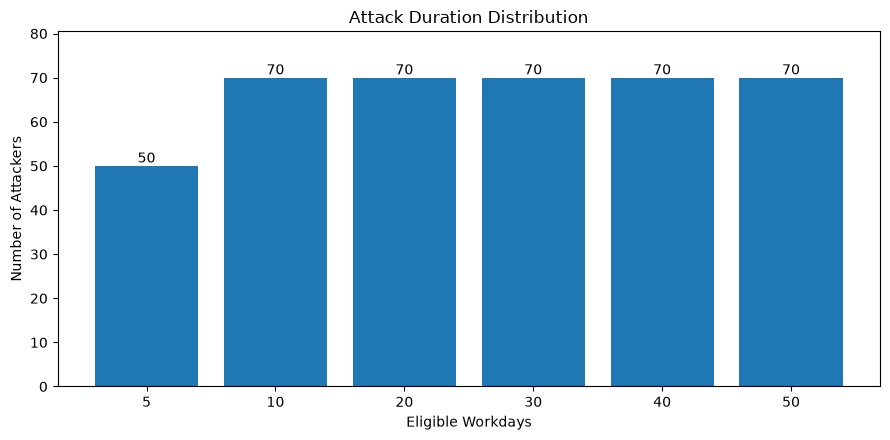

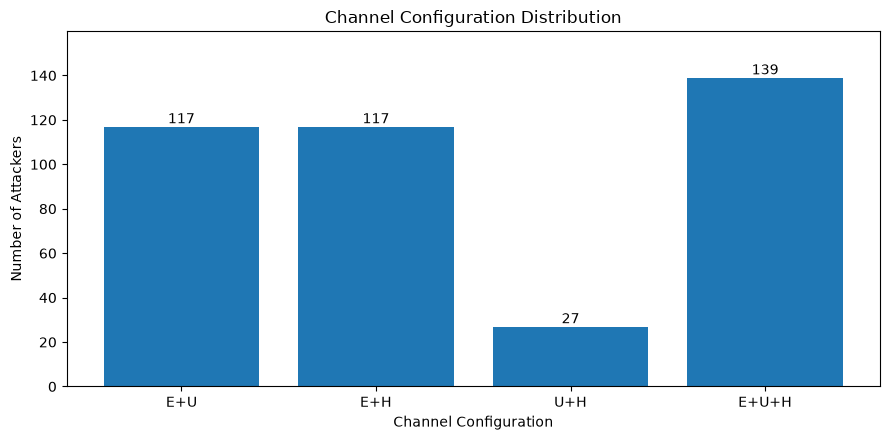

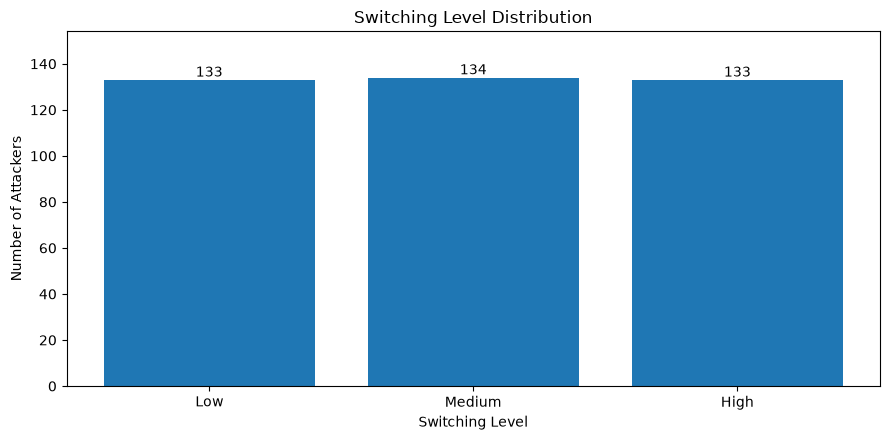

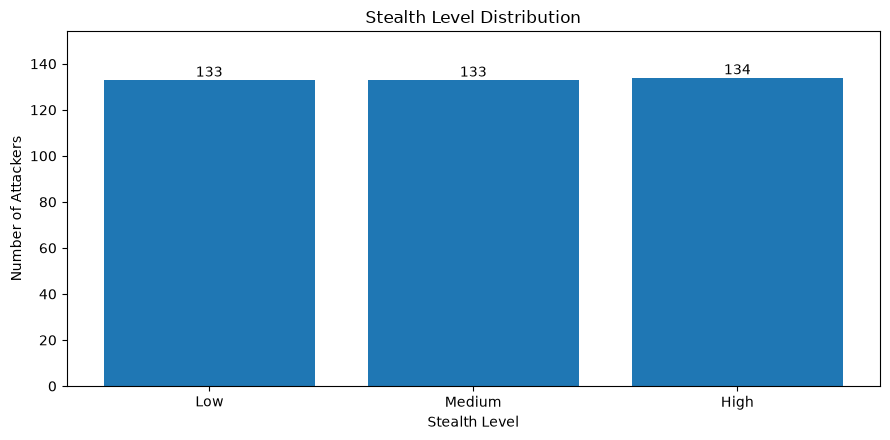

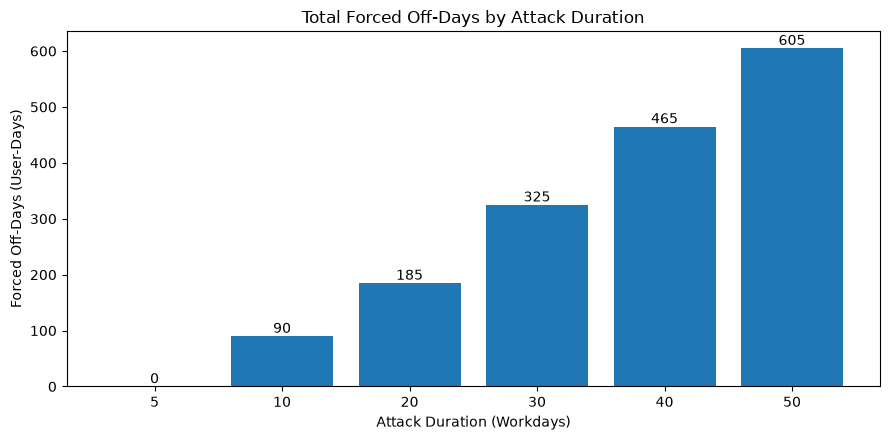

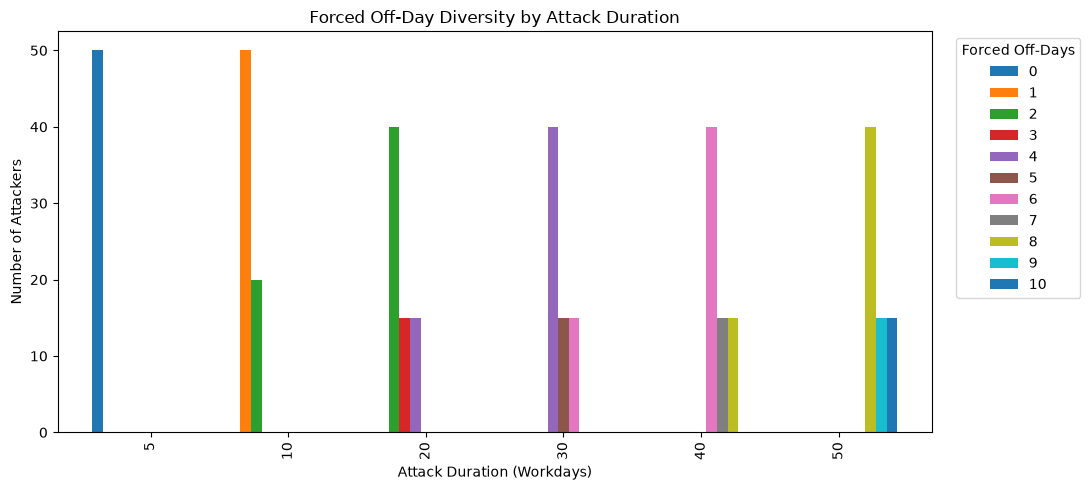

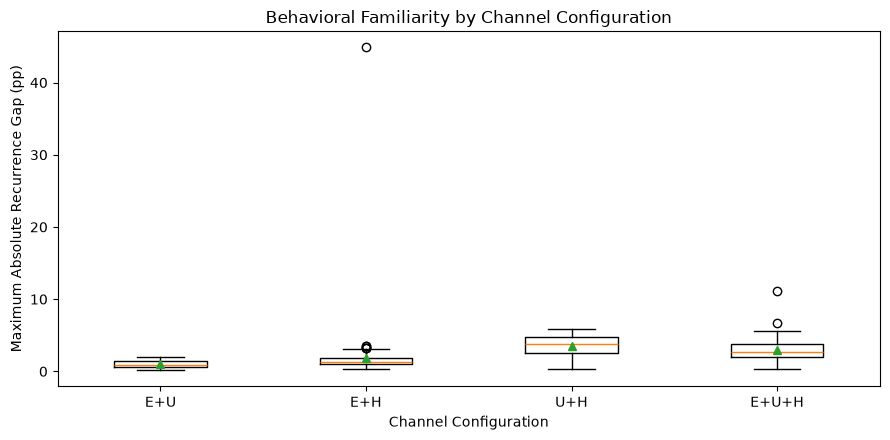

STEP 9 — Seven separate visualizations: PASS

ASSIGNMENT QUALITY QA


,check,status
0,Exactly 400 unique attackers,PASS
1,Unique scenario option IDs,PASS
2,Exact dimension targets,PASS
3,Extended-duration representation,PASS
4,Zero five-day Forced Off-Days,PASS
5,Duration-based Off-Day compliance,PASS
6,Off-Day distribution reconciles to 400,PASS
7,Off-Day totals reconcile,PASS
8,Soft diversity shortfall reconciles,PASS
9,Valid behavioral familiarity,PASS



NOTEBOOK 08 — SECTION 8.5.4 SUMMARY
Attackers audited          : 400
Extended-duration attackers: 210
E+U+H attackers            : 139
U+H attackers              : 27
Triple-eligible unselected : 115
Total Forced Off-Days      : 1670
Five-day Forced Off-Days   : 0
Off-Day categories         : 15/15
Soft diversity shortfall   : 0
Mean recurrence gap (pp)   : 2.076
Quality QA                 : 13/13 PASS
Independent source QA      : PENDING
Assignments modified       : NO
Files saved                : NO
SECTION 8.5.4 — PASS


In [37]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.5.4
# PROVISIONAL ASSIGNMENT QUALITY & DIVERSITY AUDIT
#
# Read-only | No reassignment | No exports
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Prepare provisional assignments
# ------------------------------------------------------------

audit_0854 = (
    assigned_attacker_scenarios_provisional_08
    .copy(deep=True)
)

assert len(audit_0854) == 400
assert audit_0854["user"].is_unique
assert audit_0854["scenario_option_id"].is_unique

dimensions_0854 = [
    (
        "window_workdays",
        DURATION_TARGETS_08,
        "Attack Duration",
    ),
    (
        "channel_configuration",
        CHANNEL_TARGETS_08,
        "Channel Configuration",
    ),
    (
        "switching_level",
        SWITCHING_TARGETS_08,
        "Switching Level",
    ),
    (
        "stealth_level",
        STEALTH_TARGETS_08,
        "Stealth Level",
    ),
]

print("STEP 1 — Provisional assignments verified: PASS")


# ------------------------------------------------------------
# STEP 2 — Audit exact dimension targets
# ------------------------------------------------------------

distribution_rows_0854 = []

for column, targets, title in dimensions_0854:

    actual = audit_0854[column].value_counts()

    for category, target in targets.items():

        count = int(actual.get(category, 0))

        distribution_rows_0854.append({
            "dimension": title,
            "category": category,
            "target": target,
            "actual": count,
            "match": count == target,
        })

diversity_audit_08 = pd.DataFrame(
    distribution_rows_0854
)

assert diversity_audit_08["match"].all()

print("STEP 2 — All assignment distributions: PASS")


# ------------------------------------------------------------
# STEP 3 — Low-and-Slow duration representation
# ------------------------------------------------------------

long_duration_0854 = int(
    audit_0854["window_workdays"].ge(30).sum()
)

short_duration_0854 = int(
    audit_0854["window_workdays"].eq(5).sum()
)

assert long_duration_0854 == 210
assert short_duration_0854 == 50

print("\nLOW-AND-SLOW REPRESENTATION")
print("30–50 workday attackers :", long_duration_0854)
print("Share of population     :", f"{long_duration_0854 / 400:.1%}")
print("5-workday attackers     :", short_duration_0854)

print("STEP 3 — Duration representation: PASS")


# ------------------------------------------------------------
# STEP 4 — Forced Off-Day totals
# ------------------------------------------------------------

total_offdays_0854 = int(
    audit_0854["forced_offdays"].sum()
)

five_day_offdays_0854 = int(
    audit_0854.loc[
        audit_0854["window_workdays"].eq(5),
        "forced_offdays",
    ].sum()
)

offday_by_duration_08 = (
    audit_0854
    .groupby("window_workdays")
    .agg(
        attackers=("user", "size"),
        total_offdays=("forced_offdays", "sum"),
        mean_offdays=("forced_offdays", "mean"),
        users_with_offdays=(
            "forced_offdays",
            lambda s: int(s.gt(0).sum()),
        ),
    )
    .reindex(DURATION_TARGETS_08)
    .reset_index()
)

offday_by_channel_08 = (
    audit_0854
    .groupby("channel_configuration")
    .agg(
        attackers=("user", "size"),
        total_offdays=("forced_offdays", "sum"),
        mean_offdays=("forced_offdays", "mean"),
        users_with_offdays=(
            "forced_offdays",
            lambda s: int(s.gt(0).sum()),
        ),
    )
    .reindex(CHANNEL_TARGETS_08)
    .reset_index()
)

assert five_day_offdays_0854 == 0
assert total_offdays_0854 == total_offdays_0853

assert int(
    offday_by_duration_08["total_offdays"].sum()
) == total_offdays_0854

assert int(
    offday_by_channel_08["total_offdays"].sum()
) == total_offdays_0854

print("\nFORCED OFF-DAYS BY DURATION")
display(offday_by_duration_08.round(2))

print("\nFORCED OFF-DAYS BY CHANNEL")
display(offday_by_channel_08.round(2))

print("STEP 4 — Forced Off-Day totals: PASS")


# ------------------------------------------------------------
# STEP 5 — Forced Off-Day compliance and diversity
# ------------------------------------------------------------

offday_categories_valid_0854 = all(
    audit_0854.loc[
        audit_0854["window_workdays"].eq(duration),
        "forced_offdays",
    ].isin(allowed).all()
    for duration, allowed in ALLOWED_OFFDAYS_08.items()
)

assert offday_categories_valid_0854

offday_distribution_08 = (
    audit_0854
    .groupby(
        ["window_workdays", "forced_offdays"]
    )
    .agg(attackers=("user", "size"))
    .reset_index()
)

expected_pairs_0854 = [
    (duration, offdays)
    for duration, allowed in ALLOWED_OFFDAYS_08.items()
    for offdays in allowed
]

expected_index_0854 = pd.MultiIndex.from_tuples(
    expected_pairs_0854,
    names=["window_workdays", "forced_offdays"],
)

offday_distribution_08 = (
    offday_distribution_08
    .set_index(
        ["window_workdays", "forced_offdays"]
    )
    .reindex(
        expected_index_0854,
        fill_value=0,
    )
    .reset_index()
)

offday_distribution_08["soft_target"] = (
    offday_distribution_08["window_workdays"]
    .map(OFFDAY_DIVERSITY_FLOORS_08)
)

offday_distribution_08.loc[
    offday_distribution_08["window_workdays"].eq(5),
    "soft_target",
] = 0

offday_distribution_08["shortfall"] = (
    offday_distribution_08["soft_target"]
    - offday_distribution_08["attackers"]
).clip(lower=0)

offday_distribution_08["represented"] = (
    offday_distribution_08["attackers"].gt(0)
)

offday_distribution_08["weighted_offdays"] = (
    offday_distribution_08["attackers"]
    * offday_distribution_08["forced_offdays"]
)

offday_representation_08 = (
    offday_distribution_08
    .groupby("window_workdays")
    .agg(
        allowed_categories=("forced_offdays", "size"),
        represented_categories=("represented", "sum"),
        attackers=("attackers", "sum"),
        total_offdays=("weighted_offdays", "sum"),
        diversity_shortfall=("shortfall", "sum"),
    )
    .reset_index()
)

assert int(
    offday_distribution_08["attackers"].sum()
) == 400

assert int(
    offday_distribution_08["weighted_offdays"].sum()
) == total_offdays_0854

diversity_shortfall_0854 = int(
    offday_distribution_08["shortfall"].sum()
)

assert diversity_shortfall_0854 == total_shortfall_0853

print("\nFORCED OFF-DAY DIVERSITY")
display(
    offday_distribution_08[
        [
            "window_workdays",
            "forced_offdays",
            "attackers",
            "soft_target",
            "shortfall",
        ]
    ]
)

print("\nOFF-DAY REPRESENTATION BY DURATION")
display(offday_representation_08)

print("STEP 5 — Forced Off-Day diversity audited: PASS")


# ------------------------------------------------------------
# STEP 6 — Behavioral familiarity
# ------------------------------------------------------------

assert audit_0854[
    "max_abs_recurrence_gap_pp"
].notna().all()

familiarity_by_channel_08 = (
    audit_0854
    .groupby("channel_configuration")
    .agg(
        attackers=("user", "size"),
        mean_gap_pp=(
            "max_abs_recurrence_gap_pp",
            "mean",
        ),
        median_gap_pp=(
            "max_abs_recurrence_gap_pp",
            "median",
        ),
        p75_gap_pp=(
            "max_abs_recurrence_gap_pp",
            lambda s: s.quantile(0.75),
        ),
        maximum_gap_pp=(
            "max_abs_recurrence_gap_pp",
            "max",
        ),
    )
    .reindex(CHANNEL_TARGETS_08)
    .reset_index()
)

print("\nBEHAVIORAL FAMILIARITY BY CHANNEL")
display(familiarity_by_channel_08.round(2))

print(
    "\nOverall mean recurrence gap:",
    round(
        audit_0854["max_abs_recurrence_gap_pp"].mean(),
        3,
    ),
    "pp"
)

print("STEP 6 — Behavioral familiarity: PASS")


# ------------------------------------------------------------
# STEP 7 — Multi-channel representation
# ------------------------------------------------------------

triple_assigned_0854 = audit_0854.loc[
    audit_0854["channel_configuration"].eq("E+U+H")
]

uh_assigned_0854 = audit_0854.loc[
    audit_0854["channel_configuration"].eq("U+H")
]

selected_triple_population_0854 = (
    set(audit_0854["user"])
    & triple_users_0851
)

remaining_triple_population_0854 = (
    triple_users_0851
    - selected_triple_population_0854
)

triple_qa_0854 = {
    "139 E+U+H assignments":
        len(triple_assigned_0854) == 139,

    "27 U+H assignments":
        len(uh_assigned_0854) == 27,

    "166 selected triple-eligible users":
        len(selected_triple_population_0854) == 166,

    "115 unselected triple-eligible users":
        len(remaining_triple_population_0854) == 115,

    "E+U+H users have triple eligibility":
        set(triple_assigned_0854["user"]).issubset(
            triple_users_0851
        ),

    "U+H users have triple eligibility":
        set(uh_assigned_0854["user"]).issubset(
            triple_users_0851
        ),

    "Switching evidence retained":
        audit_0854["set_switch_bitmask"].notna().all(),
}

multi_channel_audit_08 = pd.DataFrame([
    {
        "check": name,
        "status": "PASS" if passed else "FAIL",
    }
    for name, passed in triple_qa_0854.items()
])

assert all(triple_qa_0854.values())

print("\nMULTI-CHANNEL REPRESENTATION QA")
display(multi_channel_audit_08)

print("STEP 7 — Multi-channel representation: PASS")


# ------------------------------------------------------------
# STEP 8 — Cross-dimensional diversity
# ------------------------------------------------------------

duration_channel_08 = pd.crosstab(
    audit_0854["window_workdays"],
    audit_0854["channel_configuration"],
).reindex(
    index=DURATION_TARGETS_08,
    columns=CHANNEL_TARGETS_08,
    fill_value=0,
)

channel_switching_08 = pd.crosstab(
    audit_0854["channel_configuration"],
    audit_0854["switching_level"],
).reindex(
    index=CHANNEL_TARGETS_08,
    columns=SWITCHING_TARGETS_08,
    fill_value=0,
)

channel_stealth_08 = pd.crosstab(
    audit_0854["channel_configuration"],
    audit_0854["stealth_level"],
).reindex(
    index=CHANNEL_TARGETS_08,
    columns=STEALTH_TARGETS_08,
    fill_value=0,
)

assert duration_channel_08.to_numpy().sum() == 400
assert channel_switching_08.to_numpy().sum() == 400
assert channel_stealth_08.to_numpy().sum() == 400

print("\nDURATION × CHANNEL")
display(duration_channel_08)

print("\nCHANNEL × SWITCHING")
display(channel_switching_08)

print("\nCHANNEL × STEALTH")
display(channel_stealth_08)

print("STEP 8 — Cross-dimensional diversity: PASS")


# ------------------------------------------------------------
# STEP 9 — Separate visualizations
# ------------------------------------------------------------

def plot_distribution_0854(column, targets, title, xlabel):

    counts = audit_0854[column].value_counts()

    categories = list(targets)
    values = [
        int(counts.get(category, 0))
        for category in categories
    ]

    plt.figure(figsize=(9, 4.5))

    bars = plt.bar(
        [str(category) for category in categories],
        values,
    )

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(value),
            ha="center",
            va="bottom",
        )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Number of Attackers")
    plt.ylim(0, max(values) * 1.15)

    plt.tight_layout()
    plt.show()


plot_distribution_0854(
    "window_workdays",
    DURATION_TARGETS_08,
    "Attack Duration Distribution",
    "Eligible Workdays",
)

plot_distribution_0854(
    "channel_configuration",
    CHANNEL_TARGETS_08,
    "Channel Configuration Distribution",
    "Channel Configuration",
)

plot_distribution_0854(
    "switching_level",
    SWITCHING_TARGETS_08,
    "Switching Level Distribution",
    "Switching Level",
)

plot_distribution_0854(
    "stealth_level",
    STEALTH_TARGETS_08,
    "Stealth Level Distribution",
    "Stealth Level",
)

# Forced Off-Days by duration.
plt.figure(figsize=(9, 4.5))

bars = plt.bar(
    offday_by_duration_08["window_workdays"].astype(str),
    offday_by_duration_08["total_offdays"],
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom",
    )

plt.title("Total Forced Off-Days by Attack Duration")
plt.xlabel("Attack Duration (Workdays)")
plt.ylabel("Forced Off-Days (User-Days)")
plt.tight_layout()
plt.show()


# Forced Off-Day diversity by duration.
offday_plot_0854 = (
    offday_distribution_08
    .pivot(
        index="window_workdays",
        columns="forced_offdays",
        values="attackers",
    )
    .fillna(0)
)

ax = offday_plot_0854.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.85,
)

ax.set_title(
    "Forced Off-Day Diversity by Attack Duration"
)
ax.set_xlabel("Attack Duration (Workdays)")
ax.set_ylabel("Number of Attackers")
ax.legend(
    title="Forced Off-Days",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


# Behavioral familiarity by channel.
plt.figure(figsize=(9, 4.5))

plt.boxplot(
    [
        audit_0854.loc[
            audit_0854[
                "channel_configuration"
            ].eq(configuration),
            "max_abs_recurrence_gap_pp",
        ]
        for configuration in CHANNEL_TARGETS_08
    ],
    tick_labels=list(CHANNEL_TARGETS_08),
    showmeans=True,
)

plt.title(
    "Behavioral Familiarity by Channel Configuration"
)
plt.xlabel("Channel Configuration")
plt.ylabel("Maximum Absolute Recurrence Gap (pp)")
plt.tight_layout()
plt.show()

print("STEP 9 — Seven separate visualizations: PASS")


# ------------------------------------------------------------
# STEP 10 — Consolidated quality QA
# ------------------------------------------------------------

quality_checks_0854 = {
    "Exactly 400 unique attackers":
        len(audit_0854) == 400
        and audit_0854["user"].is_unique,

    "Unique scenario option IDs":
        audit_0854["scenario_option_id"].is_unique,

    "Exact dimension targets":
        diversity_audit_08["match"].all(),

    "Extended-duration representation":
        long_duration_0854 == 210,

    "Zero five-day Forced Off-Days":
        five_day_offdays_0854 == 0,

    "Duration-based Off-Day compliance":
        offday_categories_valid_0854,

    "Off-Day distribution reconciles to 400":
        int(
            offday_distribution_08["attackers"].sum()
        ) == 400,

    "Off-Day totals reconcile":
        int(
            offday_distribution_08[
                "weighted_offdays"
            ].sum()
        ) == total_offdays_0854,

    "Soft diversity shortfall reconciles":
        diversity_shortfall_0854
        == total_shortfall_0853,

    "Valid behavioral familiarity":
        audit_0854[
            "max_abs_recurrence_gap_pp"
        ].notna().all(),

    "Three-channel population preserved":
        len(selected_triple_population_0854) == 166
        and len(remaining_triple_population_0854) == 115,

    "Multi-channel representation checks":
        all(triple_qa_0854.values()),

    "Cross-dimensional totals reconcile":
        duration_channel_08.to_numpy().sum() == 400
        and channel_switching_08.to_numpy().sum() == 400
        and channel_stealth_08.to_numpy().sum() == 400,
}

assignment_quality_qa_08 = pd.DataFrame([
    {
        "check": name,
        "status": "PASS" if passed else "FAIL",
    }
    for name, passed in quality_checks_0854.items()
])

print("\nASSIGNMENT QUALITY QA")
display(assignment_quality_qa_08)

if not assignment_quality_qa_08[
    "status"
].eq("PASS").all():
    raise RuntimeError(
        "Provisional assignment quality QA failed."
    )


# ------------------------------------------------------------
# STEP 11 — Final summary
# ------------------------------------------------------------

represented_offday_categories_0854 = int(
    offday_distribution_08["represented"].sum()
)

total_allowed_categories_0854 = len(
    offday_distribution_08
)

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.5.4 SUMMARY")
print("=" * 65)

print("Attackers audited          :", len(audit_0854))
print("Extended-duration attackers:", long_duration_0854)
print("E+U+H attackers            :", len(triple_assigned_0854))
print("U+H attackers              :", len(uh_assigned_0854))
print(
    "Triple-eligible unselected :",
    len(remaining_triple_population_0854)
)
print("Total Forced Off-Days      :", total_offdays_0854)
print("Five-day Forced Off-Days   :", five_day_offdays_0854)
print(
    "Off-Day categories         :",
    f"{represented_offday_categories_0854}/"
    f"{total_allowed_categories_0854}"
)
print("Soft diversity shortfall   :", diversity_shortfall_0854)
print(
    "Mean recurrence gap (pp)   :",
    round(
        audit_0854[
            "max_abs_recurrence_gap_pp"
        ].mean(),
        3,
    )
)
print(
    "Quality QA                 :",
    f"{len(assignment_quality_qa_08)}/"
    f"{len(assignment_quality_qa_08)} PASS"
)
print("Independent source QA      : PENDING")
print("Assignments modified       : NO")
print("Files saved                : NO")
print("=" * 65)
print("SECTION 8.5.4 — PASS")



## 8.6 — Independent Source Cross-Validation & Final QA

### Objective

Independently validate the 400 provisional attacker-scenario assignments against the approved upstream structural evidence and the original daily behavioral data before final assignment approval.

### Validation Sources

1. **Notebook 07 — Approved Scenario Catalog:** Verify scenario provenance and preservation of selected scenario attributes.
2. **Notebook 05 — Structural Window Audit:** Independently reconcile selected users, attack windows, durations, Forced Off-Days, proposed active days, and structural feasibility.
3. **Original Daily Behavioral Features:** Recalculate activity-based Forced Off-Days directly from Email, USB, and HTTP event counts.

### Validation Methodology

#### 1. Scenario Provenance

Verify that each selected scenario option exists exactly once in the approved catalog and that all preserved attributes match their original values.

#### 2. Structural Window Reconciliation

Match every selected scenario against its approved structural window using the user, window duration, and window start date.

Validate window boundaries, structural eligibility, proposed active days, and Forced Off-Days.

#### 3. Independent Daily Activity Recalculation

Read the original daily behavioral records without modification.

For each selected attacker window:

- Identify all eligible workdays from the original daily source.
- Count days with at least one positive Email, USB, or HTTP event count.
- Count days without activity in all three channels as Forced Off-Days.
- Verify that the number of eligible workdays equals the selected attack duration.
- Confirm that the independently computed Forced Off-Days match the approved scenario values.
- Confirm that active days plus Forced Off-Days equal the selected attack duration.

Only event-frequency/count information is used. No data volumes or payload sizes are involved.

#### 4. Channel Availability

Confirm that every channel assigned to a scenario has at least one naturally active day within its approved window.

This verifies observed channel availability, not a completed daily attack schedule.

#### 5. Assignment Integrity

Verify the unique attacker population, exact duration, channel, switching, and stealth distributions, and the approved three-channel-eligible population allocation.

#### 6. Final QA

Produce a consolidated PASS/FAIL report.

Any missing source, mismatched window, inconsistent event count, invalid Off-Day count, or failed mandatory assignment check must block approval.

### Scope and Limitations

This section validates selected scenarios against their approved upstream evidence and the original daily activity records.

It does not independently reconstruct the full switching feasibility algorithm from Notebook 07, generate daily channel sequences, determine synchronization days, inject events, or export final assignments.

Daily scheduling and realized Channel Rotation/Synchronization remain the responsibility of Notebook 09.

### Expected Outcome

A traceable, read-only validation result for all 400 provisional assignments, establishing whether the selected scenarios are ready for final approval and export.


In [38]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.6
# INDEPENDENT SOURCE CROSS-VALIDATION & FINAL QA
#
# Read-only | No reassignment | No exports
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Verify provisional assignment inputs
# ------------------------------------------------------------

selected_086 = (
    assigned_attacker_scenarios_provisional_08
    .copy(deep=True)
)

assert len(selected_086) == 400
assert selected_086["user"].is_unique
assert selected_086["scenario_option_id"].is_unique

WINDOW_KEYS_086 = [
    "user",
    "window_workdays",
    "window_start",
]

COUNT_COLS_086 = [
    "external_email_count",
    "usb_copy_count",
    "www_upload_count",
]

CHANNEL_COUNTS_086 = {
    "E": "external_email_count",
    "U": "usb_copy_count",
    "H": "www_upload_count",
}

for col in ["window_start", "window_end"]:
    selected_086[col] = pd.to_datetime(
        selected_086[col]
    ).dt.normalize()

assert selected_086[
    ["window_start", "window_end"]
].notna().all().all()

print("STEP 1 — Provisional assignments: PASS")


# ------------------------------------------------------------
# STEP 2 — Locate independent upstream sources
# ------------------------------------------------------------

STRUCTURAL_PATH_086 = (
    ROOT_08
    / "reports"
    / "05_Simulation_Rules_Feasibility"
    / "integrated_structural_window_audit.parquet"
)

DAILY_PATH_086 = (
    ROOT_08.parent
    / "Data_Engineering"
    / "Data_engineering"
    / "data"
    / "features"
    / "behavior_features_r62_v1.parquet"
)

SOURCES_086 = {
    "Notebook 05 structural windows": STRUCTURAL_PATH_086,
    "Original daily behavioral features": DAILY_PATH_086,
}

for name, path in SOURCES_086.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name}:\n{path}"
        )

print("\nINDEPENDENT VALIDATION SOURCES")
for name, path in SOURCES_086.items():
    print(f"{name}: {path}")

print("STEP 2 — Source files located: PASS")


# ------------------------------------------------------------
# STEP 3 — Verify approved catalog provenance
# ------------------------------------------------------------

catalog_086 = scenario_catalog_08.loc[
    scenario_catalog_08["scenario_option_id"].isin(
        selected_086["scenario_option_id"]
    )
].copy()

assert len(catalog_086) == 400
assert catalog_086["scenario_option_id"].is_unique

for col in ["window_start", "window_end"]:
    catalog_086[col] = pd.to_datetime(
        catalog_086[col]
    ).dt.normalize()

# Compare every original catalog column.
catalog_columns_086 = list(scenario_catalog_08.columns)

provenance_086 = selected_086[
    catalog_columns_086
].merge(
    catalog_086,
    on="scenario_option_id",
    how="outer",
    suffixes=("_selected", "_source"),
    indicator=True,
    validate="one_to_one",
)

assert len(provenance_086) == 400
assert provenance_086["_merge"].eq("both").all()

catalog_mismatches_086 = {}

for col in catalog_columns_086:

    if col == "scenario_option_id":
        continue

    left = provenance_086[f"{col}_selected"]
    right = provenance_086[f"{col}_source"]

    if pd.api.types.is_numeric_dtype(left) and (
        pd.api.types.is_numeric_dtype(right)
    ):
        matches = np.isclose(
            left.to_numpy(dtype=float),
            right.to_numpy(dtype=float),
            rtol=0,
            atol=0,
            equal_nan=True,
        )
    else:
        matches = (
            left.astype("string")
            .fillna("<MISSING>")
            .eq(
                right.astype("string")
                .fillna("<MISSING>")
            )
            .to_numpy(dtype=bool)
        )

    catalog_mismatches_086[col] = int(
        (~matches).sum()
    )

catalog_provenance_pass_086 = (
    all(v == 0 for v in catalog_mismatches_086.values())
)

if not catalog_provenance_pass_086:
    display(pd.DataFrame([
        {"column": k, "mismatches": v}
        for k, v in catalog_mismatches_086.items()
        if v > 0
    ]))
    raise AssertionError(
        "Selected scenario attributes differ "
        "from the approved Notebook 07 catalog."
    )

print("STEP 3 — Full catalog provenance: PASS")


# ------------------------------------------------------------
# STEP 4 — Reconcile against Notebook 05
# structural window evidence
# ------------------------------------------------------------

structural_columns_086 = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "structural_pass",
    "forced_offdays",
    "proposed_active_days",
]

structural_086 = pd.read_parquet(
    STRUCTURAL_PATH_086,
    columns=structural_columns_086,
)

for col in ["window_start", "window_end"]:
    structural_086[col] = pd.to_datetime(
        structural_086[col]
    ).dt.normalize()

assert not structural_086.duplicated(
    WINDOW_KEYS_086
).any()

structural_match_086 = selected_086[
    WINDOW_KEYS_086
    + [
        "window_end",
        "forced_offdays",
        "proposed_active_days",
    ]
].merge(
    structural_086,
    on=WINDOW_KEYS_086,
    how="left",
    suffixes=("_selected", "_source"),
    indicator=True,
    validate="many_to_one",
)

assert len(structural_match_086) == 400
assert structural_match_086["_merge"].eq("both").all()
assert structural_match_086["structural_pass"].eq(True).all()

assert (
    structural_match_086["window_end_selected"]
    == structural_match_086["window_end_source"]
).all()

assert (
    structural_match_086["forced_offdays_selected"]
    == structural_match_086["forced_offdays_source"]
).all()

assert (
    structural_match_086["proposed_active_days_selected"]
    == structural_match_086["proposed_active_days_source"]
).all()

print("STEP 4 — Notebook 05 structural evidence: PASS")


# ------------------------------------------------------------
# STEP 5 — Load ORIGINAL daily behavioral features
#
# Event counts only. No sizes, bytes, or volumes.
# ------------------------------------------------------------

daily_086 = pd.read_parquet(
    DAILY_PATH_086,
    columns=["user", "day"] + COUNT_COLS_086,
)

daily_086 = daily_086.loc[
    daily_086["user"].isin(selected_086["user"])
].copy()

daily_086["day"] = pd.to_datetime(
    daily_086["day"]
).dt.normalize()

assert not daily_086.duplicated(
    ["user", "day"]
).any()

assert daily_086[
    ["user", "day"] + COUNT_COLS_086
].notna().all().all()

assert daily_086[COUNT_COLS_086].ge(0).all().all()

daily_086 = daily_086.sort_values(
    ["user", "day"]
).reset_index(drop=True)

daily_groups_086 = {
    user: group
    for user, group in daily_086.groupby("user")
}

assert set(selected_086["user"]).issubset(
    set(daily_groups_086)
)

print("STEP 5 — Original daily source loaded: PASS")
print("Selected-user daily rows:", f"{len(daily_086):,}")


# ------------------------------------------------------------
# STEP 6 — Independently reconstruct selected windows
#
# Forced Off-Day:
# No positive E, U, or H event count on an eligible day.
#
# No daily schedule or channel assignment is generated.
# ------------------------------------------------------------

daily_validation_rows_086 = []

for record in selected_086.itertuples(index=False):

    user = record.user
    duration = int(record.window_workdays)

    start = pd.Timestamp(record.window_start)
    end = pd.Timestamp(record.window_end)

    group = daily_groups_086[user]

    window = group.loc[
        group["day"].between(
            start,
            end,
            inclusive="both",
        )
    ]

    counts = window[COUNT_COLS_086]

    activity = counts.gt(0)

    available_days = int(
        activity.any(axis=1).sum()
    )

    forced_offdays = int(
        (~activity.any(axis=1)).sum()
    )

    observed_workdays = len(window)

    observed_channels = {
        channel
        for channel, column in CHANNEL_COUNTS_086.items()
        if activity[column].any()
    }

    required_channels = set(
        record.channel_configuration.split("+")
    )

    selected_channels_present = (
        required_channels.issubset(
            observed_channels
        )
    )

    complete_window = (
        observed_workdays == duration
        and not window.empty
        and window["day"].iloc[0] == start
        and window["day"].iloc[-1] == end
    )

    daily_validation_rows_086.append({
        "user": user,
        "scenario_option_id": record.scenario_option_id,
        "window_workdays": duration,
        "observed_workdays": observed_workdays,
        "selected_forced_offdays": int(
            record.forced_offdays
        ),
        "recomputed_forced_offdays": forced_offdays,
        "selected_active_days": int(
            record.proposed_active_days
        ),
        "recomputed_active_days": available_days,
        "complete_window": complete_window,
        "forced_offdays_match": (
            forced_offdays == int(record.forced_offdays)
        ),
        "active_days_match": (
            available_days == int(
                record.proposed_active_days
            )
        ),
        "selected_channels_present":
            selected_channels_present,
        "offday_active_reconciliation": (
            forced_offdays + available_days == duration
        ),
    })

daily_validation_08 = pd.DataFrame(
    daily_validation_rows_086
)

assert len(daily_validation_08) == 400
assert daily_validation_08["user"].is_unique

daily_check_columns_086 = [
    "complete_window",
    "forced_offdays_match",
    "active_days_match",
    "selected_channels_present",
    "offday_active_reconciliation",
]

print("\nINDEPENDENT DAILY VALIDATION")
display(pd.DataFrame([
    {
        "check": column,
        "passed_users": int(
            daily_validation_08[column].sum()
        ),
        "failed_users": int(
            (~daily_validation_08[column]).sum()
        ),
    }
    for column in daily_check_columns_086
]))

daily_validation_pass_086 = (
    daily_validation_08[daily_check_columns_086]
    .all()
    .all()
)

if not daily_validation_pass_086:
    print("\nFAILED USER WINDOWS")
    display(
        daily_validation_08.loc[
            ~daily_validation_08[
                daily_check_columns_086
            ].all(axis=1)
        ].head(30)
    )

    raise AssertionError(
        "Independent daily validation failed. "
        "Final approval is blocked."
    )

print("STEP 6 — Independent daily reconstruction: PASS")


# ------------------------------------------------------------
# STEP 7 — Verify duration-based Off-Day rules
# and assignment distribution
# ------------------------------------------------------------

offday_rules_pass_086 = all(
    selected_086.loc[
        selected_086["window_workdays"].eq(duration),
        "forced_offdays",
    ].isin(allowed).all()
    for duration, allowed in ALLOWED_OFFDAYS_08.items()
)

assert offday_rules_pass_086

distribution_rows_086 = []

for column, targets in [
    ("window_workdays", DURATION_TARGETS_08),
    ("channel_configuration", CHANNEL_TARGETS_08),
    ("switching_level", SWITCHING_TARGETS_08),
    ("stealth_level", STEALTH_TARGETS_08),
]:
    actual = selected_086[column].value_counts()

    for category, expected in targets.items():

        observed = int(actual.get(category, 0))

        distribution_rows_086.append({
            "dimension": column,
            "category": category,
            "expected": expected,
            "observed": observed,
            "match": expected == observed,
        })

distribution_validation_08 = pd.DataFrame(
    distribution_rows_086
)

distribution_pass_086 = (
    distribution_validation_08["match"].all()
)

assert distribution_pass_086

selected_triple_users_086 = (
    set(selected_086["user"])
    & triple_users_0851
)

triple_population_pass_086 = (
    len(selected_triple_users_086) == 166
    and len(
        triple_users_0851
        - selected_triple_users_086
    ) == 115
    and set(
        selected_086.loc[
            selected_086["channel_configuration"]
            .isin(["E+U+H", "U+H"]),
            "user",
        ]
    ) == selected_triple_users_086
)

assert triple_population_pass_086

print("STEP 7 — Assignment constraints: PASS")


# ------------------------------------------------------------
# STEP 8 — Selected switching and stealth
# evidence preservation
#
# This checks approved evidence and metadata.
# It does NOT recompute the full switching DP.
# ------------------------------------------------------------

switching_evidence_pass_086 = (
    selected_086["set_switch_bitmask"].notna().all()
    and selected_086["set_switch_bitmask"].gt(0).all()
    and selected_086["proof_source"].notna().all()
)

stealth_metadata_pass_086 = (
    selected_086["formula_id"].eq("A").all()
    and selected_086[
        "multiplier_configuration"
    ].eq("Balanced").all()
    and selected_086["stealth_multiplier"].notna().all()
)

assert switching_evidence_pass_086
assert stealth_metadata_pass_086

print("STEP 8 — Approved feasibility metadata: PASS")


# ------------------------------------------------------------
# STEP 9 — Consolidated Final QA
# ------------------------------------------------------------

qa_checks_086 = {
    "400 unique attackers":
        len(selected_086) == 400
        and selected_086["user"].is_unique,

    "Unique approved scenario IDs":
        selected_086["scenario_option_id"].is_unique,

    "Full Notebook 07 catalog provenance":
        catalog_provenance_pass_086,

    "Notebook 05 structural window matching":
        structural_match_086["_merge"].eq("both").all(),

    "All structural eligibility flags valid":
        structural_match_086["structural_pass"].eq(True).all(),

    "Original daily windows complete":
        daily_validation_08["complete_window"].all(),

    "Forced Off-Days independently match":
        daily_validation_08["forced_offdays_match"].all(),

    "Active days independently match":
        daily_validation_08["active_days_match"].all(),

    "All selected channels naturally present":
        daily_validation_08[
            "selected_channels_present"
        ].all(),

    "Off-Day and active-day totals reconcile":
        daily_validation_08[
            "offday_active_reconciliation"
        ].all(),

    "Approved duration Off-Day rules":
        offday_rules_pass_086,

    "Exact assignment distributions":
        distribution_pass_086,

    "Triple-eligible population allocation":
        triple_population_pass_086,

    "Approved switching evidence preserved":
        switching_evidence_pass_086,

    "Approved stealth metadata preserved":
        stealth_metadata_pass_086,
}

independent_source_qa_08 = pd.DataFrame([
    {
        "check": check,
        "status": "PASS" if bool(passed) else "FAIL",
    }
    for check, passed in qa_checks_086.items()
])

print("\nFINAL INDEPENDENT SOURCE QA")
display(independent_source_qa_08)

all_qa_pass_086 = (
    independent_source_qa_08["status"]
    .eq("PASS")
    .all()
)

if not all_qa_pass_086:
    raise RuntimeError(
        "Final source validation failed. "
        "Assignment approval and export are blocked."
    )


# ------------------------------------------------------------
# STEP 10 — Final validation summary
# ------------------------------------------------------------

validated_assignments_08 = (
    selected_086.copy(deep=True)
)

validated_assignments_08[
    "source_validation_status"
] = "SOURCE_QA_PASS"

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.6 SUMMARY")
print("=" * 65)

print("Assignments validated   :", len(validated_assignments_08))
print("Catalog provenance       : PASS")
print("Structural reconciliation: PASS")
print("Independent daily checks : PASS")
print(
    "Recomputed Forced Off-Days:",
    int(
        daily_validation_08[
            "recomputed_forced_offdays"
        ].sum()
    )
)
print(
    "Selected Forced Off-Days  :",
    int(selected_086["forced_offdays"].sum())
)
print(
    "Final source QA           :",
    f"{len(independent_source_qa_08)}/"
    f"{len(independent_source_qa_08)} PASS"
)
print("Assignment status         : SOURCE-VALIDATED")
print("Daily scheduling          : NOT PERFORMED")
print("Switching DP recomputation: NOT PERFORMED")
print("Files saved               : NO")
print("Original files modified   : NO")
print("=" * 65)

print("SECTION 8.6 — PASS")


STEP 1 — Provisional assignments: PASS

INDEPENDENT VALIDATION SOURCES
Notebook 05 structural windows: C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\reports\05_Simulation_Rules_Feasibility\integrated_structural_window_audit.parquet
Original daily behavioral features: C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\Data_Engineering\Data_engineering\data\features\behavior_features_r62_v1.parquet
STEP 2 — Source files located: PASS
STEP 3 — Full catalog provenance: PASS
STEP 4 — Notebook 05 structural evidence: PASS
STEP 5 — Original daily source loaded: PASS
Selected-user daily rows: 41,642

INDEPENDENT DAILY VALIDATION


,check,passed_users,failed_users
0,complete_window,400,0
1,forced_offdays_match,400,0
2,active_days_match,400,0
3,selected_channels_present,400,0
4,offday_active_reconciliation,400,0


STEP 6 — Independent daily reconstruction: PASS
STEP 7 — Assignment constraints: PASS
STEP 8 — Approved feasibility metadata: PASS

FINAL INDEPENDENT SOURCE QA


,check,status
0,400 unique attackers,PASS
1,Unique approved scenario IDs,PASS
2,Full Notebook 07 catalog provenance,PASS
3,Notebook 05 structural window matching,PASS
4,All structural eligibility flags valid,PASS
5,Original daily windows complete,PASS
6,Forced Off-Days independently match,PASS
7,Active days independently match,PASS
8,All selected channels naturally present,PASS
9,Off-Day and active-day totals reconcile,PASS



NOTEBOOK 08 — SECTION 8.6 SUMMARY
Assignments validated   : 400
Catalog provenance       : PASS
Structural reconciliation: PASS
Independent daily checks : PASS
Recomputed Forced Off-Days: 1670
Selected Forced Off-Days  : 1670
Final source QA           : 15/15 PASS
Assignment status         : SOURCE-VALIDATED
Daily scheduling          : NOT PERFORMED
Switching DP recomputation: NOT PERFORMED
Files saved               : NO
Original files modified   : NO
SECTION 8.6 — PASS



## 8.7 — Final Assignment Approval & Controlled Export

### Objective

Approve and export the 400 attacker-scenario assignments following successful independent source validation.

This stage prepares the official Notebook 08 handoff for daily attack scheduling in Notebook 09.

### Approval Requirements

Export is allowed only when:

1. Exactly 400 unique attackers have been assigned.
2. All duration, channel, switching, and stealth targets are satisfied.
3. All assignments originate from the approved Notebook 07 scenario catalog.
4. The assignment quality audit passes.
5. All independent source-validation checks pass.
6. Forced Off-Days and active days match the original daily source.
7. The three-channel-eligible population allocation is preserved.

### Export Directory

All outputs are saved directly to:

`reports/08_Attacker_Selection_and_Scenario_Assignment/`

No additional final subdirectory is created.

### Export Artifacts

| File | Purpose |
|---|---|
| `approved_attacker_scenarios_r62.parquet` | Primary approved assignment handoff to Notebook 09 |
| `approved_attacker_scenarios_r62.csv` | Human-readable assignment copy |
| `assignment_distribution_qa.csv` | Final distribution verification |
| `forced_offday_distribution.csv` | Forced Off-Day counts and diversity |
| `assignment_quality_qa.csv` | Assignment quality checks |
| `independent_source_qa.csv` | Independent source-validation checks |
| `independent_daily_validation.csv` | Per-user daily validation evidence |
| `assignment_data_dictionary.csv` | Assignment field definitions and data types |
| `notebook_summary.md` | Final methodology and results summary |
| `export_manifest.json` | Export metadata and SHA-256 file checksums |

### Controlled Export Procedure

1. Validate all approval prerequisites.
2. Create an approved copy of the validated assignments.
3. Recheck exact assignment targets and Forced Off-Day totals.
4. Generate the final reports and assignment data dictionary.
5. Stage all artifacts and verify their contents.
6. Check the output directory for conflicting filenames.
7. Publish the staged files without overwriting existing files.
8. Record file checksums and verify the completed export.

An existing target filename blocks the export. A failed export must not alter existing report files.

### Scope

This section does not recalculate the Baseline, change assigned scenarios, generate daily attack schedules, inject events, or determine channel synchronization.

### Expected Outcome

Ten verified export artifacts containing the approved 400-attacker assignments and the supporting validation evidence.

The Parquet assignment file becomes the primary input to Notebook 09.


In [41]:

# ============================================================
# NOTEBOOK 08 — SECTION 8.7
# FINAL ASSIGNMENT APPROVAL & CONTROLLED EXPORT
#
# Destination: REPORT_08 directly (no "final" folder)
# No overwrite | No source modification
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import shutil
import tempfile

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Verify approval prerequisites
# ------------------------------------------------------------

required_names_087 = [
    "validated_assignments_08",
    "assigned_attacker_scenarios_provisional_08",
    "assignment_quality_qa_08",
    "independent_source_qa_08",
    "daily_validation_08",
    "offday_distribution_08",
    "all_qa_pass_086",
    "ALLOWED_OFFDAYS_08",
    "CHANNEL_TARGETS_08",
    "DURATION_TARGETS_08",
    "SWITCHING_TARGETS_08",
    "STEALTH_TARGETS_08",
    "triple_users_0851",
    "scenario_catalog_08",
    "REPORT_08",
]

missing_087 = [
    name for name in required_names_087
    if name not in globals()
]

if missing_087:
    raise RuntimeError(
        "Missing prerequisites: " + ", ".join(missing_087)
    )

if not bool(all_qa_pass_086):
    raise RuntimeError("Section 8.6 validation failed.")

if not assignment_quality_qa_08["status"].eq("PASS").all():
    raise RuntimeError("Section 8.5.4 QA failed.")

if not independent_source_qa_08["status"].eq("PASS").all():
    raise RuntimeError("Section 8.6 source QA failed.")

if len(independent_source_qa_08) != 15:
    raise RuntimeError("Expected 15 independent source checks.")

if len(daily_validation_08) != 400:
    raise RuntimeError("Incomplete daily validation.")

daily_check_cols_087 = [
    "complete_window",
    "forced_offdays_match",
    "active_days_match",
    "selected_channels_present",
    "offday_active_reconciliation",
]

if not daily_validation_08[daily_check_cols_087].all().all():
    raise RuntimeError("Daily source validation failed.")

print("STEP 1 — Approval prerequisites: PASS")


# ------------------------------------------------------------
# STEP 2 — Prepare approved assignments
# ------------------------------------------------------------

approved_assignments_08 = (
    validated_assignments_08
    .copy(deep=True)
    .sort_values(["user", "scenario_option_id"])
    .reset_index(drop=True)
)

assert len(approved_assignments_08) == 400
assert approved_assignments_08["user"].is_unique
assert approved_assignments_08["scenario_option_id"].is_unique

assert approved_assignments_08[
    "source_validation_status"
].eq("SOURCE_QA_PASS").all()

# Verify approval does not alter the selected scenarios.
provisional_087 = (
    assigned_attacker_scenarios_provisional_08
    .sort_values(["user", "scenario_option_id"])
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    approved_assignments_08[provisional_087.columns],
    provisional_087,
    check_dtype=False,
)

approved_assignments_08["assignment_status"] = "APPROVED"

# Confirm source catalog membership.
catalog_ids_087 = set(
    scenario_catalog_08["scenario_option_id"]
)

assert set(
    approved_assignments_08["scenario_option_id"]
).issubset(catalog_ids_087)

print("STEP 2 — Approved assignments prepared: PASS")


# ------------------------------------------------------------
# STEP 3 — Verify final distributions
# ------------------------------------------------------------

targets_087 = {
    "window_workdays": DURATION_TARGETS_08,
    "channel_configuration": CHANNEL_TARGETS_08,
    "switching_level": SWITCHING_TARGETS_08,
    "stealth_level": STEALTH_TARGETS_08,
}

distribution_rows_087 = []

for column, targets in targets_087.items():

    counts = approved_assignments_08[column].value_counts()

    for category, expected in targets.items():

        actual = int(counts.get(category, 0))

        distribution_rows_087.append({
            "dimension": column,
            "category": category,
            "expected": int(expected),
            "actual": actual,
            "status": (
                "PASS" if actual == expected else "FAIL"
            ),
        })

assignment_distribution_qa_08 = pd.DataFrame(
    distribution_rows_087
)

if not assignment_distribution_qa_08["status"].eq("PASS").all():
    raise RuntimeError("Assignment distribution mismatch.")

selected_triple_087 = (
    set(approved_assignments_08["user"])
    & triple_users_0851
)

assert len(selected_triple_087) == 166
assert len(triple_users_0851 - selected_triple_087) == 115

print("STEP 3 — Final distributions: PASS")


# ------------------------------------------------------------
# STEP 4 — Verify Forced Off-Day integrity
# ------------------------------------------------------------

for duration, allowed in ALLOWED_OFFDAYS_08.items():

    values = approved_assignments_08.loc[
        approved_assignments_08[
            "window_workdays"
        ].eq(duration),
        "forced_offdays",
    ]

    assert values.isin(allowed).all()

total_offdays_087 = int(
    approved_assignments_08["forced_offdays"].sum()
)

recomputed_offdays_087 = int(
    daily_validation_08[
        "recomputed_forced_offdays"
    ].sum()
)

assert total_offdays_087 == recomputed_offdays_087

assert int(
    (
        approved_assignments_08["forced_offdays"]
        + approved_assignments_08["proposed_active_days"]
    ).eq(
        approved_assignments_08["window_workdays"]
    ).sum()
) == 400

assert int(offday_distribution_08["attackers"].sum()) == 400

assert int(
    (
        offday_distribution_08["attackers"]
        * offday_distribution_08["forced_offdays"]
    ).sum()
) == total_offdays_087

print("STEP 4 — Forced Off-Day integrity: PASS")
print("Total Forced Off-Days:", total_offdays_087)


# ------------------------------------------------------------
# STEP 5 — Prepare supporting QA reports
# ------------------------------------------------------------

quality_export_087 = assignment_quality_qa_08.copy()
source_export_087 = independent_source_qa_08.copy()
daily_export_087 = daily_validation_08.copy()
offday_export_087 = offday_distribution_08.copy()
distribution_export_087 = assignment_distribution_qa_08.copy()

print("STEP 5 — Supporting reports prepared: PASS")


# ------------------------------------------------------------
# STEP 6 — Generate assignment data dictionary
# ------------------------------------------------------------

descriptions_087 = {
    "user": "Unique user identifier.",
    "scenario_option_id":
        "Unique identifier of the approved scenario option.",
    "scenario_type_id":
        "Identifier of the approved scenario type.",
    "window_workdays":
        "Number of eligible workdays in the attack window.",
    "window_start":
        "Start date of the approved attack window.",
    "window_end":
        "End date of the approved attack window.",
    "channel_configuration":
        "Approved Email, USB and/or HTTP channel set.",
    "channel_count":
        "Number of channels in the assigned configuration.",
    "switching_level":
        "Approved Low, Medium or High switching level.",
    "stealth_level":
        "Approved Low, Medium or High stealth level.",
    "stealth_multiplier":
        "Multiplier used for the approved stealth level.",
    "formula_id":
        "Identifier of the approved injection-count formula.",
    "multiplier_configuration":
        "Approved stealth multiplier configuration.",
    "forced_offdays":
        "Eligible workdays with no natural activity in the "
        "three considered channels; injection prohibited.",
    "proposed_active_days":
        "Attack workdays remaining after Forced Off-Days.",
    "set_switch_bitmask":
        "Approved channel-switching feasibility evidence.",
    "proof_source":
        "Source of the switching feasibility evidence.",
    "catalog_status":
        "Original scenario catalog approval status.",
    "max_abs_recurrence_gap_pp":
        "Maximum absolute channel recurrence gap "
        "relative to the historical reference, in pp.",
    "max_positive_recurrence_increase_pp":
        "Maximum positive recurrence increase, in pp.",
    "all_selected_channels_have_reference":
        "Whether selected channels have historical references.",
    "source_validation_status":
        "Independent source-validation status.",
    "assignment_status":
        "Final assignment approval status.",
}

assignment_data_dictionary_08 = pd.DataFrame([
    {
        "column": column,
        "dtype": str(approved_assignments_08[column].dtype),
        "description": descriptions_087.get(
            column,
            "Preserved field from the approved "
            "Notebook 07 scenario catalog.",
        ),
    }
    for column in approved_assignments_08.columns
])

assert len(assignment_data_dictionary_08) == len(
    approved_assignments_08.columns
)

print("STEP 6 — Data dictionary generated: PASS")
print("Dictionary fields:", len(assignment_data_dictionary_08))


# ------------------------------------------------------------
# STEP 7 — Generate Notebook 08 summary
# ------------------------------------------------------------

mean_gap_087 = float(
    approved_assignments_08[
        "max_abs_recurrence_gap_pp"
    ].mean()
)

represented_087 = int(
    offday_export_087["attackers"].gt(0).sum()
)

diversity_shortfall_087 = int(
    offday_export_087["shortfall"].sum()
)

summary_087 = f"""# Notebook 08 — Final Assignment Summary

## Project
Mubsir: AI-Based Detection of Channel-Rotating Low-and-Slow Insider Data Exfiltration

## Final Assignment
- Status: APPROVED
- Unique attackers: 400
- Selected triple-eligible users: 166
- Unselected triple-eligible users: 115

## Channel Configuration
{chr(10).join(f"- {k}: {v}" for k, v in CHANNEL_TARGETS_08.items())}

## Attack Duration
{chr(10).join(f"- {k} workdays: {v}" for k, v in DURATION_TARGETS_08.items())}

## Switching Distribution
{chr(10).join(f"- {k}: {v}" for k, v in SWITCHING_TARGETS_08.items())}

## Stealth Distribution
{chr(10).join(f"- {k}: {v}" for k, v in STEALTH_TARGETS_08.items())}

## Forced Off-Days
- Total Forced Off-Days: {total_offdays_087}
- Represented categories: {represented_087}/{len(offday_export_087)}
- Soft diversity shortfall: {diversity_shortfall_087}
- Original daily-source validation: 400/400

## Behavioral Familiarity
- Mean maximum absolute recurrence gap: {mean_gap_087:.3f} percentage points

## Quality Assurance
- Assignment quality checks: {len(quality_export_087)} PASS
- Independent source checks: {len(source_export_087)} PASS

## Limitations and Handoff
- No Baseline recalculation.
- No original dataset modification.
- No daily attack scheduling or event injection.
- Switching evidence is preserved, not fully recomputed here.
- Channel synchronization is not yet scheduled.
- Notebook 09 will perform daily attack scheduling.
"""

print("STEP 7 — Summary generated: PASS")


# ------------------------------------------------------------
# STEP 8 — Define export directory and filenames
# ------------------------------------------------------------

OUTPUT_DIR_087 = Path(REPORT_08).resolve()

EXPECTED_FILES_087 = [
    "approved_attacker_scenarios_r62.parquet",
    "approved_attacker_scenarios_r62.csv",
    "assignment_distribution_qa.csv",
    "forced_offday_distribution.csv",
    "assignment_quality_qa.csv",
    "independent_source_qa.csv",
    "independent_daily_validation.csv",
    "assignment_data_dictionary.csv",
    "notebook_summary.md",
    "export_manifest.json",
]

if len(EXPECTED_FILES_087) != 10:
    raise RuntimeError("Expected exactly ten output files.")

# Protect any existing outputs before writing.
conflicts_087 = [
    name for name in EXPECTED_FILES_087
    if (OUTPUT_DIR_087 / name).exists()
]

if conflicts_087:
    raise FileExistsError(
        "Export blocked. Existing files will not be "
        "overwritten:\n" + "\n".join(conflicts_087)
    )

print("STEP 8 — Destination and filenames: PASS")
print("Output directory:", OUTPUT_DIR_087)


# ------------------------------------------------------------
# STEP 9 — Stage and verify export files
# ------------------------------------------------------------

OUTPUT_DIR_087.mkdir(parents=True, exist_ok=True)

stage_087 = Path(
    tempfile.mkdtemp(
        prefix=".stage_08_",
        dir=OUTPUT_DIR_087,
    )
)


def sha256_file_087(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


published_087 = []

try:

    approved_assignments_08.to_parquet(
        stage_087 / EXPECTED_FILES_087[0],
        index=False,
    )

    approved_assignments_08.to_csv(
        stage_087 / EXPECTED_FILES_087[1],
        index=False,
    )

    distribution_export_087.to_csv(
        stage_087 / EXPECTED_FILES_087[2],
        index=False,
    )

    offday_export_087.to_csv(
        stage_087 / EXPECTED_FILES_087[3],
        index=False,
    )

    quality_export_087.to_csv(
        stage_087 / EXPECTED_FILES_087[4],
        index=False,
    )

    source_export_087.to_csv(
        stage_087 / EXPECTED_FILES_087[5],
        index=False,
    )

    daily_export_087.to_csv(
        stage_087 / EXPECTED_FILES_087[6],
        index=False,
    )

    assignment_data_dictionary_08.to_csv(
        stage_087 / EXPECTED_FILES_087[7],
        index=False,
    )

    (stage_087 / EXPECTED_FILES_087[8]).write_text(
        summary_087,
        encoding="utf-8",
    )

    # Reopen the main Parquet output.
    readback_087 = pd.read_parquet(
        stage_087 / EXPECTED_FILES_087[0]
    )

    # Normalize the user column before comparison.
    readback_087["user"] = readback_087["user"].astype("string")
    approved_check_087 = approved_assignments_08.copy()
    approved_check_087["user"] = approved_check_087["user"].astype("string")

    pd.testing.assert_frame_equal(
        readback_087,
        approved_check_087,
        check_dtype=False,
        check_exact=True,
)

    assert readback_087["user"].nunique() == 400

    assert int(
        readback_087["forced_offdays"].sum()
    ) == total_offdays_087

    # Record SHA-256 checksums for the nine data/report files.
    staged_names_087 = EXPECTED_FILES_087[:-1]

    manifest_087 = {
        "project": "Mubsir",
        "dataset_version": "r6.2",
        "notebook": "08_Attacker_Selection_and_Scenario_Assignment",
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "assignment_status": "APPROVED",
        "source_validation_status": "SOURCE_QA_PASS",
        "attackers": 400,
        "forced_offdays": total_offdays_087,
        "source_qa_checks": len(source_export_087),
        "quality_qa_checks": len(quality_export_087),
        "files": {
            name: {
                "size_bytes": (stage_087 / name).stat().st_size,
                "sha256": sha256_file_087(stage_087 / name),
            }
            for name in staged_names_087
        },
    }

    (stage_087 / EXPECTED_FILES_087[-1]).write_text(
        json.dumps(
            manifest_087,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    assert {
        path.name for path in stage_087.iterdir()
        if path.is_file()
    } == set(EXPECTED_FILES_087)

    # Publish without overwriting existing files.
    # os.link fails if a target name already exists.
    for name in EXPECTED_FILES_087:

        source = stage_087 / name
        destination = OUTPUT_DIR_087 / name

        os.link(source, destination)
        published_087.append(destination)

    # Verify published file integrity.
    for name in staged_names_087:

        actual_hash = sha256_file_087(
            OUTPUT_DIR_087 / name
        )

        expected_hash = manifest_087["files"][name]["sha256"]

        if actual_hash != expected_hash:
            raise RuntimeError(
                f"Checksum mismatch: {name}"
            )

except Exception:

    # Roll back only files published by this attempt.
    # Existing report files are never deleted.
    for path in reversed(published_087):
        path.unlink(missing_ok=True)

    raise

finally:
    # Remove temporary staging files only.
    shutil.rmtree(stage_087, ignore_errors=True)

print("STEP 9 — Controlled export and checksums: PASS")


# ------------------------------------------------------------
# STEP 10 — Final export summary
# ------------------------------------------------------------

export_audit_08 = pd.DataFrame([
    {
        "file": name,
        "size_bytes": (
            OUTPUT_DIR_087 / name
        ).stat().st_size,
        "status": "SAVED",
    }
    for name in EXPECTED_FILES_087
])

assert len(export_audit_08) == 10
assert all(
    (OUTPUT_DIR_087 / name).is_file()
    for name in EXPECTED_FILES_087
)

print("\nEXPORTED FILES")
display(export_audit_08)

print("\n" + "=" * 65)
print("NOTEBOOK 08 — SECTION 8.7 SUMMARY")
print("=" * 65)
print("Approved attackers        : 400")
print("Unique assigned users     : 400")
print("Total Forced Off-Days     :", total_offdays_087)
print("Represented Off-Day types :", represented_087)
print("Soft diversity shortfall  :", diversity_shortfall_087)
print("Assignment quality QA     :", len(quality_export_087), "PASS")
print("Independent source QA     :", len(source_export_087), "PASS")
print("Data dictionary fields    :", len(assignment_data_dictionary_08))
print("Exported files            :", len(export_audit_08))
print("Assignment status         : APPROVED")
print("Daily scheduling          : NOT PERFORMED")
print("Original files modified   : NO")
print("Output directory          :", OUTPUT_DIR_087)
print("=" * 65)
print("SECTION 8.7 — FINAL APPROVAL & EXPORT COMPLETE")


STEP 1 — Approval prerequisites: PASS
STEP 2 — Approved assignments prepared: PASS
STEP 3 — Final distributions: PASS
STEP 4 — Forced Off-Day integrity: PASS
Total Forced Off-Days: 1670
STEP 5 — Supporting reports prepared: PASS
STEP 6 — Data dictionary generated: PASS
Dictionary fields: 23
STEP 7 — Summary generated: PASS
STEP 8 — Destination and filenames: PASS
Output directory: C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\reports\08_Attacker_Selection_and_Scenario_Assignment
STEP 9 — Controlled export and checksums: PASS

EXPORTED FILES


,file,size_bytes,status
0,approved_attacker_scenarios_r62.parquet,32302,SAVED
1,approved_attacker_scenarios_r62.csv,81791,SAVED
2,assignment_distribution_qa.csv,594,SAVED
3,forced_offday_distribution.csv,428,SAVED
4,assignment_quality_qa.csv,504,SAVED
5,independent_source_qa.csv,623,SAVED
6,independent_daily_validation.csv,22962,SAVED
7,assignment_data_dictionary.csv,1787,SAVED
8,notebook_summary.md,1309,SAVED
9,export_manifest.json,1816,SAVED



NOTEBOOK 08 — SECTION 8.7 SUMMARY
Approved attackers        : 400
Unique assigned users     : 400
Total Forced Off-Days     : 1670
Represented Off-Day types : 15
Soft diversity shortfall  : 0
Assignment quality QA     : 13 PASS
Independent source QA     : 15 PASS
Data dictionary fields    : 23
Exported files            : 10
Assignment status         : APPROVED
Daily scheduling          : NOT PERFORMED
Original files modified   : NO
Output directory          : C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\reports\08_Attacker_Selection_and_Scenario_Assignment
SECTION 8.7 — FINAL APPROVAL & EXPORT COMPLETE
